# TG-Fog: Organisation-Aware Fog-Hierarchical Federated **Temporal-Graph** Learning for Privacy-Preserving, Poisoning- and Evasion-Resilient, Zero-Day-Aware IoT Intrusion Detection
 `Runtime → Run all` produces every table (CSV + LaTeX + one Excel workbook) and every figure (PNG 300 dpi + PDF)
used in the paper. **No number is typed by hand**; every result is cached on Google Drive, so a disconnected Colab session
resumes where it stopped.

### What is new compared with the submitted FedGraph-IDS manuscript
| Submitted manuscript | This notebook |
|---|---|
| k-NN *similarity* graph (not a network graph) | **real host-interaction graphs**: hosts = nodes, flows = directed edges, built per time window; **edge classification** |
| one training dataset + one test dataset | **three organisations = three datasets with different feature schemas** (TON_IoT, Edge-IIoTset, BoT-IoT); private per-organisation adapters, no hand-made feature mapping |
| FedProx + Gaussian noise "privacy" without accounting | **secure aggregation** (implemented, verified, timed) + **client-level DP with an RDP accountant** + **membership-inference audit** |
| no attacker model | **6 poisoning attacks × 6 fog-side defences** (incl. ALIE, IPM, backdoor) + **constraint-aware PGD** + **topology camouflage** + adversarial training and **federated** adversarial training |
| no zero-day evaluation | **leave-one-family-out** with 6 unknown-scores, centralised and federated |
| single numbers, "illustrative mean" | 5 seeds (centralised) / 3 seeds (federated), paired tests with Holm correction, Friedman + Nemenyi |
| no resource analysis | 1-thread CPU latency, int8 size and accuracy, activation memory, MACs, WAN/LAN traffic, parallel time |

### Claimed contributions (to be confirmed by the numbers this notebook produces)
1. **Organisation-aware fog federation for heterogeneous feature schemas** – private input adapters stay at each
   organisation's fog; only the graph body and head are shared.
2. **Temporal edge-conditioned graph model (TG-EGNN)** – directional attention over incident flows with temporal edge features.
3. **Fog-side temporal-reputation filtering** against data and model poisoning.
4. **Secure-aggregation-compatible sparsification** (shared random mask + error feedback) that cuts WAN traffic while the
   cloud still sees only the sum of the fogs' updates; optional client-level DP on top.

> **Honesty rules built into this notebook.** If the proposed method does not win on a metric, the tables show it.
> Do not cherry-pick seeds or edit numbers in the paper. The SELF_TEST mode runs on *synthetic* data only to check that
> all cells execute; its outputs go to a separate folder and every figure is watermarked "NOT FOR PAPER".

### How to run
1. Colab → GPU runtime (T4 is enough; A100/L4 is faster). Add your Kaggle API key once (Colab secrets `KAGGLE_USERNAME`/`KAGGLE_KEY`, or `kaggle.json` in MyDrive, or upload when asked); the datasets are then downloaded from Kaggle automatically (§C4, §1).
2. Optional: first set `SELF_TEST = True` and run all (≈10–20 min) to check the pipeline; then set it back to `False`.
3. Run all. Full runtime on a T4 is roughly 10–20 h (dominated by §6 poisoning: 6 attacks × 3 rates × 6 defences × 3 seeds).
   Everything is cached, so you can run it over several sessions. Reduce `BYZ_SEEDS`/`BYZ_ROUNDS` if time is short.

In [3]:
# ============================== K. KAGGLE CREDENTIALS ==============================
# First run: asks for kaggle.json once and saves a copy to MyDrive/kaggle.json.
# Later runs (or after a Colab disconnect) read it from Drive, so "Run all" never stops to wait for an upload.
import os, sys, json, shutil
from pathlib import Path
_IN_COLAB = "google.colab" in sys.modules
if _IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
_kd = Path.home() / ".kaggle"; _kd.mkdir(exist_ok=True); _kj = _kd / "kaggle.json"
_drive_kj = Path("/content/drive/MyDrive/kaggle.json")
if not _kj.exists():
    if _drive_kj.exists(): shutil.copy(_drive_kj, _kj)
    elif Path("kaggle.json").exists(): shutil.copy("kaggle.json", _kj)
    elif _IN_COLAB:
        from google.colab import files
        print("Upload kaggle.json (Kaggle -> Settings -> API -> Create New Token):")
        _up = files.upload()
        if _up: _kj.write_bytes(list(_up.values())[0])
if _kj.exists():
    os.chmod(_kj, 0o600)
    if _drive_kj.parent.exists() and not _drive_kj.exists(): shutil.copy(_kj, _drive_kj)
    _d = json.loads(_kj.read_text()); os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = _d["username"], _d["key"]
    print("Kaggle credentials ready for user:", _d["username"])   # the key itself is never printed
else:
    print("No kaggle.json yet - the downloader in C4 will ask again.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaggle credentials ready for user: ayeshasaadia


In [4]:
# ============================== 0. CONFIGURATION ==============================
# STAGE SWITCH: "Run all" stops by itself after this table, so GPU time is not spent on later experiments before the key
# results have been checked. "T08" = after configuration selection + main federated comparison (T08a, T08-T10);
# "T11" = also the federated ablation and sparsity sweep; "T08b" = also composition-augmented FL (§7b);
# None = run everything. Cached parts are reused on every run.
STOP_AFTER = None
SELF_TEST = False         # True = synthetic data, tiny settings, pipeline check only (NOT FOR PAPER)

CFG = dict(
    SELF_TEST=SELF_TEST, STOP_AFTER=STOP_AFTER, USE_DRIVE=True, DRIVE_OUT="/content/drive/MyDrive/TGFog_outputs", LOCAL_OUT="./TGFog_outputs",
    DATA_ROOT="/content/drive/MyDrive/IoT_Datasets", DATA_SOURCE="kaggle", COPY_TO_DRIVE=False, KAGGLE_MAX_GB=60, MANUAL_PATHS={}, DATASETS=["TON_IoT", "Edge-IIoTset", "BoT-IoT"],
    CLASS_CAP=60_000, CHUNK=500_000, MAX_ROWS_PER_FILE=None,
    SPLIT_BLOCK=512, SPLIT=(0.7, 0.1, 0.2), SPLIT_SEED=42,
    WIN=1024, WIN_CLIENT=256, WIN_BATCH=4, D=64, LAYERS=2, DROPOUT=0.1,
    SEEDS=[42, 43, 44, 45, 46], C_EPOCHS=30, C_LR=2e-3, PATIENCE=6,
    # federated
    FL_SEEDS=[42, 43, 44], K_PER_ORG=30, PARTITION="dirichlet", ALPHA=0.5, FRAC=0.2, MIN_SAMPLED=5,
    ROUNDS=40, FOG_ROUNDS=2, LOCAL_EPOCHS=1, LOCAL_LR=0.05, MU=0.01, SERVER_LR=1.0, SERVER_MOM=0.7, SPARSIFY=0.1, SPARSIFY_GRID=[0.1, 0.25, 1.0],
    REP_BETA=0.7, REP_MODE="hard", MASK_MODE="rotating", LOCAL_MOM=0.9, MU_FEDPROX=0.01, FL_VERSION="v2", FL_AUG=False, ROOT_FLOWS=512,
    # validation-based configuration selection (one tuning seed that is NOT one of the reported seeds; test data never used)
    TUNE=True, TUNE_SEED=7, TUNE_SERVER_MOM=[0.0, 0.7], TUNE_SPARSIFY=[0.1, 0.25, 1.0], TUNE_REP_MODE=["hard", "soft"],
    TUNE_MU_FEDPROX=[0.001, 0.01, 0.1], EVAL_EVERY=2, FL_VAL_WINDOWS=60,
    FL_ALGS=["FedAvg", "FedProx", "SCAFFOLD", "HierFAVG", "Proposed"],
    SCALE_K=[10, 30, 100], SCALE_ALGS=["FedAvg", "HierFAVG", "Proposed"], SCALE_FOGS=[1, 2, 4], SCALE_SEEDS=[42, 43],
    # privacy
    DP_EPS=[1, 4, 8], DP_CLIP=1.0, DP_CLIP_GRID=[0.05, 0.1, 0.25, 0.5, 1.0, 2.0], DP_TUNE_EPS=8, DP_POP_K=[100, 300], DP_POP_SEEDS=[42, 43], MIA_WIN=1000, CAMO_SEEDS=[42, 43, 44], DP_DELTA=1e-5, DP_K=100, DP_SEEDS=[42, 43, 44],
    # poisoning
    BYZ_ATTACKS=["label_flip", "backdoor", "alie", "ipm", "alie15", "ipm10"], BYZ_FRACS=[0.1, 0.3],
    BYZ_DEFENSES=["Mean", "Median", "TrimmedMean", "MultiKrum", "FLTrust", "Proposed", "Proposed+NB"], BYZ_SEEDS=[42, 43, 44], BYZ_K=30, BYZ_ROUNDS=30, BOOST=10.0,
    # zero-day / adversarial / resources
    ZD_SEEDS=[42, 43, 44], ZD_FL=True, ZD_TRAIN_WIN=200,
    ADV_EPS=[0.01, 0.03, 0.05, 0.1], ADV_STEPS=10, ADV_WIN=60, CAMO_M=[0, 2, 5, 10], LAT_REPS=50,
    SHOW_FIGS=True, VERBOSE_FL=False, FORCE_RERUN=False,
)
if SELF_TEST:
    CFG.update(CLASS_CAP=900, WIN=128, WIN_CLIENT=64, SPLIT_BLOCK=64, D=16, SEEDS=[42, 43], C_EPOCHS=2, PATIENCE=2,
               FL_SEEDS=[42, 43], K_PER_ORG=4, ROUNDS=2, TUNE_SPARSIFY=[0.25, 1.0], TUNE_SERVER_MOM=[0.0], TUNE_MU_FEDPROX=[0.01], FOG_ROUNDS=1, SPARSIFY_GRID=[0.1, 1.0], MIN_SAMPLED=2, EVAL_EVERY=1, FL_VAL_WINDOWS=4, ROOT_FLOWS=128,
               SCALE_K=[3, 5], SCALE_FOGS=[1, 2], SCALE_SEEDS=[42], DP_EPS=[2, 8], DP_K=4, DP_SEEDS=[42], DP_CLIP_GRID=[0.5, 1.0], DP_POP_K=[4, 8], MIA_WIN=50, DP_POP_SEEDS=[42], BYZ_ATTACKS=["label_flip", "backdoor", "alie"],
               BYZ_FRACS=[0.3], BYZ_DEFENSES=["Mean", "MultiKrum", "Proposed"], BYZ_SEEDS=[42], BYZ_K=4, BYZ_ROUNDS=2,
               ZD_SEEDS=[42], ZD_TRAIN_WIN=10, ADV_EPS=[0.05], ADV_STEPS=2, ADV_WIN=3, CAMO_M=[0, 2], LAT_REPS=3, SHOW_FIGS=False,
               DATA_ROOT="./selftest_data", USE_DRIVE=False, STOP_AFTER=None)

In [5]:
# ============================== 0b. PACKAGES ==============================
import subprocess, importlib, sys
for _m, _p in [("xgboost", "xgboost"), ("kagglehub", "kagglehub"), ("kaggle", "kaggle"), ("openpyxl", "openpyxl")]:
    try: importlib.import_module(_m)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", _p], check=False)

## C1. Shared core: persistence, registry, metrics, statistics
Everything below is generic and used by every experiment block. Nothing here contains a result.

In [6]:
# ============================== C1. CORE UTILITIES ==============================
import os, sys, gc, io, re, json, time, math, copy, glob, pickle, random, hashlib, warnings, itertools, zipfile, tracemalloc
from pathlib import Path
from collections import defaultdict, OrderedDict
import numpy as np, pandas as pd
import matplotlib as mpl
mpl.use(os.environ.get("MPLBACKEND", mpl.get_backend()))
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.special import logsumexp
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, matthews_corrcoef, precision_score,
                             recall_score, roc_auc_score, confusion_matrix, average_precision_score, roc_curve)
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")
try:
    import xgboost as xgb
except Exception:
    xgb = None

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and CFG.get("USE_DRIVE", True):
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path(CFG["DRIVE_OUT"])
else:
    OUT = Path(CFG.get("LOCAL_OUT", "./outputs"))
if CFG["SELF_TEST"]:
    OUT = OUT.parent / (OUT.name + "_SELFTEST_NOT_FOR_PAPER")
for sub in ["cache", "tables", "figures", "models", "ledger"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def cached(name, fn):
    """Run fn once and store its result; a re-run of the notebook reuses stored results (resume after a Colab disconnect)."""
    p = OUT / "cache" / (re.sub(r"[^A-Za-z0-9_.=-]+", "_", name) + ".pkl")
    if p.exists() and not CFG.get("FORCE_RERUN", False):
        with open(p, "rb") as f: return pickle.load(f)
    r = fn()
    with open(p, "wb") as f: pickle.dump(r, f)
    return r

TABLES, FIGS = OrderedDict(), OrderedDict()
WATERMARK = "SELF-TEST (synthetic data) - NOT FOR PAPER" if CFG["SELF_TEST"] else None

def add_table(name, df, caption, show=True, floatfmt=4):
    df = df.copy()
    TABLES[name] = (caption, df)
    df.to_csv(OUT / "tables" / f"{name}.csv", index=False)
    try:
        with open(OUT / "tables" / f"{name}.tex", "w") as f:
            f.write(df.to_latex(index=False, float_format=lambda v: f"{v:.{floatfmt}f}", caption=caption, label=f"tab:{name}", escape=True))
    except Exception:
        pass
    if show:
        print(f"\n=== Table [{name}] {caption}" + (f"  <<{WATERMARK}>>" if WATERMARK else ""))
        with pd.option_context("display.max_columns", 50, "display.width", 250, "display.max_rows", 200):
            print(df.to_string(index=False))
    return df

def save_fig(fig, name, caption):
    if WATERMARK:
        fig.text(0.5, 0.5, WATERMARK, fontsize=16, color="red", alpha=0.25, ha="center", va="center", rotation=25)
    FIGS[name] = caption
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / "figures" / f"{name}.pdf", bbox_inches="tight")
    plt.show() if CFG.get("SHOW_FIGS", True) else None
    plt.close(fig)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.titleweight": "bold", "pdf.fonttype": 42, "ps.fonttype": 42})
PAL = sns.color_palette("tab10", 12)
PROP_COLOR = "#C0392B"

# ---------------------------------------------------------------- metrics
def softmax_np(z, T=1.0):
    z = np.asarray(z, float) / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def metrics(y, prob, C=None, benign=0):
    """Multi-class metrics from probabilities. FPR = benign flows flagged as any attack; DR = attacks flagged as any attack."""
    y = np.asarray(y); prob = np.asarray(prob); C = C or prob.shape[1]; p = prob.argmax(1)
    out = dict(Acc=100 * accuracy_score(y, p), F1=100 * f1_score(y, p, average="macro", labels=np.unique(y), zero_division=0),
               wF1=100 * f1_score(y, p, average="weighted", zero_division=0), BA=100 * balanced_accuracy_score(y, p),
               MCC=matthews_corrcoef(y, p))
    yb, pb = (y != benign), (p != benign)
    out["FPR"] = 100 * (pb & ~yb).sum() / max(1, (~yb).sum())
    out["DR"] = 100 * (pb & yb).sum() / max(1, yb.sum())
    try:
        present = np.unique(y)
        if len(present) == 2 and C == 2: out["AUC"] = roc_auc_score(y, prob[:, 1])
        elif len(present) > 2:
            sub = prob[:, present] / np.clip(prob[:, present].sum(1, keepdims=True), 1e-12, None)
            out["AUC"] = roc_auc_score(y, sub, multi_class="ovr", labels=present)
        out["AUC_attack"] = roc_auc_score(yb.astype(int), 1 - prob[:, benign])
    except Exception:
        pass
    out["per_class_F1"] = {int(c): 100 * f1_score(y == c, p == c, zero_division=0) for c in np.unique(y)}
    return out

def ms(v, d=2):
    v = np.asarray([x for x in v if x is not None and not (isinstance(x, float) and np.isnan(x))], float)
    if len(v) == 0: return "n/a"
    return f"{v.mean():.{d}f} ± {v.std(ddof=1) if len(v) > 1 else 0:.{d}f}"

# ---------------------------------------------------------------- statistics
def holm(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p); adj = np.empty(n)
    run = 0
    for r, i in enumerate(o):
        run = max(run, min(1.0, (n - r) * p[i])); adj[i] = run
    return adj

def paired(a, b):
    """Paired comparison a - b over matched runs (same seed/partition). Returns mean diff, 95% CI, t-test p, Wilcoxon p,
    rank-biserial effect size and the number of runs where a > b."""
    a, b = np.asarray(a, float), np.asarray(b, float); d = a - b; n = len(d)
    r = dict(n=n, mean_diff=d.mean(), wins=int((d > 0).sum()))
    if n >= 2 and d.std(ddof=1) > 0:
        t = stats.ttest_rel(a, b); r["t"] = t.statistic; r["p_t"] = t.pvalue
        h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n); r["ci_lo"], r["ci_hi"] = d.mean() - h, d.mean() + h
    else:
        r.update(t=np.nan, p_t=np.nan, ci_lo=d.mean(), ci_hi=d.mean())
    try:
        w = stats.wilcoxon(a, b, zero_method="wilcox"); r["p_w"] = w.pvalue
        nz = d[d != 0]; rk = stats.rankdata(np.abs(nz))
        r["rank_biserial"] = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum() if len(nz) else 0.0
    except Exception:
        r["p_w"] = np.nan; r["rank_biserial"] = np.nan
    return r

def friedman_nemenyi(M, names):
    """M: runs x methods (higher is better). Friedman chi2 and Nemenyi critical difference (alpha=0.05)."""
    M = np.asarray(M, float); n, k = M.shape
    ranks = np.vstack([stats.rankdata(-row) for row in M]); avg = ranks.mean(0)
    try: chi = stats.friedmanchisquare(*M.T)
    except Exception: chi = None
    q = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}.get(k, 3.2)
    cd = q * np.sqrt(k * (k + 1) / (6 * n))
    return dict(avg_rank=dict(zip(names, avg)), chi2=None if chi is None else chi.statistic, p=None if chi is None else chi.pvalue, CD=cd)

def bootstrap_ci(y, p, fn, B=1000, seed=0):
    rng = np.random.default_rng(seed); n = len(y); v = []
    for _ in range(B):
        i = rng.integers(0, n, n); v.append(fn(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

class StopAfterStage(Exception):
    """Raised on purpose to end "Run all" at a planned stage (CFG['STOP_AFTER']); not an error."""
def stage_stop(tag):
    if CFG.get("STOP_AFTER") == tag:
        raise StopAfterStage(f"PLANNED STOP after {tag} (CFG['STOP_AFTER'] = '{tag}'). Everything so far is saved on Drive. "
                             f"To continue: set STOP_AFTER to the next stage (or None) in the configuration cell and Run all again; "
                             f"finished parts are loaded from the cache.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## C2. Shared core: privacy (secure aggregation, RDP accountant), compression, robust aggregation, update attacks
* **Secure aggregation** is implemented for real (pairwise additive masks in the ring Z/2^64 on fixed-point encodings);
  a test checks that the masked sum equals the plain sum, and its time and byte overhead are measured.
* **Differential privacy** is client-level (Gaussian mechanism on clipped client updates), with a Rényi-DP accountant
  for the sub-sampled Gaussian mechanism (Mironov et al., 2019) and conversion to (ε, δ).
* **Robust aggregation**: weighted mean, coordinate-wise median, trimmed mean, Multi-Krum, FLTrust, and the proposed
  temporal-reputation rule. **Update attacks**: sign flip, scaling (model replacement), Gaussian, ALIE and IPM.

In [7]:
# ============================== C2. PRIVACY, COMPRESSION, ROBUSTNESS ==============================
class SecureAggregator:
    """Pairwise additive masking (Bonawitz et al., 2017) without dropout recovery. Party i adds sum_{j>i} m_ij - sum_{j<i} m_ji
    to its fixed-point encoded vector in the ring Z/2^bits; masks come from a PRG seeded with the pair's shared secret (here
    derived from a session seed, standing in for a Diffie-Hellman key agreement). The aggregator only sees masked vectors,
    each of which is uniformly distributed on its own. 32-bit ring: 4 bytes per coordinate, values |x| < 2^15 / n_parties."""
    def __init__(self, session_seed, bits=32, frac_bits=16):
        self.session_seed, self.bits, self.scale = int(session_seed), bits, float(2 ** frac_bits)
        self.ut, self.it = (np.uint32, np.int32) if bits == 32 else (np.uint64, np.int64)
        self.bytes_up = 0; self.t_mask = 0.0
    def _mask(self, i, j, n):
        g = np.random.default_rng(np.random.SeedSequence([self.session_seed, min(i, j), max(i, j)]))
        return g.integers(0, np.iinfo(self.ut).max, size=n, dtype=self.ut, endpoint=True)
    def mask(self, i, ids, vec):
        t0 = time.time()
        out = np.round(np.asarray(vec, np.float64) * self.scale).astype(self.it).view(self.ut)
        with np.errstate(over="ignore"):
            for j in ids:
                if j == i: continue
                m = self._mask(i, j, len(out))
                out = out + m if i < j else out - m          # unsigned arithmetic wraps modulo 2^bits
        self.t_mask += time.time() - t0; self.bytes_up += out.nbytes
        return out
    def unmask_sum(self, masked):
        s = np.zeros_like(masked[0])
        with np.errstate(over="ignore"):
            for m in masked: s = s + m
        return s.view(self.it).astype(np.float64) / self.scale

def secure_sum(vectors, session_seed, bits=32):
    ids = list(range(len(vectors))); sa = SecureAggregator(session_seed, bits)
    masked = [sa.mask(i, ids, v) for i, v in enumerate(vectors)]
    return sa.unmask_sum(masked), sa

def _rdp_sgm_int(q, sigma, a):
    if q >= 1.0: return a / (2 * sigma ** 2)
    terms = [math.lgamma(a + 1) - math.lgamma(k + 1) - math.lgamma(a - k + 1) + (a - k) * math.log1p(-q)
             + (k * math.log(q) if k > 0 else 0.0) + (k * k - k) / (2 * sigma ** 2) for k in range(a + 1)]
    return logsumexp(terms) / (a - 1)

RDP_ORDERS = list(range(2, 64)) + [80, 96, 128, 192, 256]
def dp_epsilon(q, sigma, steps, delta=1e-5):
    """(ε, δ) of `steps` compositions of the sub-sampled Gaussian mechanism (integer-order RDP bound, Mironov et al. 2019),
    using the tighter conversion of Balle et al. (2020)."""
    if sigma <= 0: return float("inf")
    best = float("inf")
    for a in RDP_ORDERS:
        r = steps * _rdp_sgm_int(q, sigma, a)
        eps = r + math.log1p(-1 / a) - (math.log(delta) + math.log(a)) / (a - 1)
        best = min(best, eps)
    return best

def sigma_for_eps(q, steps, eps, delta=1e-5):
    lo, hi = 0.3, 200.0
    if dp_epsilon(q, hi, steps, delta) > eps: return float("nan")
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if dp_epsilon(q, mid, steps, delta) > eps else (lo, mid)
    return hi

def clip_vec(v, C):
    n = np.linalg.norm(v); return v * min(1.0, C / (n + 1e-12)), n

class TopKEF:
    """Top-k sparsification with error feedback (Stich et al., 2018); payload = k values (fp32 or int8) + k int32 indices."""
    def __init__(self, ratio, int8=False):
        self.ratio, self.int8, self.err = ratio, int8, {}
    def __call__(self, key, v):
        if self.ratio >= 1.0 and not self.int8: return v, v.size * 4
        e = self.err.get(key, np.zeros_like(v)); u = v + e
        k = max(1, int(self.ratio * u.size)) if self.ratio < 1.0 else u.size
        idx = np.argpartition(np.abs(u), -k)[-k:] if k < u.size else np.arange(u.size)
        vals = u[idx]
        if self.int8:
            s = np.abs(vals).max() / 127 + 1e-12; vals = np.round(vals / s).clip(-127, 127) * s; vb = k * 1 + 4
        else:
            vb = k * 4
        out = np.zeros_like(u); out[idx] = vals; self.err[key] = u - out
        return out, vb + (k * 4 if k < u.size else 0)

# ---------- robust aggregation of update vectors (rows of U), weights n ----------
def agg_mean(U, n, **kw): w = np.asarray(n, float); return (U * w[:, None]).sum(0) / w.sum(), np.ones(len(U), bool)
def agg_median(U, n, **kw): return np.median(U, 0), np.ones(len(U), bool)
def agg_trimmed(U, n, beta=0.2, **kw):
    k = int(beta * len(U)); S = np.sort(U, 0)
    return (S[k:len(U) - k] if len(U) - 2 * k > 0 else S).mean(0), np.ones(len(U), bool)
def agg_multikrum(U, n, f=None, **kw):
    m = len(U); f = f if f is not None else max(1, int(0.2 * m))
    if m - f - 2 < 1: return agg_mean(U, n)
    D = ((U[:, None, :] - U[None, :, :]) ** 2).sum(-1)
    sc = np.array([np.sort(D[i][np.arange(m) != i])[: m - f - 2].sum() for i in range(m)])
    sel = np.argsort(sc)[: max(1, m - f)]; keep = np.zeros(m, bool); keep[sel] = True
    return agg_mean(U[sel], np.asarray(n)[sel])[0], keep
def agg_fltrust(U, n, ref=None, **kw):
    if ref is None or np.linalg.norm(ref) == 0: return agg_median(U, n)
    rn = np.linalg.norm(ref); cos = U @ ref / (np.linalg.norm(U, axis=1) * rn + 1e-12); ts = np.maximum(cos, 0)
    if ts.sum() == 0: return np.zeros(U.shape[1]), ts > 0
    Un = U * (rn / (np.linalg.norm(U, axis=1, keepdims=True) + 1e-12))
    return (Un * ts[:, None]).sum(0) / ts.sum(), ts > 0

class ReputationAggregator:
    """Proposed fog-side rule: direction check against an update computed on the fog's small clean root set (accept if cosine > 0),
    robust norm screening (log-norm modified z-score, |z| > 3 rejected), trust = max(cos, 0) (or binary acceptance with weighted=False),
    and a temporal reputation r_k <- b r_k + (1-b) trust_k that persists across
    rounds, so that a client which behaves maliciously in some rounds loses influence in later ones. Updates are clipped to the
    median norm of the accepted updates before weighting (bounds any single client's influence without shrinking honest ones)."""
    def __init__(self, beta=0.7, z=3.0, init=0.5, cos_min=0.0, weighted=True, mode="hard"):
        # mode="hard": trust = max(cos, 0) (an update pointing away from the root update is ignored);
        # mode="soft": trust = (1 + cos) / 2, so honest but non-IID clients whose label mix differs from the small root set are
        #              down-weighted instead of rejected; an update exactly opposite to the root update still gets zero trust.
        self.beta, self.z, self.init, self.cos_min, self.weighted, self.mode, self.rep = beta, z, init, cos_min, weighted, mode, {}
    def __call__(self, U, n, ref=None, ids=None, **kw):
        m = len(U); ids = ids if ids is not None else list(range(m))
        nrm = np.linalg.norm(U, axis=1) + 1e-12; ln = np.log(nrm); med = np.median(ln); mad = 1.4826 * np.median(np.abs(ln - med)) + 1e-9
        ok_norm = np.abs(ln - med) / mad <= self.z if m >= 4 else np.ones(m, bool)
        if ref is not None and np.linalg.norm(ref) > 0:
            rn = np.linalg.norm(ref); cos = U @ ref / (nrm * rn)
        else:
            md = np.median(U, 0); rn = np.linalg.norm(md); cos = U @ md / (nrm * (rn + 1e-12))
        if self.mode == "soft": trust = np.clip((1 + cos) / 2, 0, 1) * ok_norm
        else: trust = (np.maximum(cos, 0) if self.weighted else (cos > self.cos_min).astype(float)) * ok_norm
        r = np.array([self.beta * self.rep.get(i, self.init) + (1 - self.beta) * t for i, t in zip(ids, trust)])
        for i, v in zip(ids, r): self.rep[i] = v
        w = r * ok_norm * (trust > 0) * np.asarray(n, float)
        if w.sum() <= 0: return agg_median(U, n)[0], np.zeros(m, bool)
        target = np.median(nrm[ok_norm]) if ok_norm.any() else np.median(nrm)
        Un = U * (np.minimum(nrm, target) / nrm)[:, None]          # clip every update to the robust median norm
        return (Un * w[:, None]).sum(0) / w.sum(), w > 0

AGGREGATORS = {"Mean": agg_mean, "Median": agg_median, "TrimmedMean": agg_trimmed, "MultiKrum": agg_multikrum, "FLTrust": agg_fltrust}

def attack_updates(U_benign, kind, n_mal, rng, scale=10.0):
    """Malicious update vectors given the benign updates of the same round (omniscient attacker, the standard worst case)."""
    if n_mal == 0: return np.zeros((0, U_benign.shape[1]))
    mu, sd = U_benign.mean(0), U_benign.std(0) + 1e-12
    if kind == "sign_flip":   M = -scale * U_benign[rng.integers(0, len(U_benign), n_mal)]
    elif kind == "gaussian":  M = rng.normal(0, scale * sd.mean(), (n_mal, U_benign.shape[1]))
    elif kind == "alie":
        nt = len(U_benign) + n_mal; s = nt // 2 + 1 - n_mal
        z = stats.norm.ppf((nt - s) / nt) if 0 < (nt - s) / nt < 1 else 1.0
        M = np.repeat((mu - z * sd)[None], n_mal, 0)                       # Baruch et al., 2019
    elif kind == "ipm":       M = np.repeat((-0.5 * mu)[None], n_mal, 0)   # Xie et al., 2020 (epsilon = 0.5)
    elif kind == "ipm10":     M = np.repeat((-10.0 * mu)[None], n_mal, 0)  # IPM with epsilon = 10: reverses the mean of plain averaging
    elif kind == "alie15":    M = np.repeat((mu - 1.5 * sd)[None], n_mal, 0)  # ALIE with a fixed, larger z = 1.5
    else: raise ValueError(kind)
    return M

## C3. Shared core: zero-day scores, constraint-aware adversarial attacks, resource profiling, privacy audits

In [8]:
# ============================== C3. OOD, ADVERSARIAL, RESOURCES, AUDITS ==============================
def ood_scores(logits_te, emb_te, emb_tr=None, y_tr=None, k=10):
    """Higher = more likely unknown. MSP, max-logit, energy (Liu et al., 2020), class-conditional Mahalanobis on embeddings
    (Lee et al., 2018) and k-NN cosine distance (Sun et al., 2022). 'Fused' is the unweighted mean of the ranks of energy and
    k-NN (no tuning on unknown data)."""
    z = np.asarray(logits_te, float); s = {}
    s["MSP"] = -softmax_np(z).max(1); s["MaxLogit"] = -z.max(1); s["Energy"] = -logsumexp(z, 1)
    if emb_tr is not None:
        E, Et = np.asarray(emb_te, float), np.asarray(emb_tr, float)
        cls = np.unique(y_tr); mus = np.stack([Et[y_tr == c].mean(0) for c in cls])
        Xc = np.concatenate([Et[y_tr == c] - mus[i] for i, c in enumerate(cls)])
        P = np.linalg.pinv(np.cov(Xc.T) + 1e-6 * np.eye(Xc.shape[1]))
        d = np.stack([np.einsum("ij,jk,ik->i", E - m, P, E - m) for m in mus], 1); s["Mahalanobis"] = d.min(1)
        En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12); Etn = Et / (np.linalg.norm(Et, axis=1, keepdims=True) + 1e-12)
        sims = []
        for i in range(0, len(En), 4096):
            S = En[i:i + 4096] @ Etn.T; sims.append(-np.sort(S, 1)[:, -k])
        s["kNN"] = np.concatenate(sims)
        s["Fused (Energy+kNN)"] = (stats.rankdata(s["Energy"]) + stats.rankdata(s["kNN"])) / 2
    return s

def ood_eval(score, is_unknown):
    is_unknown = np.asarray(is_unknown, bool)
    if is_unknown.all() or (~is_unknown).all(): return dict(AUROC=np.nan, AUPR=np.nan, FPR95=np.nan)
    fpr, tpr, _ = roc_curve(is_unknown, score)
    return dict(AUROC=100 * roc_auc_score(is_unknown, score), AUPR=100 * average_precision_score(is_unknown, score),
                FPR95=100 * float(fpr[np.searchsorted(tpr, 0.95)]))

def feature_constraints(X_train, names, counter_regex=r"(pkt|packet|byte|count|len|size|num|sum|tot|number|rate|duration|dur|bytes|pkts)"):
    """Problem-space constraints in the normalised [0,1] space (the quantile map is monotone, so they carry over from raw space):
    binary/indicator features (<= 2 distinct training values: flags, protocol one-hots) are IMMUTABLE; volume counters can only
    INCREASE (an attacker can pad or add packets, not remove those the attack needs); all other features are free within eps."""
    Xt = np.asarray(X_train)
    nun = np.array([len(np.unique(Xt[: min(len(Xt), 20000), j])) for j in range(Xt.shape[1])])
    immut = nun <= 2
    inc = np.array([bool(re.search(counter_regex, n.lower())) for n in names]) & ~immut
    return dict(immutable=immut, increase_only=inc, free=~immut & ~inc)

def pgd_constrained(forward, x, y, cons, eps, steps=10, alpha=None, rand_start=True, targeted_class=None):
    """L-inf PGD in [0,1] feature space with problem-space constraints. forward(x) -> logits. Untargeted (maximise CE of the true
    label) unless targeted_class is given (minimise CE towards that class, e.g. 'benign' for evasion)."""
    alpha = alpha or 2.5 * eps / max(1, steps)
    immut = torch.as_tensor(cons["immutable"], device=x.device); inc = torch.as_tensor(cons["increase_only"], device=x.device)
    lo = torch.where(inc, x, x - eps).clamp(0, 1); hi = (x + eps).clamp(0, 1)
    lo = torch.where(immut, x, lo); hi = torch.where(immut, x, hi)
    xa = x.clone()
    if rand_start: xa = (lo + (hi - lo) * torch.rand_like(x))
    for _ in range(steps):
        xa.requires_grad_(True)
        z = forward(xa)
        loss = F.cross_entropy(z, y) if targeted_class is None else -F.cross_entropy(z, torch.full_like(y, targeted_class))
        g, = torch.autograd.grad(loss, xa)
        xa = torch.max(torch.min(xa.detach() + alpha * g.sign(), hi), lo)
    return xa.detach()

def fgsm_constrained(forward, x, y, cons, eps):
    return pgd_constrained(forward, x, y, cons, eps, steps=1, alpha=eps, rand_start=False)

def n_params(m): return sum(p.numel() for p in m.parameters())
def state_bytes(m):
    b = io.BytesIO(); torch.save(m.state_dict(), b); return b.tell()

def quantize_int8(m):
    m = copy.deepcopy(m).cpu().eval()
    return torch.ao.quantization.quantize_dynamic(m, {nn.Linear}, dtype=torch.qint8)

def latency_ms(fn, reps=50, warm=5):
    for _ in range(warm): fn()
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return 1000 * float(np.median(t)), 1000 * float(np.percentile(t, 95))

def activation_bytes(model, run):
    """Peak-free upper bound of activation memory for one forward pass: sum of all module output tensor sizes."""
    tot = [0]; hs = []
    def hook(_, __, out):
        for o in (out if isinstance(out, (tuple, list)) else [out]):
            if torch.is_tensor(o): tot[0] += o.numel() * o.element_size()
    for mod in model.modules():
        if len(list(mod.children())) == 0: hs.append(mod.register_forward_hook(hook))
    with torch.no_grad(): run()
    for h in hs: h.remove()
    return tot[0]

def macs_linear_conv(model, run):
    """Multiply-accumulates of Linear / Conv1d layers plus attention matmuls counted by the models themselves (attr _attn_macs)."""
    tot = [0]; hs = []
    def lin(mod, inp, out): tot[0] += inp[0].numel() // inp[0].shape[-1] * mod.in_features * mod.out_features
    def conv(mod, inp, out): tot[0] += out.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0]
    for mod in model.modules():
        if isinstance(mod, nn.Linear): hs.append(mod.register_forward_hook(lin))
        if isinstance(mod, nn.Conv1d): hs.append(mod.register_forward_hook(conv))
    for mod in model.modules():
        if hasattr(mod, "_attn_macs"): mod._attn_macs = 0
    with torch.no_grad(): run()
    for h in hs: h.remove()
    extra = sum(getattr(mod, "_attn_macs", 0) for mod in model.modules())
    return tot[0] + extra

def mia_loss_audit(loss_members, loss_nonmembers):
    """Loss-threshold membership inference (Yeom et al., 2018): AUC of -loss for members vs non-members, and the TPR at 1% FPR
    (Carlini et al., 2022). AUC near 0.5 and TPR@1%FPR near 1% mean no exploitable leakage through the loss."""
    s = np.concatenate([-np.asarray(loss_members), -np.asarray(loss_nonmembers)])
    y = np.concatenate([np.ones(len(loss_members)), np.zeros(len(loss_nonmembers))])
    fpr, tpr, _ = roc_curve(y, s)
    return dict(AUC=roc_auc_score(y, s), TPR_at_1FPR=100 * float(np.interp(0.01, fpr, tpr)))

## C4. Shared core: direct Kaggle download
Datasets are downloaded **directly from Kaggle** with `kagglehub` (cached under `~/.cache/kagglehub`, so a second run in the
same session does not download again). For each dataset the downloader
1. tries the slug that worked last time (remembered in `DATA_ROOT/_kaggle_sources.json`), then the known mirrors;
2. if none of them works, **searches Kaggle** with the dataset's name and tries the most-voted results;
3. **validates** every candidate by its file names and CSV headers (right label column / file naming), so a wrong or
   pre-processed mirror is skipped automatically.

**Credentials (once):** Kaggle → Settings → *Create New API Token* gives `kaggle.json`. Either add the Colab secrets
`KAGGLE_USERNAME` and `KAGGLE_KEY` (key icon on the left), or put `kaggle.json` in `MyDrive/`, or upload it when the cell
asks. Some datasets require clicking "Download" once on the Kaggle web page to accept their terms.
The table `T00_data_sources` records which slug and how many files were used (cite it in the Data Availability statement).

In [9]:
# ============================== C4. KAGGLE DOWNLOADER ==============================
DATA_ROOT = Path(CFG["DATA_ROOT"]); DATA_ROOT.mkdir(parents=True, exist_ok=True)
SOURCES_USED = {}

def kaggle_credentials():
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"): pass
    else:
        try:
            from google.colab import userdata
            u, k = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
            if u and k: os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = u, k
        except Exception:
            pass
    if not os.environ.get("KAGGLE_KEY"):
        for p in [Path("/content/drive/MyDrive/kaggle.json"), Path.home() / ".kaggle/kaggle.json", Path("kaggle.json")]:
            if p.exists():
                d = json.load(open(p)); os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = d["username"], d["key"]; break
    if not os.environ.get("KAGGLE_KEY") and IN_COLAB:
        from google.colab import files
        print("Upload your kaggle.json (Kaggle -> Settings -> Create New API Token):")
        up = files.upload()
        if up:
            d = json.loads(list(up.values())[0]); os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = d["username"], d["key"]
    if not os.environ.get("KAGGLE_KEY"):
        raise RuntimeError("No Kaggle credentials: add Colab secrets KAGGLE_USERNAME / KAGGLE_KEY or put kaggle.json in MyDrive/.")
    kd = Path.home() / ".kaggle"; kd.mkdir(exist_ok=True)
    json.dump({"username": os.environ["KAGGLE_USERNAME"], "key": os.environ["KAGGLE_KEY"]}, open(kd / "kaggle.json", "w")); os.chmod(kd / "kaggle.json", 0o600)

def kaggle_search(queries, top=6):
    refs = []
    try:
        from kaggle.api.kaggle_api_extended import KaggleApi
        api = KaggleApi(); api.authenticate()
        for q in queries:
            try: res = api.dataset_list(search=q, sort_by="votes")
            except TypeError: res = api.dataset_list(search=q)
            for d in list(res)[:top]:
                size = getattr(d, "total_bytes", None) or getattr(d, "totalBytes", None) or 0
                if size and size > CFG.get("KAGGLE_MAX_GB", 60) * 1e9: continue
                ref = getattr(d, "ref", None) or str(d)
                if ref and ref not in refs: refs.append(ref)
    except Exception as e:
        print(f"  Kaggle search unavailable ({type(e).__name__}: {e})")
    return refs

_HDR = {}
def csv_header(f):
    if f not in _HDR:
        try: _HDR[f] = [c.strip() for c in pd.read_csv(f, nrows=0, encoding_errors="ignore").columns]
        except Exception: _HDR[f] = []
    return _HDR[f]

def fetch_dataset(name, candidates, queries, select):
    """Return the list of CSV files of `name`, downloading from Kaggle if needed. select(root) -> list of valid CSVs (or [])."""
    memo_p = DATA_ROOT / "_kaggle_sources.json"; memo = json.load(open(memo_p)) if memo_p.exists() else {}
    manual = CFG.get("MANUAL_PATHS", {}).get(name)
    if manual and Path(manual).exists():
        fs = select(Path(manual))
        if fs: SOURCES_USED[name] = dict(source=f"manual: {manual}", files=len(fs)); return fs
    if CFG.get("DATA_SOURCE", "kaggle") == "drive":
        fs = select(DATA_ROOT / name) if (DATA_ROOT / name).exists() else []
        if fs: SOURCES_USED[name] = dict(source=f"drive: {DATA_ROOT/name}", files=len(fs)); return fs
    kaggle_credentials(); import kagglehub
    tried = []
    def attempt(slug):
        if slug in tried: return []
        tried.append(slug); print(f"{name}: trying kaggle:{slug} ...")
        try: root = Path(kagglehub.dataset_download(slug))
        except Exception as e: print(f"  download failed ({type(e).__name__}: {str(e)[:120]})"); return []
        fs = select(root)
        print(f"  {'OK' if fs else 'rejected (layout does not match)'}: {len(fs)} usable CSV files")
        if fs:
            memo[name] = slug; json.dump(memo, open(memo_p, "w"), indent=1)
            SOURCES_USED[name] = dict(source=f"kaggle: {slug}", files=len(fs), GB=round(sum(Path(f).stat().st_size for f in fs) / 1e9, 2))
            if CFG.get("COPY_TO_DRIVE"):
                dst = DATA_ROOT / name
                for f in fs:
                    t = dst / Path(f).relative_to(root); t.parent.mkdir(parents=True, exist_ok=True)
                    if not t.exists(): shutil.copy(f, t)
        return fs
    for slug in ([memo[name]] if name in memo else []) + candidates:
        fs = attempt(slug)
        if fs: return fs
    print(f"{name}: known mirrors failed, searching Kaggle for {queries} ...")
    for slug in kaggle_search(queries):
        fs = attempt(slug)
        if fs: return fs
    fs = select(DATA_ROOT / name) if (DATA_ROOT / name).exists() else []
    if fs: SOURCES_USED[name] = dict(source=f"drive fallback: {DATA_ROOT/name}", files=len(fs)); return fs
    raise RuntimeError(f"{name}: no usable Kaggle source among {tried}. Open one of them on kaggle.com and accept its terms, "
                       f"add a working slug to the candidate list, or set CFG['MANUAL_PATHS']['{name}'].")
import shutil

## 1. Datasets: three organisations, three fog nodes
Each dataset is treated as one **organisation** with its own fog node, because each was captured on a different testbed with
different devices, tools and feature extractors (real cross-organisation shift, not a Dirichlet split of one file).
All three keep **source/destination IP and a timestamp**, which a host-interaction graph needs:

| Organisation | Dataset | Setting | Label column |
|---|---|---|---|
| Org-A | **TON_IoT** (network, `train_test_network.csv`) | Industry 4.0 / IIoT testbed (Zeek features) | `type` |
| Org-B | **Edge-IIoTset** (`DNN-EdgeIIoT-dataset.csv`) | 7-layer edge/IIoT testbed (Wireshark/Zeek fields) | `Attack_type` |
| Org-C | **BoT-IoT** (5 % "Full5pc" CSVs) | Smart-home IoT botnet testbed (Argus features) | `category` |

**Download.** All three datasets are downloaded **directly from Kaggle** (§C4): known mirrors first, then an automatic Kaggle
search; every candidate is accepted only if its CSV headers contain the columns listed in `REQUIRED_COLS`. For TON_IoT the
curated `train_test_network.csv`, for Edge-IIoTset `DNN-EdgeIIoT-dataset.csv` and for BoT-IoT the 5 % "Full5pc" files are
preferred when the mirror contains them. To use your own copy instead set `CFG["DATA_SOURCE"]="drive"` (files under
`MyDrive/IoT_Datasets/<name>/`) or `CFG["MANUAL_PATHS"][name]`.

Labels are mapped to five harmonised families: **Benign, DoS/DDoS, Recon, Web/Injection, Intrusion/Malware**
(mapping printed in Table 1). Identifiers that let a model memorise the testbed (IPs, ports, timestamps, sequence numbers,
URIs, user agents, DNS names) are **never** used as features; IPs are used only to build the graph topology, and an
IP-permutation control (§5) checks that the graph does not exploit address identity.

In [10]:
# ============================== 1. DATA ACQUISITION ==============================
KAGGLE_SOURCES = {   # known mirrors, tried first; Kaggle search is the fallback
    "TON_IoT": ["arnobbhowmik/ton-iot-network-dataset", "programmer3/ton-iot-network-dataset", "fadiabuzwayed/ton-iot-network-dataset",
                "amaniabourida/ton-iot", "dhoogla/toniot"],
    "Edge-IIoTset": ["mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"],
    "BoT-IoT": ["vigneshvenkateswaran/bot-iot", "vigneshvenkateswaran/bot-iot-5-data", "programmer3/bot-iot-dataset"],
}
KAGGLE_QUERIES = {"TON_IoT": ["TON_IoT network", "ton-iot network dataset"], "Edge-IIoTset": ["Edge-IIoTset", "edgeiiotset"], "BoT-IoT": ["BoT-IoT", "bot-iot 5%"]}
PREFERRED_FILES = {"TON_IoT": r"train_test_network", "Edge-IIoTset": r"DNN-EdgeIIoT-dataset", "BoT-IoT": r"Full5pc|UNSW_2018_IoT_Botnet_Full5pc"}
REQUIRED_COLS = {"TON_IoT": {"src_ip", "dst_ip", "type"}, "Edge-IIoTset": {"ip.src_host", "ip.dst_host", "Attack_type"}, "BoT-IoT": {"saddr", "daddr", "category"}}

TIME_COLS = {"TON_IoT": ["ts", "timestamp", "time", "date_time", "datetime"], "Edge-IIoTset": ["frame.time", "timestamp", "time"],
             "BoT-IoT": ["stime", "ltime", "timestamp", "time"]}
def time_col(name, cols):
    """First timestamp-like column present (case-insensitive), or None."""
    low = {c.lower(): c for c in cols}
    return next((low[t.lower()] for t in TIME_COLS[name] if t.lower() in low), None)

def select_files(name, root, need_time=True):
    """CSV files under root whose header has the columns this dataset needs (and, if need_time, a timestamp column);
    prefer the canonical file(s) if present."""
    min_mb = 0 if CFG["SELF_TEST"] else CFG.get("MIN_FILE_MB", 1)
    fs = [str(p) for p in sorted(Path(root).rglob("*.csv")) if p.stat().st_size >= min_mb * 1e6]   # skip tiny sample files
    ok = [f for f in fs if REQUIRED_COLS[name] <= set(csv_header(f)) and (not need_time or time_col(name, csv_header(f)))]
    pref = [f for f in ok if re.search(PREFERRED_FILES[name], Path(f).name, re.I)]
    out = pref or ok
    min_ds = 0 if CFG["SELF_TEST"] else CFG.get("MIN_DATASET_MB", {}).get(name, 20)
    if out and sum(Path(f).stat().st_size for f in out) < min_ds * 1e6:
        print(f"  {name}: usable files total < {min_ds} MB (a sample or preview copy) -> rejected"); return []
    return out

def acquire(name):
    if CFG["SELF_TEST"]:
        fs = select_files(name, DATA_ROOT / name) if (DATA_ROOT / name).exists() else []
        SOURCES_USED[name] = dict(source="synthetic (SELF_TEST)", files=len(fs)); return fs
    try:      # 1st pass: only mirrors that keep the timestamp (needed for time-ordered window graphs)
        return fetch_dataset(name, KAGGLE_SOURCES[name], KAGGLE_QUERIES[name], lambda root: select_files(name, root, True))
    except RuntimeError as e:
        print(f"WARNING {name}: no Kaggle mirror with a timestamp column was found ({str(e)[:150]}).\n"
              f"  Falling back to a mirror without timestamps: flows are then ordered by their original row order in the CSV files.\n"
              f"  Report this in the paper, or put the original CSVs on Drive and set CFG['MANUAL_PATHS']['{name}'].")
        return fetch_dataset(name, KAGGLE_SOURCES[name], KAGGLE_QUERIES[name], lambda root: select_files(name, root, False))
find_csvs = lambda name: select_files(name, DATA_ROOT / name, False) if (DATA_ROOT / name).exists() else []

# ---------- SELF-TEST ONLY: small synthetic files with the real column layout, to check the pipeline end-to-end ----------
def make_synthetic(name, n=6000, seed=0):
    rng = np.random.default_rng(seed + sum(map(ord, name)))
    fams = {"TON_IoT": ["normal", "ddos", "dos", "scanning", "injection", "xss", "backdoor", "ransomware", "password"],
            "Edge-IIoTset": ["Normal", "DDoS_UDP", "DDoS_TCP", "Port_Scanning", "SQL_injection", "XSS", "Backdoor", "Ransomware"],
            "BoT-IoT": ["Normal", "DDoS", "DoS", "Reconnaissance", "Theft"]}[name]
    p = np.array([0.3] + [0.7 / (len(fams) - 1)] * (len(fams) - 1)); lab = rng.choice(fams, n, p=p)
    k = np.array([fams.index(l) for l in lab]); hosts = [f"192.168.1.{i}" for i in range(2, 40)]
    attackers = [f"10.0.0.{i}" for i in range(1, 6)]
    src = np.where(k == 0, rng.choice(hosts, n), rng.choice(attackers, n)); dst = rng.choice(hosts, n)
    t = np.sort(rng.uniform(0, 3600, n)); df = pd.DataFrame()
    base = lambda s: rng.gamma(2.0, 1.0 + s, n)
    if name == "TON_IoT":
        df = pd.DataFrame(dict(ts=t + 1.55e9, src_ip=src, src_port=rng.integers(1024, 65535, n), dst_ip=dst, dst_port=rng.choice([80, 443, 53, 1883], n),
                               proto=rng.choice(["tcp", "udp", "icmp"], n), service=rng.choice(["http", "dns", "-"], n), duration=base(k),
                               src_bytes=base(2 * k) * 100, dst_bytes=base(k) * 50, conn_state=rng.choice(["S0", "SF", "REJ"], n),
                               src_pkts=base(k) * 3, dst_pkts=base(1) * 2, dns_qtype=rng.integers(0, 3, n), http_trans_depth=rng.choice(["-", "1"], n),
                               dns_query=rng.choice(["a.com", "b.org", "-"], n), label=(k > 0).astype(int), type=lab))
    elif name == "Edge-IIoTset":
        df = pd.DataFrame({"frame.time": pd.to_datetime(t, unit="s", origin="2021-01-01").astype(str), "ip.src_host": src, "ip.dst_host": dst,
                           "tcp.len": base(k) * 10, "tcp.flags": rng.integers(0, 32, n) * (k % 2 + 1), "tcp.ack": base(k), "udp.time_delta": base(3 - k % 3),
                           "http.request.method": rng.choice(["GET", "POST", "0"], n), "mqtt.len": base(1), "dns.qry.name.len": base(k % 2),
                           "tcp.srcport": rng.integers(1024, 65535, n), "http.request.full_uri": rng.choice(["/a", "/b?x=1", "0"], n),
                           "Attack_label": (k > 0).astype(int), "Attack_type": lab})
    else:
        df = pd.DataFrame(dict(pkSeqID=np.arange(n), stime=t + 1.52e9, flgs=rng.choice(["e", "e s", "e d"], n), proto=rng.choice(["tcp", "udp", "arp"], n),
                               saddr=src, sport=rng.integers(1024, 65535, n), daddr=dst, dport=rng.choice([80, 21, 22], n), pkts=base(k) * 4,
                               bytes=base(k) * 400, state=rng.choice(["CON", "INT", "REQ"], n), ltime=t + 1.52e9 + 1, seq=np.arange(n), dur=base(k),
                               mean=base(k), stddev=base(1), sum=base(k) * 3, rate=base(4 - k % 4), spkts=base(k), dpkts=base(1),
                               attack=(k > 0).astype(int), category=lab, subcategory=lab))
    num = df.select_dtypes("number").columns.difference(["label", "attack", "Attack_label", "pkSeqID", "seq"])
    df[num] = df[num] * rng.normal(1, 0.25, (n, len(num))).clip(0.2)        # overlap between classes
    out = DATA_ROOT / name; out.mkdir(parents=True, exist_ok=True); df.to_csv(out / f"synthetic_{PREFERRED_FILES[name].split('|')[0]}.csv", index=False)

In [11]:
# ============================== 2. STREAMING LOADER, LABEL MAPS, CLEANING ==============================
FAMS = ["Benign", "DoS/DDoS", "Recon", "Web/Injection", "Intrusion/Malware"]
def fam_ton(l):
    s = str(l).lower()
    return {"normal": "Benign", "ddos": "DoS/DDoS", "dos": "DoS/DDoS", "scanning": "Recon", "injection": "Web/Injection", "xss": "Web/Injection",
            "password": "Intrusion/Malware", "backdoor": "Intrusion/Malware", "ransomware": "Intrusion/Malware", "mitm": "Intrusion/Malware"}.get(s)
def fam_edge(l):
    s = str(l).lower()
    if s == "normal": return "Benign"
    if s.startswith("ddos") or s.startswith("dos"): return "DoS/DDoS"
    if s in ("port_scanning", "vulnerability_scanner", "fingerprinting"): return "Recon"
    if s in ("sql_injection", "xss", "uploading"): return "Web/Injection"
    if s in ("password", "backdoor", "ransomware", "mitm"): return "Intrusion/Malware"
    return None
def fam_bot(l):
    s = str(l).lower()
    return {"normal": "Benign", "ddos": "DoS/DDoS", "dos": "DoS/DDoS", "reconnaissance": "Recon", "theft": "Intrusion/Malware"}.get(s)

SPECS = {
    "TON_IoT": dict(label="type", src="src_ip", dst="dst_ip", time="ts", fam=fam_ton,
                    drop=["label", "src_port", "dst_port", "dns_query", "ssl_subject", "ssl_issuer", "http_uri", "http_user_agent", "weird_name",
                          "weird_addl", "weird_notice", "http_orig_mime_types", "http_resp_mime_types", "ssl_version", "ssl_cipher"]),
    "Edge-IIoTset": dict(label="Attack_type", src="ip.src_host", dst="ip.dst_host", time="frame.time", fam=fam_edge,
                         drop=["Attack_label", "tcp.srcport", "tcp.dstport", "udp.port", "http.request.full_uri", "http.file_data", "http.request.uri.query",
                               "tcp.payload", "tcp.options", "mqtt.msg", "mqtt.topic", "dns.qry.name", "arp.src.proto_ipv4", "arp.dst.proto_ipv4",
                               "icmp.transmit_timestamp", "http.referer", "http.request.version", "mqtt.protoname", "mqtt.conack.flags"]),
    "BoT-IoT": dict(label="category", src="saddr", dst="daddr", time="stime", fam=fam_bot,
                    drop=["pkSeqID", "attack", "subcategory", "sport", "dport", "ltime", "seq", "smac", "dmac", "soui", "doui", "sco", "dco", "saddr", "daddr"]),
}
# BoT-IoT (Argus) per-IP / per-port aggregate features are computed over other flows of the same host/port: they encode host
# identity and neighbouring-flow labels, so they are removed (columns absent from a mirror are simply ignored).
SPECS["BoT-IoT"]["drop"] += ["TnBPSrcIP", "TnBPDstIP", "TnP_PSrcIP", "TnP_PDstIP", "TnP_PerProto", "TnP_Per_Dport",
                             "AR_P_Proto_P_SrcIP", "AR_P_Proto_P_DstIP", "AR_P_Proto_P_Sport", "AR_P_Proto_P_Dport",
                             "N_IN_Conn_P_SrcIP", "N_IN_Conn_P_DstIP",
                             "Pkts_P_State_P_Protocol_P_SrcIP", "Pkts_P_State_P_Protocol_P_DestIP"]
ID_PAT = re.compile(r"(^|[._])(ip|addr|saddr|daddr|port|srcport|dstport|sport|dport|mac|seq|pkseqid|id|uri|url|host|agent|query|payload|stime|ltime|ts|timestamp|src_host|dst_host)($|[._])", re.I)

def stream_load(name, files, cap, seed):
    """One pass over every file. Rows of each family are kept by bottom-k sampling on uniform keys (a uniform sample without
    replacement over the whole dataset, so every file contributes and rare families survive). Raw label counts are recorded."""
    sp = SPECS[name]; rng = np.random.default_rng(seed); keep = {}; seen = defaultdict(int); raw = defaultdict(int); n_files = 0; rowpos = 0
    for f in files:
        n_files += 1
        try:
            it = pd.read_csv(f, chunksize=CFG["CHUNK"], low_memory=False, on_bad_lines="skip", encoding_errors="ignore")
        except Exception as e:
            print("skip", f, e); continue
        for ch in it:
            ch.columns = [c.strip() for c in ch.columns]
            if sp["label"] not in ch.columns: break
            ch["__row"] = np.arange(rowpos, rowpos + len(ch), dtype=np.int64); rowpos += len(ch)   # original order (time fallback)
            lab = ch[sp["label"]].astype(str).str.strip()
            for l, c in lab.value_counts().items(): raw[l] += c
            fam = lab.map(sp["fam"]); ok = fam.notna(); ch = ch[ok].copy(); ch["__fam"] = fam[ok].values
            ch["__key"] = rng.random(len(ch))
            for fm, g in ch.groupby("__fam"):
                seen[fm] += len(g)
                cur = pd.concat([keep[fm], g]) if fm in keep else g
                keep[fm] = cur.nsmallest(cap, "__key") if len(cur) > cap else cur
            if CFG.get("MAX_ROWS_PER_FILE") and sum(seen.values()) > CFG["MAX_ROWS_PER_FILE"] * n_files: break
    df = pd.concat(keep.values(), ignore_index=True)
    return df, dict(files=n_files, seen=dict(seen), raw=dict(raw))

def parse_time(s):
    v = pd.to_numeric(s, errors="coerce")
    if v.notna().mean() > 0.9: return v.fillna(v.median()).values.astype(np.float64)
    d = pd.to_datetime(s, errors="coerce")
    if d.notna().mean() > 0.5: return ((d - d.min()).dt.total_seconds()).fillna(0).values
    return None                                   # unparseable: caller falls back to original row order

def build_features(df, name):
    sp = SPECS[name]
    tc = time_col(name, df.columns)
    reserved = {sp["label"], sp["src"], sp["dst"], sp["time"], "__fam", "__key", "__row"} | set(sp["drop"]) | ({tc} if tc else set())
    reserved |= {c for c in df.columns if c.lower() in {t.lower() for t in TIME_COLS[name]}}
    cols = [c for c in df.columns if c not in reserved and not ID_PAT.search(c)]
    num, cat = [], []
    for c in cols:
        v = pd.to_numeric(df[c], errors="coerce")
        if v.notna().mean() >= 0.95: num.append(c)
        elif df[c].nunique(dropna=True) <= 32: cat.append(c)
    X = df[num].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).astype(np.float32)
    parts, names = [X.values], list(num)
    for c in cat:
        top = df[c].astype(str).value_counts().index[:8]
        for t in top:
            parts.append((df[c].astype(str) == t).values.astype(np.float32)[:, None]); names.append(f"{c}={t}")
    return np.hstack(parts).astype(np.float32), names

def load_org(name):
    files = acquire(name)
    if CFG["SELF_TEST"] and not files:
        make_synthetic(name); files = find_csvs(name); SOURCES_USED[name]["files"] = len(files)
    df, meta = stream_load(name, files, CFG["CLASS_CAP"], CFG["SPLIT_SEED"])
    sp = SPECS[name]
    X, names = build_features(df, name)
    tc = time_col(name, df.columns)
    if tc is not None:
        t = parse_time(df[tc]); meta["time_source"] = f"column '{tc}'"
    if tc is None or t is None:
        t = df["__row"].values.astype(np.float64); meta["time_source"] = "original CSV row order (no timestamp column)"
    print(f"{name}: time order from {meta['time_source']}")
    y = np.array([FAMS.index(f) for f in df["__fam"]])
    src = df[sp["src"]].astype(str).values; dst = df[sp["dst"]].astype(str).values
    # leakage control: exact duplicate (features + label) removed; feature vectors seen with >1 family removed entirely
    h = pd.util.hash_pandas_object(pd.DataFrame(np.nan_to_num(X, nan=-9.9)), index=False).values
    dd = pd.DataFrame({"h": h, "y": y})
    conflict = dd.groupby("h")["y"].transform("nunique").values > 1
    dup = dd.duplicated(["h", "y"]).values
    keep = ~conflict & ~dup
    meta.update(duplicates=int(dup.sum()), conflicts=int(conflict.sum()), rows_used=int(keep.sum()))
    o = np.argsort(t[keep], kind="stable")
    sel = np.where(keep)[0][o]
    return dict(X=X[sel], y=y[sel], t=t[sel], src=src[sel], dst=dst[sel], names=names, meta=meta)

ORGS = CFG["DATASETS"]
MIN_FLOWS = 500 if CFG["SELF_TEST"] else CFG.get("MIN_FLOWS", 20000)
for nm in ORGS:                                                   # a cached dataset that is far too small came from a bad mirror
    p = OUT / "cache" / f"data_{nm}_{CFG['CLASS_CAP']}.pkl"
    if p.exists():
        try:
            with open(p, "rb") as f: n_cached = len(pickle.load(f)["y"])
        except Exception: n_cached = 0
        if n_cached < MIN_FLOWS:
            print(f"{nm}: cached data has only {n_cached} flows (< {MIN_FLOWS}) -> deleted, will download/load again"); p.unlink()
RAW = {}
for nm in ORGS:                                                   # download (or locate) every dataset before loading
    if not CFG["SELF_TEST"] and not (OUT / "cache" / f"data_{nm}_{CFG['CLASS_CAP']}.pkl").exists(): acquire(nm)
for nm in ORGS:
    RAW[nm] = cached(f"data_{nm}_{CFG['CLASS_CAP']}", lambda: load_org(nm))
    print(f"{nm}: {len(RAW[nm]['y']):,} flows, {RAW[nm]['X'].shape[1]} features, families:",
          dict(zip(*np.unique([FAMS[i] for i in RAW[nm]['y']], return_counts=True))))

# ---------- sanity check and cache invalidation ----------
small = {nm: len(RAW[nm]["y"]) for nm in ORGS if len(RAW[nm]["y"]) < MIN_FLOWS}
if small:
    raise RuntimeError(f"Too few flows after loading: {small}. The Kaggle mirror is probably a sample. Put the original CSVs on Drive and "
                       f"set CFG['MANUAL_PATHS'][name], or add a working slug to KAGGLE_SOURCES.")
_fp = {nm: [int(len(RAW[nm]["y"])), int(RAW[nm]["X"].shape[1]), np.bincount(RAW[nm]["y"], minlength=len(FAMS)).tolist()] for nm in ORGS}
_fp_p = OUT / "cache" / "_data_fingerprint.json"
_old = json.load(open(_fp_p)) if _fp_p.exists() else None
if _old != _fp:
    stale = [p for p in (OUT / "cache").glob("*.pkl") if not p.name.startswith("data_")] + list((OUT / "models").glob("*.pt"))
    if stale:
        print(f"Data changed since the cached results were computed -> deleting {len(stale)} stale result/model files")
        for p in stale: p.unlink()
    json.dump(_fp, open(_fp_p, "w"), indent=1)


TON_IoT: 159,883 flows, 130 features, families: {np.str_('Benign'): np.int64(26422), np.str_('DoS/DDoS'): np.int64(31028), np.str_('Intrusion/Malware'): np.int64(39810), np.str_('Recon'): np.int64(8068), np.str_('Web/Injection'): np.int64(54555)}
Edge-IIoTset: 288,445 flows, 42 features, families: {np.str_('Benign'): np.int64(58989), np.str_('DoS/DDoS'): np.int64(56538), np.str_('Intrusion/Malware'): np.int64(57126), np.str_('Recon'): np.int64(57473), np.str_('Web/Injection'): np.int64(58319)}
BoT-IoT: 94,721 flows, 38 features, families: {np.str_('Benign'): np.int64(7969), np.str_('DoS/DDoS'): np.int64(57169), np.str_('Intrusion/Malware'): np.int64(574), np.str_('Recon'): np.int64(29009)}



=== Table [T00_data_sources] Where each dataset was obtained (Kaggle slug, files used)
     Dataset                              source
     TON_IoT cached (loaded from a previous run)
Edge-IIoTset cached (loaded from a previous run)
     BoT-IoT cached (loaded from a previous run)

=== Table [T01_datasets] Organisations (datasets) before and after leakage-controlled cleaning
Organisation  CSV files  Rows read (mapped)  Duplicates removed  Label conflicts removed  Flows used  Features  Unique hosts          Time order
     TON_IoT          7            81822679              137091                    87741      159883       130          2469         column 'ts'
Edge-IIoTset          1             2219201                9713                     7071      288445        42         28626 column 'frame.time'
     BoT-IoT         75            73370443               36176                     2440       94721        38           302      column 'stime'

=== Table [T03_class_counts] Flows per 

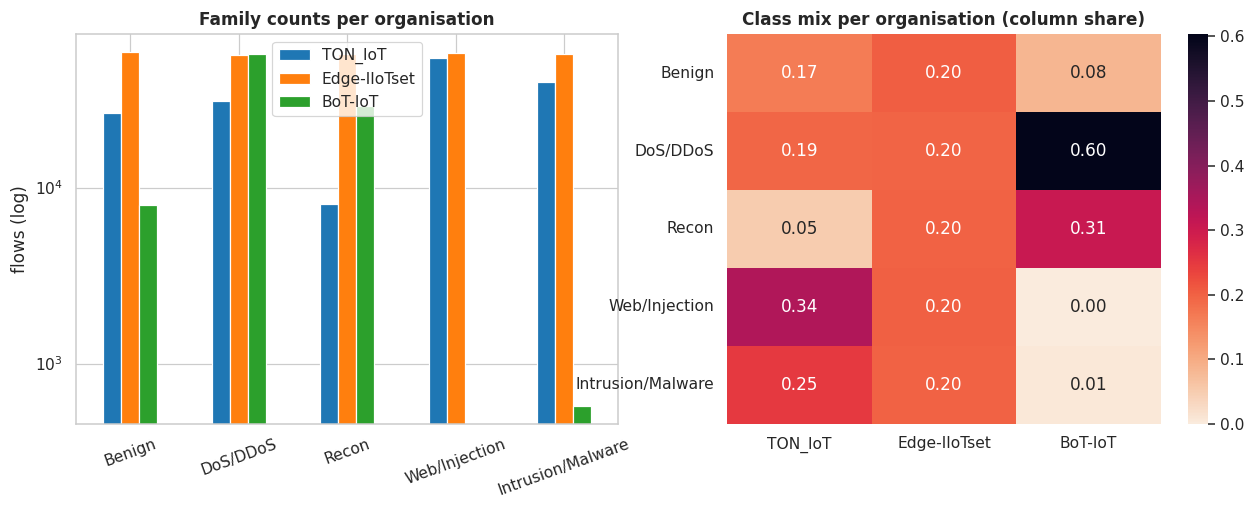

In [12]:
# ---------- dataset tables and figures ----------
add_table("T00_data_sources", pd.DataFrame([{"Dataset": k, **v} for k, v in SOURCES_USED.items()]) if SOURCES_USED else
          pd.DataFrame([{"Dataset": nm, "source": "cached (loaded from a previous run)"} for nm in ORGS]), "Where each dataset was obtained (Kaggle slug, files used)")
rows = []
for nm in ORGS:
    m = RAW[nm]["meta"]
    rows.append({"Organisation": nm, "CSV files": m["files"], "Rows read (mapped)": sum(m["seen"].values()),
                 "Duplicates removed": m["duplicates"], "Label conflicts removed": m["conflicts"], "Flows used": m["rows_used"],
                 "Features": RAW[nm]["X"].shape[1], "Unique hosts": len(set(RAW[nm]["src"]) | set(RAW[nm]["dst"])),
                 "Time order": m.get("time_source", "n/a")})
add_table("T01_datasets", pd.DataFrame(rows), "Organisations (datasets) before and after leakage-controlled cleaning")
lm = []
for nm in ORGS:
    for l, c in sorted(RAW[nm]["meta"]["raw"].items(), key=lambda kv: -kv[1]):
        lm.append({"Organisation": nm, "Original label": l, "Family": SPECS[nm]["fam"](l) or "(excluded)", "Rows in source": c})
add_table("T02_label_map", pd.DataFrame(lm), "Mapping of original labels to the five harmonised families", show=False)
cnt = pd.DataFrame({nm: pd.Series(RAW[nm]["y"]).value_counts().reindex(range(len(FAMS)), fill_value=0).values for nm in ORGS}, index=FAMS)
add_table("T03_class_counts", cnt.reset_index().rename(columns={"index": "Family"}), "Flows per family and organisation after cleaning")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
cnt.plot.bar(ax=axes[0], logy=True, color=PAL[:len(ORGS)]); axes[0].set_ylabel("flows (log)"); axes[0].set_title("Family counts per organisation")
axes[0].tick_params(axis="x", rotation=20)
shares = cnt / cnt.sum(0); sns.heatmap(shares, annot=True, fmt=".2f", cmap="rocket_r", ax=axes[1]); axes[1].set_title("Class mix per organisation (column share)")
save_fig(fig, "F01_class_distribution", "Class distribution and class mix of the three organisations")

## 2. Leakage-safe split, normalisation and temporal host-interaction graphs
* Flows are sorted by time and cut into **blocks of consecutive flows**; whole blocks go to train / validation / test
  (stratified by the block's dominant family). Neighbouring flows of the same attack burst therefore never sit on both
  sides of the split, which a random row split would allow.
* Median imputation and a quantile map to [0,1] are fitted on the **training split only**.
* A **window** of `WIN` consecutive flows forms one directed multigraph: nodes are the hosts seen in the window, every flow
  is a directed edge with its feature vector. Two temporal edge features are added inside each window: the relative position
  of the flow and the (rank-normalised) time since the same source's previous flow. The task is **edge classification**.
* Training and test windows are built only from flows of their own split; a client's windows only from its own flows.

TON_IoT: F=131  windows tr/va/te = 109/16/32
Edge-IIoTset: F=39  windows tr/va/te = 197/29/57
BoT-IoT: F=38  windows tr/va/te = 64/10/19

=== Table [T04_splits_graphs] Block-wise split and statistics of the window graphs
Organisation      Split  Windows  Flows (edges)  Mean hosts / window  Mean degree  Max degree  Benign  DoS/DDoS  Recon  Web/Injection  Intrusion/Malware
     TON_IoT      train      109         111243            50.880734    40.116480         928   18970     21369   5234          37975              27695
     TON_IoT validation       16          16384            37.062500    55.258010         831    2331      3270    860           5954               3969
     TON_IoT       test       32          32256            39.937500    50.478873         922    5121      6389   1974          10626               8146
Edge-IIoTset      train      197         201405           107.370558    19.043589        1024   41261     38975  40358          40820              39991
Edge-IIoTset v

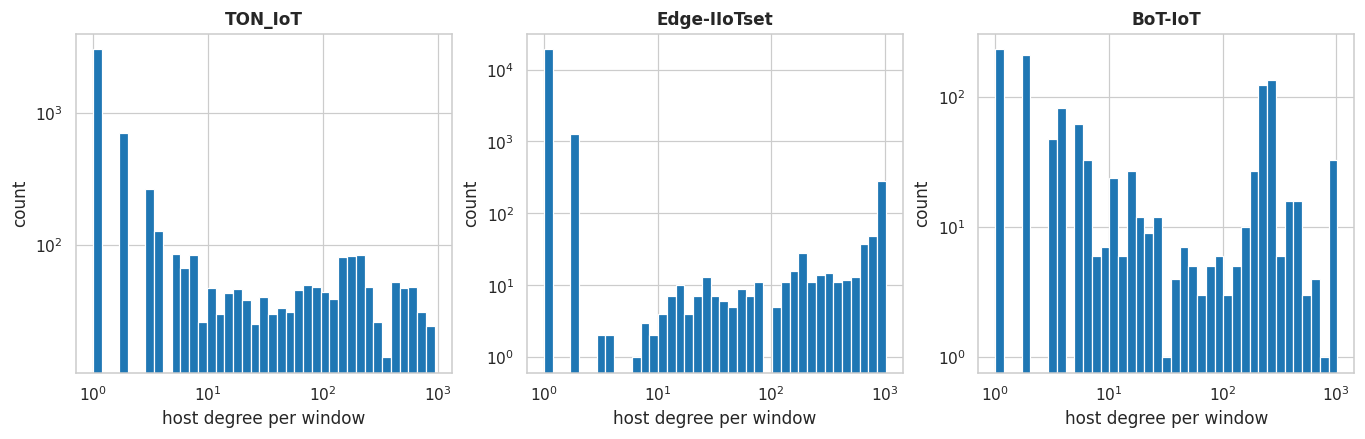


=== Table [T05_homophily] Label homophily among edges that share a host (test windows)
Organisation  Edge-label homophily (share of a host's edges with the majority label)
     TON_IoT                                                                0.975059
Edge-IIoTset                                                                0.822680
     BoT-IoT                                                                0.978210

=== Table [T05b_window_purity] Label purity of the time-ordered window graphs (share of a window's flows that belong to its majority family)
Organisation Split  Windows  Mean majority-family share  Windows >=95% one family (%)  Windows 100% one family (%)
     TON_IoT train      109                    0.905609                     58.715596                     1.834862
     TON_IoT  test       32                    0.879547                     56.250000                     0.000000
Edge-IIoTset train      197                    0.760066                     35.532995

,Organisation,Split,Windows,Mean majority-family share,Windows >=95% one family (%),Windows 100% one family (%)
0,TON_IoT,train,109,0.905609,58.715596,1.834862
1,TON_IoT,test,32,0.879547,56.250000,0.000000
2,Edge-IIoTset,train,197,0.760066,35.532995,13.197970
3,Edge-IIoTset,test,57,0.733364,29.824561,12.280702
4,BoT-IoT,train,64,0.916885,81.250000,12.500000
5,BoT-IoT,test,19,0.898540,63.157895,15.789474


In [13]:
# ============================== 3. SPLIT, NORMALISATION, WINDOW GRAPHS ==============================
def block_split(y, seed, block, ratios):
    nb = int(np.ceil(len(y) / block)); bid = np.arange(len(y)) // block
    dom = np.array([np.bincount(y[bid == b], minlength=len(FAMS)).argmax() for b in range(nb)])
    idx = np.arange(nb); te_r, va_r = ratios[2], ratios[1] / (ratios[0] + ratios[1])
    try:
        tr, te = train_test_split(idx, test_size=te_r, stratify=dom, random_state=seed)
        tr, va = train_test_split(tr, test_size=va_r, stratify=dom[tr], random_state=seed)
    except ValueError:
        tr, te = train_test_split(idx, test_size=te_r, random_state=seed); tr, va = train_test_split(tr, test_size=va_r, random_state=seed)
    S = np.empty(len(y), int)
    for lab, bs in [(0, tr), (1, va), (2, te)]: S[np.isin(bid, bs)] = lab
    return S

class Prep:
    def fit(self, X, seed=0):
        self.med = np.nan_to_num(np.nanmedian(X, 0)); Xi = np.where(np.isnan(X), self.med, X)
        rng = np.random.default_rng(seed); s = rng.choice(len(Xi), min(len(Xi), 200000), replace=False)
        self.keep = np.where(Xi[s].std(0) > 0)[0]
        self.qt = QuantileTransformer(n_quantiles=1000, output_distribution="uniform", subsample=200000, random_state=seed).fit(Xi[s][:, self.keep])
        return self
    def transform(self, X):
        Xi = np.where(np.isnan(X), self.med, X); return self.qt.transform(Xi[:, self.keep]).astype(np.float32)

N_TEMP = 2
def windows_from(X, y, t, src, dst, win, rewire_rng=None):
    """Consecutive (time-ordered) flows -> list of window graphs. rewire_rng: destroy topology (control experiment)."""
    out = []
    for s in range(0, len(y), win):
        e = slice(s, min(len(y), s + win)); E = e.stop - e.start
        if E < 8: continue
        a, b = src[e], dst[e]
        if rewire_rng is not None: a, b = rewire_rng.permutation(a), rewire_rng.permutation(b)
        nodes, inv = np.unique(np.concatenate([a, b]), return_inverse=True)
        si, di = inv[:E].astype(np.int64), inv[E:].astype(np.int64)
        tt = t[e]; pos = np.arange(E, dtype=np.float32) / max(1, E - 1)
        o = np.lexsort((tt, si)); dts = np.zeros(E, np.float32); d = np.diff(tt[o]); same = si[o][1:] == si[o][:-1]
        dts[o[1:]] = np.where(same, np.log1p(np.maximum(d, 0)), 0)
        dts = stats.rankdata(dts).astype(np.float32) / E
        x = np.hstack([X[e], pos[:, None], dts[:, None]]).astype(np.float32)
        out.append(dict(x=x, y=y[e].astype(np.int64), src=si, dst=di, N=len(nodes)))
    return out

def collate(ws):
    off = 0; xs, ys, ss, ds, wi = [], [], [], [], []
    for i, w in enumerate(ws):
        xs.append(w["x"]); ys.append(w["y"]); ss.append(w["src"] + off); ds.append(w["dst"] + off); off += w["N"]
        wi.append(np.full(len(w["y"]), i, np.int64))
    T = lambda a, dt: torch.as_tensor(np.concatenate(a), dtype=dt, device=DEV)
    return dict(x=T(xs, torch.float32), y=T(ys, torch.long), src=T(ss, torch.long), dst=T(ds, torch.long), N=off,
                wid=T(wi, torch.long), nW=len(ws))

ORG = {}
for nm in ORGS:
    R = RAW[nm]; S = block_split(R["y"], CFG["SPLIT_SEED"], CFG["SPLIT_BLOCK"], CFG["SPLIT"])
    pr = Prep().fit(R["X"][S == 0], CFG["SPLIT_SEED"]); XQ = pr.transform(R["X"])
    names = [R["names"][j] for j in pr.keep] + ["t_pos", "t_since_src"]
    d = dict(prep=pr, names=names, F=len(names), split=S, XQ=XQ)
    for k, sp in [("tr", 0), ("va", 1), ("te", 2)]:
        ix = np.where(S == sp)[0]
        d[k + "_idx"] = ix
        d[k] = windows_from(XQ[ix], R["y"][ix], R["t"][ix], R["src"][ix], R["dst"][ix], CFG["WIN"])
    cnt = np.bincount(R["y"][S == 0], minlength=len(FAMS)).astype(float)
    w = np.where(cnt > 0, np.sqrt(cnt.sum() / np.maximum(cnt, 1)), 0.0); d["cw"] = torch.as_tensor(w / w[w > 0].mean(), dtype=torch.float32, device=DEV)
    d["present"] = np.where(cnt > 0)[0]
    ORG[nm] = d
    print(f"{nm}: F={d['F']}  windows tr/va/te = {len(d['tr'])}/{len(d['va'])}/{len(d['te'])}")

rows = []
for nm in ORGS:
    for k in ["tr", "va", "te"]:
        W = ORG[nm][k]; deg = np.concatenate([np.bincount(np.concatenate([w["src"], w["dst"]]), minlength=w["N"]) for w in W])
        rows.append({"Organisation": nm, "Split": {"tr": "train", "va": "validation", "te": "test"}[k], "Windows": len(W),
                     "Flows (edges)": sum(len(w["y"]) for w in W), "Mean hosts / window": np.mean([w["N"] for w in W]),
                     "Mean degree": deg.mean(), "Max degree": deg.max(),
                     **{f"{FAMS[c]}": int(sum((w["y"] == c).sum() for w in W)) for c in range(len(FAMS))}})
add_table("T04_splits_graphs", pd.DataFrame(rows), "Block-wise split and statistics of the window graphs")

fig, axes = plt.subplots(1, len(ORGS), figsize=(5 * len(ORGS), 4))
for ax, nm in zip(np.atleast_1d(axes), ORGS):
    deg = np.concatenate([np.bincount(np.concatenate([w["src"], w["dst"]]), minlength=w["N"]) for w in ORG[nm]["tr"]])
    ax.hist(deg, bins=np.logspace(0, np.log10(deg.max() + 1), 40), color=PAL[0]); ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(nm); ax.set_xlabel("host degree per window"); ax.set_ylabel("count")
save_fig(fig, "F02_degree_distribution", "Host degree distribution of the training window graphs (log-log)")

# homophily of the edge label w.r.t. edges that share a host: how informative is topology?
rows = []
for nm in ORGS:
    same, tot = 0, 0
    for w in ORG[nm]["te"]:
        for nodes in (w["src"], w["dst"]):
            df_ = pd.DataFrame({"n": nodes, "y": w["y"]}); g = df_.groupby("n")["y"]
            maj = g.transform(lambda v: v.value_counts().iloc[0] if len(v) > 1 else np.nan); sz = g.transform("size")
            m = sz > 1; same += (maj[m] / sz[m]).sum(); tot += m.sum()
    rows.append({"Organisation": nm, "Edge-label homophily (share of a host's edges with the majority label)": same / max(tot, 1)})
add_table("T05_homophily", pd.DataFrame(rows), "Label homophily among edges that share a host (test windows)")

# window label purity: if most windows contain a single family, the window's composition alone can reveal the label and a
# GNN may exploit it (a shortcut, not host-interaction learning). T07b tests this explicitly.
def window_purity(W):
    return np.array([np.bincount(w["y"]).max() / len(w["y"]) for w in W]) if W else np.array([np.nan])
rows = []
for nm in ORGS:
    for k in ["tr", "te"]:
        p = window_purity(ORG[nm][k])
        rows.append({"Organisation": nm, "Split": {"tr": "train", "te": "test"}[k], "Windows": len(ORG[nm][k]),
                     "Mean majority-family share": p.mean(), "Windows >=95% one family (%)": 100 * (p >= 0.95).mean(),
                     "Windows 100% one family (%)": 100 * (p == 1).mean()})
add_table("T05b_window_purity", pd.DataFrame(rows), "Label purity of the time-ordered window graphs (share of a window's flows that belong to its majority family)")


## 3. Models
* **Organisation adapter** (private, stays at the organisation's fog node): `Linear(F_org -> d)` + GELU. It maps each
  organisation's own feature schema into a shared space, so organisations with different feature extractors can train one
  shared body without hand-made feature harmonisation.
* **Shared body + head** (federated):
  * `EdgeMLP` – no graph (flow-only baseline);
  * `E-GraphSAGE` – mean aggregation of incident edges, undirected (Lo et al., 2022);
  * **`TG-EGNN (proposed)`** – directional (in/out) edge-conditioned message passing with attention over incident edges,
    residual + LayerNorm, temporal edge features; the edge embedding is `MLP([h_src ‖ h_dst ‖ e])`.
* `Window-context MLP` – **shortcut control**: each flow's embedding is concatenated with the mean embedding of all flows in
  its window, with **no topology**. If it matches TG-EGNN, the graph's gain comes from window composition, not from host structure.
* Privacy-free references trained on pooled data per organisation: Logistic Regression, Random Forest, XGBoost.

In [14]:
# ============================== 4. MODELS ==============================
def scatter_mean(src_vals, idx, N):
    out = torch.zeros(N, src_vals.shape[1], device=src_vals.device).index_add_(0, idx, src_vals)
    cnt = torch.zeros(N, device=src_vals.device).index_add_(0, idx, torch.ones_like(idx, dtype=torch.float32)).clamp_min(1)
    return out / cnt[:, None]

def scatter_softmax(score, idx, N):
    mx = torch.full((N,), -1e30, device=score.device).scatter_reduce(0, idx, score, "amax", include_self=True)
    ex = torch.exp(score - mx[idx]); den = torch.zeros(N, device=score.device).index_add_(0, idx, ex)
    return ex / (den[idx] + 1e-16)

class EdgeConvLayer(nn.Module):
    def __init__(self, d, attn, residual, directional, drop):
        super().__init__(); self.attn, self.res, self.dir = attn, residual, directional
        nd = 2 if directional else 1
        self.msg = nn.ModuleList([nn.Linear(2 * d, d) for _ in range(nd)])
        if attn:
            self.q = nn.ModuleList([nn.Linear(d, d, bias=False) for _ in range(nd)]); self.k = nn.ModuleList([nn.Linear(d, d, bias=False) for _ in range(nd)])
        self.upd = nn.Linear(d * (1 + nd), d); self.ln = nn.LayerNorm(d) if residual else nn.Identity(); self.drop = nn.Dropout(drop)
        self._attn_macs = 0
    def _agg(self, j, h_nb, h_tg, e, idx, N):
        m = F.gelu(self.msg[j](torch.cat([h_nb, e], 1)))
        if self.attn:
            sc = (self.q[j](h_tg) * self.k[j](m)).sum(1) / math.sqrt(m.shape[1]); a = scatter_softmax(sc, idx, N)
            self._attn_macs += 2 * m.numel()
            return torch.zeros(N, m.shape[1], device=m.device).index_add_(0, idx, m * a[:, None])
        return scatter_mean(m, idx, N)
    def forward(self, h, e, src, dst, N):
        if self.dir:
            agg = [self._agg(0, h[src], h[dst], e, dst, N), self._agg(1, h[dst], h[src], e, src, N)]   # incoming, outgoing
        else:
            idx = torch.cat([dst, src]); nb = torch.cat([h[src], h[dst]]); tg = torch.cat([h[dst], h[src]]); ee = torch.cat([e, e])
            agg = [self._agg(0, nb, tg, ee, idx, N)]
        out = self.drop(F.gelu(self.upd(torch.cat([h] + agg, 1))))
        return self.ln(h + out) if self.res else out

class TGModel(nn.Module):
    def __init__(self, kind, feats, C, d=64, layers=2, drop=0.1, attn=True, residual=True, directional=True, temporal=True):
        super().__init__(); self.kind, self.temporal = kind, temporal
        self.adapters = nn.ModuleDict({k: nn.Sequential(nn.Linear(f, d), nn.GELU()) for k, f in feats.items()})
        if kind == "EdgeMLP":
            self.body = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, d), nn.GELU())
        elif kind == "CtxMLP":      # flow + mean of its window (no topology): shortcut control
            self.body = nn.Sequential(nn.Linear(2 * d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, d), nn.GELU())
        else:
            self.init = nn.Linear(2 * d, d)
            self.layers = nn.ModuleList([EdgeConvLayer(d, attn, residual, directional, drop) for _ in range(layers)])
            self.edge_out = nn.Sequential(nn.Linear(3 * d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, d), nn.GELU())
        self.head = nn.Linear(d, C)
    def embed(self, b, org):
        x = b["x"]
        if not self.temporal: x = torch.cat([x[:, :-N_TEMP], torch.zeros_like(x[:, -N_TEMP:])], 1)
        e = self.adapters[org](x)
        if self.kind == "EdgeMLP": return self.body(e)
        if self.kind == "CtxMLP":
            wid = b.get("wid")
            if wid is None: wid, nW = torch.zeros(len(e), dtype=torch.long, device=e.device), 1
            else: nW = b["nW"]
            return self.body(torch.cat([e, scatter_mean(e, wid, nW)[wid]], 1))
        N, s, t = b["N"], b["src"], b["dst"]
        h = F.gelu(self.init(torch.cat([scatter_mean(e, s, N), scatter_mean(e, t, N)], 1)))
        for L in self.layers: h = L(h, e, s, t, N)
        return self.edge_out(torch.cat([h[s], h[t], e], 1))
    def forward(self, b, org):
        z = self.embed(b, org); return self.head(z), z

PROP = "TG-EGNN (proposed)"
CTX = "Window-context MLP"
VARIANTS = {"EdgeMLP": dict(kind="EdgeMLP"), CTX: dict(kind="CtxMLP"), "E-GraphSAGE": dict(kind="GNN", attn=False, residual=False, directional=False),
            PROP: dict(kind="GNN")}
ABLATIONS = {"w/o attention": dict(kind="GNN", attn=False), "w/o residual+LN": dict(kind="GNN", residual=False),
             "w/o direction": dict(kind="GNN", directional=False), "w/o temporal features": dict(kind="GNN", temporal=False)}
FEATS = {nm: ORG[nm]["F"] for nm in ORGS}
def build(cfg_kw): return TGModel(feats=FEATS, C=len(FAMS), d=CFG["D"], layers=CFG["LAYERS"], drop=CFG["DROPOUT"], **cfg_kw).to(DEV)
SHARED = lambda m: [n for n, _ in m.named_parameters() if not n.startswith("adapters.")]

In [15]:
# ============================== 5. CENTRALISED TRAINING / EVALUATION ==============================
@torch.no_grad()
def predict(model, W, org, bs=None):
    model.eval(); bs = bs or CFG["WIN_BATCH"] * 2; P, Z, Y = [], [], []
    for i in range(0, len(W), bs):
        b = collate(W[i:i + bs]); lg, z = model(b, org); P.append(lg.float().cpu().numpy()); Z.append(z.float().cpu().numpy()); Y.append(b["y"].cpu().numpy())
    return np.concatenate(P), np.concatenate(Z), np.concatenate(Y)

def eval_orgs(model, split="te", W_override=None):
    res = {}
    for nm in ORGS:
        W = W_override[nm] if W_override else ORG[nm][split]
        if not W: continue
        lg, z, y = predict(model, W, nm); res[nm] = metrics(y, softmax_np(lg), len(FAMS))
    res["mean"] = {k: np.mean([res[n][k] for n in ORGS if n in res]) for k in ["Acc", "F1", "wF1", "BA", "MCC", "FPR", "DR"]}
    return res

def train_central(cfg_kw, seed, epochs=None, W_train=None, W_val=None, adv=None, log=False):
    set_seed(seed); model = build(cfg_kw); opt = torch.optim.AdamW(model.parameters(), lr=CFG["C_LR"], weight_decay=1e-4)
    epochs = epochs or CFG["C_EPOCHS"]; sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    Wt = W_train or {nm: ORG[nm]["tr"] for nm in ORGS}; Wv = W_val or {nm: ORG[nm]["va"] for nm in ORGS}
    rng = np.random.default_rng(seed); best, best_state, bad, hist = -1, None, 0, []
    for ep in range(epochs):
        model.train(); t0 = time.time(); losses = []
        order = {nm: rng.permutation(len(Wt[nm])) for nm in ORGS}
        nb = max(int(np.ceil(len(Wt[nm]) / CFG["WIN_BATCH"])) for nm in ORGS)
        for i in range(nb):
            opt.zero_grad(); tot = 0
            for nm in ORGS:
                o = order[nm]
                if not len(o): continue
                sel = [Wt[nm][j] for j in o[(i * CFG["WIN_BATCH"]) % len(o):][: CFG["WIN_BATCH"]]]
                b = collate(sel)
                if adv is not None and rng.random() < adv["p"]:
                    b = adv_batch(model, b, nm, adv)
                lg, _ = model(b, nm); loss = F.cross_entropy(lg, b["y"], weight=ORG[nm]["cw"]); loss.backward(); tot += loss.item()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); losses.append(tot / len(ORGS))
        sched.step()
        v = eval_orgs(model, W_override=Wv)["mean"]["F1"]; hist.append(dict(epoch=ep + 1, loss=np.mean(losses), val_F1=v, sec=time.time() - t0))
        if log: print(f"  ep {ep+1:02d} loss {np.mean(losses):.4f} val macro-F1 {v:.2f}")
        if v > best + 1e-4: best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= CFG["PATIENCE"]: break
    model.load_state_dict(best_state); return model, hist

def adv_batch(model, b, org, adv):
    """Replace the features of the attack edges in a batch with constraint-aware PGD examples (adversarial training)."""
    cons = ORG_CONS[org]; m = b["y"] != 0
    if m.sum() == 0: return b
    model.eval()
    def fwd(xa):
        bb = dict(b); x = b["x"].clone(); x[m] = xa; bb["x"] = x; return model(bb, org)[0][m]
    xa = pgd_constrained(fwd, b["x"][m], b["y"][m], cons, adv["eps"], steps=adv["steps"])
    model.train(); b = dict(b); x = b["x"].clone(); x[m] = xa; b["x"] = x; return b

ORG_CONS = {nm: {k: np.concatenate([v, np.ones(N_TEMP, bool) if k == "immutable" else np.zeros(N_TEMP, bool)])
                 for k, v in feature_constraints(ORG[nm]["XQ"][ORG[nm]["tr_idx"]], ORG[nm]["names"][:-N_TEMP]).items()} for nm in ORGS}

def run_central(name, cfg_kw, seed, **kw):
    def go():
        m, hist = train_central(cfg_kw, seed, **kw)
        torch.save(m.state_dict(), OUT / "models" / f"central_{re.sub('[^A-Za-z0-9]', '', name)}_s{seed}.pt")
        return dict(test=eval_orgs(m, "te"), val=eval_orgs(m, "va"), hist=hist, params=n_params(m))
    return cached(f"central_{name}_s{seed}", go)

def load_central(name, seed, cfg_kw):
    m = build(cfg_kw); m.load_state_dict(torch.load(OUT / "models" / f"central_{re.sub('[^A-Za-z0-9]', '', name)}_s{seed}.pt", map_location=DEV)); return m.eval()

def flat_xy(nm, split):
    W = ORG[nm][split]; return np.concatenate([w["x"] for w in W]), np.concatenate([w["y"] for w in W])

def run_trees(seed):
    def go():
        out = {}
        for nm in ORGS:
            Xtr, ytr = flat_xy(nm, "tr"); Xte, yte = flat_xy(nm, "te")
            mods = {"Logistic Regression": LogisticRegression(max_iter=300, class_weight="balanced", n_jobs=-1),
                    "Random Forest": RandomForestClassifier(200, n_jobs=-1, class_weight="balanced_subsample", random_state=seed)}
            if xgb is not None:
                mods["XGBoost"] = xgb.XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                                                    tree_method="hist", random_state=seed, n_jobs=-1)
            for mn, md in mods.items():
                cl = np.unique(ytr); remap = {c: i for i, c in enumerate(cl)}
                md.fit(Xtr, np.vectorize(remap.get)(ytr)); P = np.zeros((len(Xte), len(FAMS))); P[:, cl] = md.predict_proba(Xte)
                out.setdefault(mn, {})[nm] = metrics(yte, P, len(FAMS))
        for mn in out: out[mn]["mean"] = {k: np.mean([out[mn][n][k] for n in ORGS]) for k in ["Acc", "F1", "wF1", "BA", "MCC", "FPR", "DR"]}
        return out
    return cached(f"trees_s{seed}", go)

CEN = {}
for s in CFG["SEEDS"]:
    for mn, kw in VARIANTS.items():
        print(f"centralised {mn} seed {s}"); CEN[(mn, s)] = run_central(mn, kw, s)
    for mn, r in run_trees(s).items(): CEN[(mn, s)] = dict(test=r)

centralised EdgeMLP seed 42
centralised Window-context MLP seed 42
centralised E-GraphSAGE seed 42
centralised TG-EGNN (proposed) seed 42
centralised EdgeMLP seed 43
centralised Window-context MLP seed 43
centralised E-GraphSAGE seed 43
centralised TG-EGNN (proposed) seed 43
centralised EdgeMLP seed 44
centralised Window-context MLP seed 44
centralised E-GraphSAGE seed 44
centralised TG-EGNN (proposed) seed 44
centralised EdgeMLP seed 45
centralised Window-context MLP seed 45
centralised E-GraphSAGE seed 45
centralised TG-EGNN (proposed) seed 45
centralised EdgeMLP seed 46
centralised Window-context MLP seed 46
centralised E-GraphSAGE seed 46
centralised TG-EGNN (proposed) seed 46



=== Table [T06_centralised] Centralised results (macro-averaged over organisations; mean ± sd over seeds)
              Model            Privacy          Acc           F1           BA           MCC         FPR           DR   F1 TON_IoT F1 Edge-IIoTset   F1 BoT-IoT
Logistic Regression        pooled data 89.27 ± 0.00 83.63 ± 0.00 89.11 ± 0.00 0.860 ± 0.000 6.62 ± 0.00 98.32 ± 0.00 91.64 ± 0.00    79.15 ± 0.00 80.10 ± 0.00
      Random Forest        pooled data 96.70 ± 0.04 95.64 ± 0.02 95.08 ± 0.01 0.958 ± 0.000 0.72 ± 0.03 99.82 ± 0.00 96.54 ± 0.08    92.38 ± 0.14 98.00 ± 0.03
            XGBoost        pooled data 95.89 ± 0.05 94.29 ± 0.40 94.09 ± 0.14 0.948 ± 0.001 0.61 ± 0.02 99.81 ± 0.00 95.82 ± 0.13    90.21 ± 0.03 96.82 ± 1.12
            EdgeMLP pooled (reference) 89.19 ± 0.62 83.28 ± 0.44 86.29 ± 0.41 0.858 ± 0.009 8.25 ± 0.44 99.26 ± 0.04 90.57 ± 1.27    81.70 ± 0.41 77.57 ± 0.42
 Window-context MLP pooled (reference) 94.86 ± 0.38 94.09 ± 0.45 94.06 ± 0.42 0.934 ± 0.005 6.53 ±

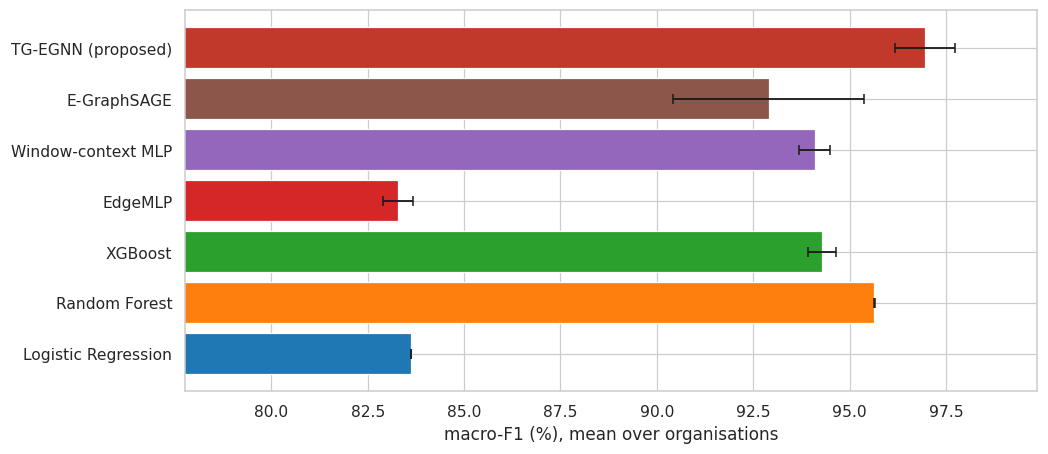

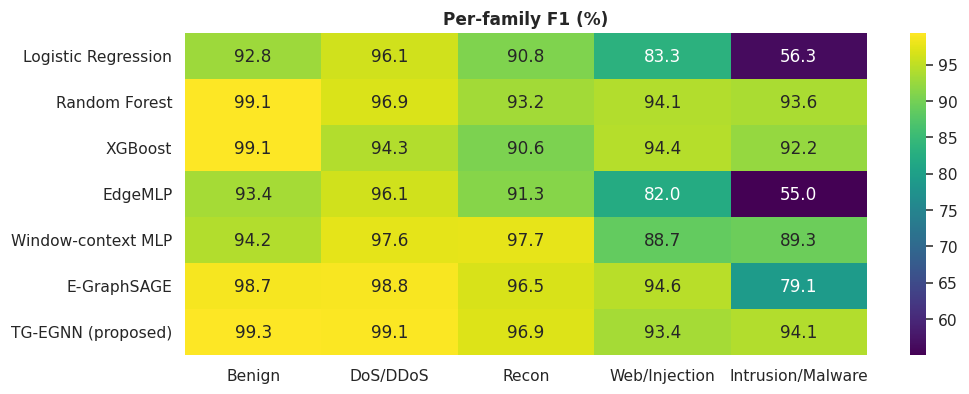

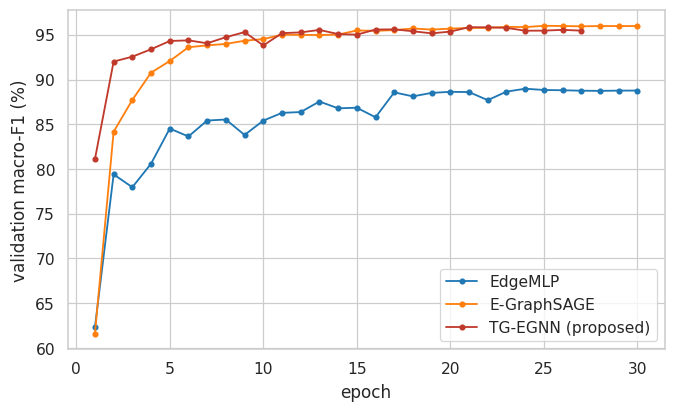

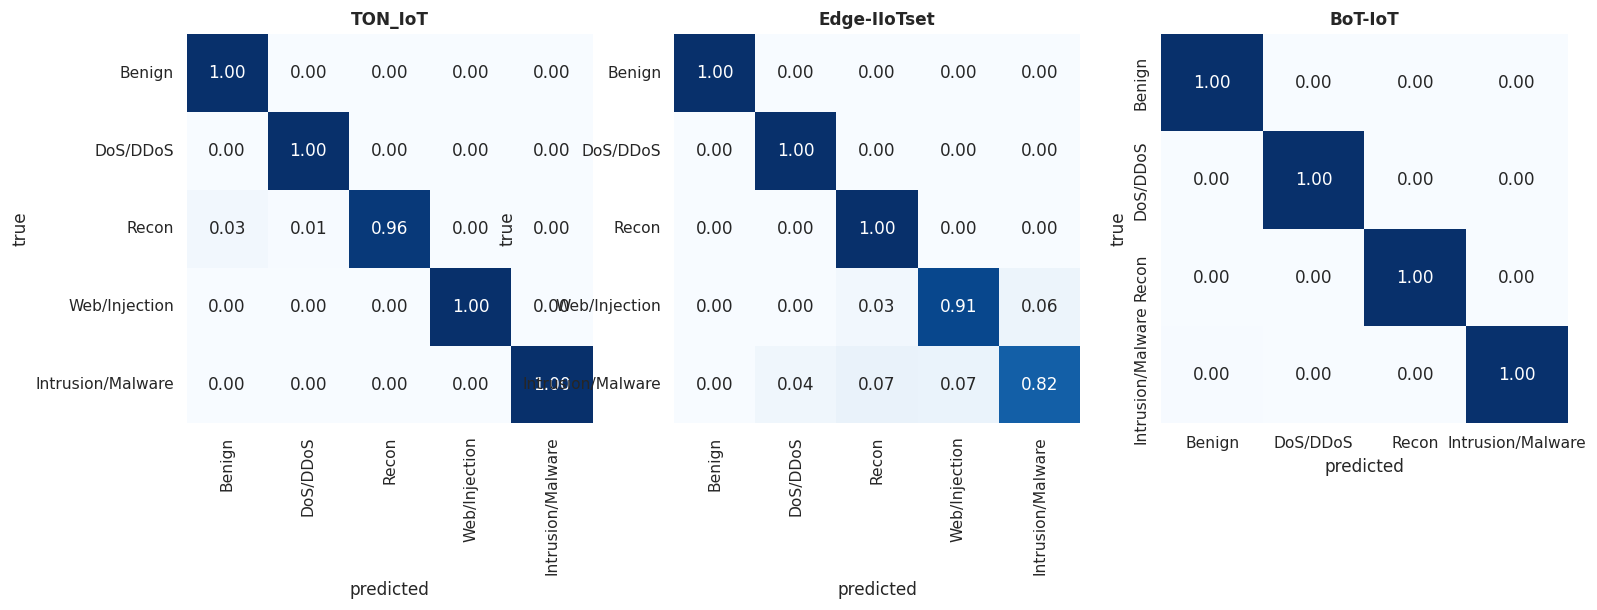

In [16]:
# ---------- centralised result tables / figures ----------
MODELS_C = ["Logistic Regression", "Random Forest", "XGBoost", "EdgeMLP", CTX, "E-GraphSAGE", PROP]
MODELS_C = [m for m in MODELS_C if (m, CFG["SEEDS"][0]) in CEN]
rows = []
for mn in MODELS_C:
    r = {"Model": mn, "Privacy": "pooled data" if mn in ("Logistic Regression", "Random Forest", "XGBoost") else "pooled (reference)"}
    for k in ["Acc", "F1", "BA", "MCC", "FPR", "DR"]:
        r[k] = ms([CEN[(mn, s)]["test"]["mean"][k] for s in CFG["SEEDS"]], 3 if k == "MCC" else 2)
    for nm in ORGS: r[f"F1 {nm}"] = ms([CEN[(mn, s)]["test"][nm]["F1"] for s in CFG["SEEDS"]])
    rows.append(r)
add_table("T06_centralised", pd.DataFrame(rows), "Centralised results (macro-averaged over organisations; mean ± sd over seeds)")

fig, ax = plt.subplots(figsize=(10, 4.5))
v = np.array([[CEN[(m, s)]["test"]["mean"]["F1"] for s in CFG["SEEDS"]] for m in MODELS_C])
ax.barh(MODELS_C, v.mean(1), xerr=v.std(1), capsize=3, color=[PROP_COLOR if m == PROP else PAL[i] for i, m in enumerate(MODELS_C)])
ax.set_xlabel("macro-F1 (%), mean over organisations"); ax.set_xlim(max(0, v.min() - 5), min(100, v.max() + 2))
save_fig(fig, "F03_centralised_models", "Centralised macro-F1 of all models (mean ± sd over seeds)")

pc = pd.DataFrame({mn: [np.mean([np.mean([CEN[(mn, s)]["test"][nm]["per_class_F1"].get(c, np.nan) for nm in ORGS if c in CEN[(mn, s)]["test"][nm]["per_class_F1"]] or [np.nan])
                             for s in CFG["SEEDS"]]) for c in range(len(FAMS))] for mn in MODELS_C}, index=FAMS)
fig, ax = plt.subplots(figsize=(10, 3.8)); sns.heatmap(pc.T, annot=True, fmt=".1f", cmap="viridis", ax=ax); ax.set_title("Per-family F1 (%)")
save_fig(fig, "F04_per_class_heatmap", "Per-family F1 of the centralised models (averaged over organisations that contain the family)")

fig, ax = plt.subplots(figsize=(7, 4))
for i, mn in enumerate(["EdgeMLP", "E-GraphSAGE", PROP]):
    h = pd.DataFrame(CEN[(mn, CFG["SEEDS"][0])]["hist"]); ax.plot(h.epoch, h.val_F1, "-o", ms=3, label=mn, color=PROP_COLOR if mn == PROP else PAL[i])
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1 (%)"); ax.legend()
save_fig(fig, "F05_training_curves", "Validation macro-F1 during centralised training (first seed)")

# confusion matrices of the proposed model (first seed)
mP = load_central(PROP, CFG["SEEDS"][0], VARIANTS[PROP])
fig, axes = plt.subplots(1, len(ORGS), figsize=(5.4 * len(ORGS), 4.6))
for ax, nm in zip(np.atleast_1d(axes), ORGS):
    lg, _, y = predict(mP, ORG[nm]["te"], nm); pr = ORG[nm]["present"]
    cm = confusion_matrix(y, lg.argmax(1), labels=pr, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=[FAMS[i] for i in pr], yticklabels=[FAMS[i] for i in pr], ax=ax, cbar=False)
    ax.set_title(nm); ax.set_xlabel("predicted"); ax.set_ylabel("true")
save_fig(fig, "F06_confusion", "Row-normalised confusion matrices of the proposed model (test windows)")

In [17]:
# ---------- ablation and topology control ----------
ABL = {}
for s in CFG["SEEDS"]:
    for an, kw in ABLATIONS.items(): ABL[(an, s)] = run_central(f"abl_{an}", kw, s)
    def rewired(split, seed=s):
        rg = np.random.default_rng(seed); out = {}
        for nm in ORGS:
            ix = ORG[nm][split + "_idx"]; R = RAW[nm]
            out[nm] = windows_from(ORG[nm]["XQ"][ix], R["y"][ix], R["t"][ix], R["src"][ix], R["dst"][ix], CFG["WIN"], rewire_rng=rg)
        return out
    ABL[("topology shuffled (control)", s)] = cached(f"abl_rewired_s{s}", lambda: (lambda m: dict(test=eval_orgs(m[0], W_override=rewired("te"))))(
        train_central(VARIANTS[PROP], s, W_train=rewired("tr"), W_val=rewired("va"))))
rows = [{"Variant": "Full " + PROP, **{k: ms([CEN[(PROP, s)]["test"]["mean"][k] for s in CFG["SEEDS"]]) for k in ["F1", "MCC", "FPR"]}}]
for an in list(ABLATIONS) + ["topology shuffled (control)"]:
    a = [ABL[(an, s)]["test"]["mean"]["F1"] for s in CFG["SEEDS"]]; b = [CEN[(PROP, s)]["test"]["mean"]["F1"] for s in CFG["SEEDS"]]
    pt = paired(a, b)
    rows.append({"Variant": an, "F1": ms(a), "MCC": ms([ABL[(an, s)]["test"]["mean"]["MCC"] for s in CFG["SEEDS"]], 3),
                 "FPR": ms([ABL[(an, s)]["test"]["mean"]["FPR"] for s in CFG["SEEDS"]]), "ΔF1 vs full": f"{pt['mean_diff']:+.2f}", "p (paired t)": pt["p_t"]})
add_table("T07_ablation", pd.DataFrame(rows), "Component ablation of the proposed model and topology-shuffled control (centralised)")


=== Table [T07_ablation] Component ablation of the proposed model and topology-shuffled control (centralised)
                    Variant           F1           MCC         FPR ΔF1 vs full  p (paired t)
    Full TG-EGNN (proposed) 96.97 ± 0.87   0.97 ± 0.01 0.18 ± 0.08         NaN           NaN
              w/o attention 97.25 ± 0.65 0.971 ± 0.006 0.14 ± 0.04       +0.28      0.476673
            w/o residual+LN 96.89 ± 2.09 0.974 ± 0.007 0.15 ± 0.06       -0.08      0.945020
              w/o direction 97.18 ± 0.83 0.970 ± 0.009 0.20 ± 0.12       +0.22      0.686734
      w/o temporal features 96.74 ± 0.71 0.965 ± 0.007 0.18 ± 0.09       -0.23      0.592568
topology shuffled (control) 93.54 ± 1.33 0.931 ± 0.014 7.70 ± 4.78       -3.42      0.007797


,Variant,F1,MCC,FPR,ΔF1 vs full,p (paired t)
0,Full TG-EGNN (proposed),96.97 ± 0.87,0.97 ± 0.01,0.18 ± 0.08,NaN,NaN
1,w/o attention,97.25 ± 0.65,0.971 ± 0.006,0.14 ± 0.04,+0.28,0.476673
2,w/o residual+LN,96.89 ± 2.09,0.974 ± 0.007,0.15 ± 0.06,-0.08,0.945020
3,w/o direction,97.18 ± 0.83,0.970 ± 0.009,0.20 ± 0.12,+0.22,0.686734
4,w/o temporal features,96.74 ± 0.71,0.965 ± 0.007,0.18 ± 0.09,-0.23,0.592568
5,topology shuffled (control),93.54 ± 1.33,0.931 ± 0.014,7.70 ± 4.78,-3.42,0.007797


In [18]:
# ---------- window-purity stress test: is the graph gain caused by label-pure windows? ----------
# (a) models trained on normal time-ordered windows are tested on windows built from the SAME test flows in random order
#     (each flow keeps its own features, label, source and destination host; only the window composition is mixed);
# (b) the window-context control and the proposed model are retrained and tested on mixed windows.
# EdgeMLP classifies each flow alone, so its F1 must not change in (a): this is the sanity check.
def mixed_windows(split, seed):
    rg = np.random.default_rng(1000 + seed); out = {}
    for nm in ORGS:
        ix = rg.permutation(ORG[nm][split + "_idx"]); R = RAW[nm]
        out[nm] = windows_from(ORG[nm]["XQ"][ix], R["y"][ix], R["t"][ix], R["src"][ix], R["dst"][ix], CFG["WIN"])
    return out

STRESS_MODELS = [m for m in ["EdgeMLP", CTX, "E-GraphSAGE", PROP] if (m, CFG["SEEDS"][0]) in CEN]
RETRAIN_MODELS, RETRAIN_SEEDS = [CTX, PROP], CFG["SEEDS"][:3]
STRESS = {}
for s in CFG["SEEDS"]:
    MIX_TE = None
    for mn in STRESS_MODELS:
        def go_a(mn=mn, s=s):
            global MIX_TE
            MIX_TE = MIX_TE or mixed_windows("te", s)
            return eval_orgs(load_central(mn, s, VARIANTS[mn]), W_override=MIX_TE)
        STRESS[("a", mn, s)] = cached(f"stress_mixedtest_{mn}_s{s}", go_a)
    if s in RETRAIN_SEEDS:
        for mn in RETRAIN_MODELS:
            def go_b(mn=mn, s=s):
                global MIX_TE
                MIX_TE = MIX_TE or mixed_windows("te", s)
                m, _ = train_central(VARIANTS[mn], s, W_train=mixed_windows("tr", s), W_val=mixed_windows("va", s))
                return eval_orgs(m, W_override=MIX_TE)
            STRESS[("b", mn, s)] = cached(f"stress_mixedtrain_{mn}_s{s}", go_b)

rows = []
for mn in STRESS_MODELS:
    o = [CEN[(mn, s)]["test"]["mean"]["F1"] for s in CFG["SEEDS"]]; a = [STRESS[("a", mn, s)]["mean"]["F1"] for s in CFG["SEEDS"]]
    b = [STRESS[("b", mn, s)]["mean"]["F1"] for s in RETRAIN_SEEDS] if mn in RETRAIN_MODELS else []
    rows.append({"Model": mn, "F1 time-ordered (train+test)": ms(o), "F1 ordered train / mixed test": ms(a),
                 "Drop (ordered - mixed test)": f"{np.mean(o) - np.mean(a):+.2f}",
                 f"F1 mixed train+test ({len(RETRAIN_SEEDS)} seeds)": ms(b) if b else "-"})
add_table("T07b_purity_stress", pd.DataFrame(rows),
          "Window-purity stress test: time-ordered vs randomly mixed window graphs (same flows, same hosts)")
pm = {nm: window_purity(mixed_windows("te", CFG["SEEDS"][0])[nm]).mean() for nm in ORGS}
po = {nm: window_purity(ORG[nm]["te"]).mean() for nm in ORGS}
add_table("T07c_mixed_purity", pd.DataFrame([{"Organisation": nm, "Majority share, time-ordered windows": po[nm],
                                              "Majority share, mixed windows": pm[nm]} for nm in ORGS]),
          "Window label purity before and after mixing (test split)")



=== Table [T07b_purity_stress] Window-purity stress test: time-ordered vs randomly mixed window graphs (same flows, same hosts)
             Model F1 time-ordered (train+test) F1 ordered train / mixed test Drop (ordered - mixed test) F1 mixed train+test (3 seeds)
           EdgeMLP                 83.28 ± 0.44                  83.48 ± 0.33                       -0.20                             -
Window-context MLP                 94.09 ± 0.45                  42.51 ± 2.32                      +51.58                  87.02 ± 0.29
       E-GraphSAGE                 92.90 ± 2.78                  59.61 ± 1.80                      +33.29                             -
TG-EGNN (proposed)                 96.97 ± 0.87                  60.27 ± 2.43                      +36.70                  93.82 ± 0.57

=== Table [T07c_mixed_purity] Window label purity before and after mixing (test split)
Organisation  Majority share, time-ordered windows  Majority share, mixed windows
     TON_IoT         

,Organisation,"Majority share, time-ordered windows","Majority share, mixed windows"
0,TON_IoT,0.879547,0.329742
1,Edge-IIoTset,0.733364,0.216026
2,BoT-IoT,0.898540,0.587120


In [19]:
# ---------- T07d: purity-robust training and hand-crafted context baselines ----------
# Questions a reviewer will ask after T07b:
#  (1) does a model trained on MIXED windows still work on time-ordered windows (and vice versa)?
#  (2) does "purity-robust" training on ordered + mixed windows give one model that works on both?
#  (3) is E-GraphSAGE as good as TG-EGNN once the purity shortcut is removed?
#  (4) can a Random Forest with hand-crafted window or host-aggregate features match the GNN?
D_SEEDS = CFG["SEEDS"][:3]
_MIX = {}
def mixw(split, s):
    if (split, s) not in _MIX: _MIX[(split, s)] = mixed_windows(split, s)
    return _MIX[(split, s)]

def train_eval_both(mn, s, mode):
    """mode: 'mixed' = train/validate on mixed windows; 'aug' = on ordered + mixed windows. Tested on ordered AND mixed test windows."""
    def go():
        if mode == "mixed": Wt, Wv = mixw("tr", s), mixw("va", s)
        else:
            mt, mv = mixw("tr", s), mixw("va", s)
            Wt = {nm: ORG[nm]["tr"] + mt[nm] for nm in ORGS}; Wv = {nm: ORG[nm]["va"] + mv[nm] for nm in ORGS}
        m, _ = train_central(VARIANTS[mn], s, W_train=Wt, W_val=Wv)
        return dict(ordered=eval_orgs(m, "te"), mixed=eval_orgs(m, W_override=mixw("te", s)))
    return cached(f"t07d_{mode}_{mn}_s{s}", go)

D = {}
for s in D_SEEDS:
    for mn in [CTX, "E-GraphSAGE", PROP]:
        print(f"T07d: {mn} trained on mixed windows, seed {s}"); D[("mixed", mn, s)] = train_eval_both(mn, s, "mixed")
    print(f"T07d: {PROP} purity-robust (ordered + mixed) training, seed {s}"); D[("aug", PROP, s)] = train_eval_both(PROP, s, "aug")

# hand-crafted context features for a Random Forest (same flows, same windows)
def ctx_feats(W, kind):
    X, Y = [], []
    for w in W:
        x = w["x"].astype(np.float32); parts = [x]
        if kind == "window":
            parts.append(np.repeat(x.mean(0, keepdims=True), len(x), 0))
        if kind == "host":
            for idx in (w["src"], w["dst"]):
                S = np.zeros((w["N"], x.shape[1]), np.float32); np.add.at(S, idx, x)
                cnt = np.bincount(idx, minlength=w["N"]).astype(np.float32)[:, None]
                parts.append((S / np.maximum(cnt, 1))[idx]); parts.append(np.log1p(cnt[idx]))
        X.append(np.hstack(parts)); Y.append(w["y"])
    return np.vstack(X), np.concatenate(Y)

def rf_ctx(kind, train_mode, s=CFG["SEEDS"][0]):
    def go():
        out = {"ordered": {}, "mixed": {}}
        for nm in ORGS:
            Wtr = ORG[nm]["tr"] if train_mode == "ordered" else mixw("tr", s)[nm]
            Xtr, ytr = ctx_feats(Wtr, kind); cl = np.unique(ytr); remap = {c: i for i, c in enumerate(cl)}
            md = RandomForestClassifier(200, n_jobs=-1, class_weight="balanced_subsample", random_state=s).fit(Xtr, np.vectorize(remap.get)(ytr))
            for tm in ["ordered", "mixed"]:
                Xte, yte = ctx_feats(ORG[nm]["te"] if tm == "ordered" else mixw("te", s)[nm], kind)
                P = np.zeros((len(Xte), len(FAMS))); P[:, cl] = md.predict_proba(Xte); out[tm][nm] = metrics(yte, P, len(FAMS))
        for tm in out: out[tm]["mean"] = {k: np.mean([out[tm][n][k] for n in ORGS]) for k in ["F1", "FPR"]}
        return out
    return cached(f"t07d_rf_{kind}_{train_mode}_s{s}", go)
RFC = {}
for kind in ["window", "host"]:
    for tmode in ["ordered", "mixed"]:
        print(f"T07d: Random Forest + {kind} features, trained on {tmode} windows"); RFC[(kind, tmode)] = rf_ctx(kind, tmode)

rows = []
def addrow(model, trained, o, m, fo=None, fm=None):
    rows.append({"Model": model, "Trained on": trained, "F1 ordered test": o, "F1 mixed test": m,
                 "FPR ordered test": fo if fo is not None else "-", "FPR mixed test": fm if fm is not None else "-"})
cen = lambda mn, k="F1": [CEN[(mn, s)]["test"]["mean"][k] for s in D_SEEDS]
stA = lambda mn, k="F1": [STRESS[("a", mn, s)]["mean"][k] for s in D_SEEDS]
addrow("Random Forest (flow only)", "any (per-flow)", ms([CEN[("Random Forest", s)]["test"]["mean"]["F1"] for s in D_SEEDS]), "same flows, same F1")
for kind in ["window", "host"]:
    for tmode in ["ordered", "mixed"]:
        r = RFC[(kind, tmode)]
        addrow(f"Random Forest + {kind}-aggregate features", tmode, f"{r['ordered']['mean']['F1']:.2f}", f"{r['mixed']['mean']['F1']:.2f}",
               f"{r['ordered']['mean']['FPR']:.2f}", f"{r['mixed']['mean']['FPR']:.2f}")
addrow("EdgeMLP", "ordered", ms(cen("EdgeMLP")), ms(stA("EdgeMLP")), ms(cen("EdgeMLP", "FPR")), ms(stA("EdgeMLP", "FPR")))
for mn in [CTX, "E-GraphSAGE", PROP]:
    addrow(mn, "ordered", ms(cen(mn)), ms(stA(mn)), ms(cen(mn, "FPR")), ms(stA(mn, "FPR")))
    g = lambda t, k="F1": [D[("mixed", mn, s)][t]["mean"][k] for s in D_SEEDS]
    addrow(mn, "mixed", ms(g("ordered")), ms(g("mixed")), ms(g("ordered", "FPR")), ms(g("mixed", "FPR")))
g = lambda t, k="F1": [D[("aug", PROP, s)][t]["mean"][k] for s in D_SEEDS]
addrow(PROP + " [purity-robust]", "ordered + mixed", ms(g("ordered")), ms(g("mixed")), ms(g("ordered", "FPR")), ms(g("mixed", "FPR")))
add_table("T07d_robust_training", pd.DataFrame(rows),
          f"Purity-robust training and hand-crafted context baselines (neural: {len(D_SEEDS)} seeds; Random Forest: seed {CFG['SEEDS'][0]})")

# paired tests under the purity-controlled protocol (mixed train, mixed test)
rows = []
for a, b in [(PROP, "E-GraphSAGE"), (PROP, CTX)]:
    pa = [D[("mixed", a, s)]["mixed"][nm]["F1"] for s in D_SEEDS for nm in ORGS]; pb = [D[("mixed", b, s)]["mixed"][nm]["F1"] for s in D_SEEDS for nm in ORGS]
    pt = paired(pa, pb)
    rows.append({"Comparison (mixed train / mixed test)": f"{a} vs {b}", "mean ΔF1": pt["mean_diff"], "95% CI": f"[{pt['ci_lo']:.2f}, {pt['ci_hi']:.2f}]",
                 "wins": f"{pt['wins']}/{pt['n']}", "p (Wilcoxon)": pt["p_w"], "p (paired t)": pt["p_t"]})
add_table("T07e_purity_controlled_stats", pd.DataFrame(rows), "Paired comparisons under the purity-controlled protocol (seed x organisation pairs)")


T07d: Window-context MLP trained on mixed windows, seed 42
T07d: E-GraphSAGE trained on mixed windows, seed 42
T07d: TG-EGNN (proposed) trained on mixed windows, seed 42
T07d: TG-EGNN (proposed) purity-robust (ordered + mixed) training, seed 42
T07d: Window-context MLP trained on mixed windows, seed 43
T07d: E-GraphSAGE trained on mixed windows, seed 43
T07d: TG-EGNN (proposed) trained on mixed windows, seed 43
T07d: TG-EGNN (proposed) purity-robust (ordered + mixed) training, seed 43
T07d: Window-context MLP trained on mixed windows, seed 44
T07d: E-GraphSAGE trained on mixed windows, seed 44
T07d: TG-EGNN (proposed) trained on mixed windows, seed 44
T07d: TG-EGNN (proposed) purity-robust (ordered + mixed) training, seed 44
T07d: Random Forest + window features, trained on ordered windows
T07d: Random Forest + window features, trained on mixed windows
T07d: Random Forest + host features, trained on ordered windows
T07d: Random Forest + host features, trained on mixed windows

=== Tabl

,Comparison (mixed train / mixed test),mean ΔF1,95% CI,wins,p (Wilcoxon),p (paired t)
0,TG-EGNN (proposed) vs E-GraphSAGE,0.893459,"[-0.90, 2.68]",6/9,0.300781,0.282743
1,TG-EGNN (proposed) vs Window-context MLP,6.804903,"[2.69, 10.92]",9/9,0.003906,0.005159


## 4. Organisation-aware fog-hierarchical federated learning
**System and threat model.** Each organisation owns one or more fog nodes and the IoT gateways (clients) behind them. The
fog is trusted by its own organisation only; the cloud is honest-but-curious; a fraction of clients may be malicious
(data or model poisoning). Raw flows never leave a client.

**Proposed protocol (per cloud round).** Every fog node starts from the global shared model and its organisation's
*private* adapter, runs `FOG_ROUNDS` rounds with its sampled clients (local FedProx objective anchored to the fog model),
screens client updates with the **temporal-reputation rule** (direction trust against an update computed on the fog's small
clean root set, robust norm screening, reputation memory across rounds) and averages the accepted ones. The fog's delta to
the global model is sparsified with a **shared rotating mask** (a fixed random permutation of the coordinates, cut into
blocks; round r sends block r mod B, so all fogs keep the same coordinates and every coordinate is sent once every B rounds;
error feedback keeps the dropped part), so that the sparse vectors can be **securely aggregated**
(pairwise masking in Z/2^32): the cloud only learns the weighted sum, never a single organisation's update. The cloud applies
the averaged delta with server momentum. Adapters never leave the organisation.

**Privacy mode.** With a target ε, the fog clips every client update to norm C, sums the clipped updates, the fogs' sums are
securely aggregated, and the cloud adds Gaussian noise once to the total (client-level DP towards the cloud, accounted
with the RDP accountant over all cloud rounds; sparsification is switched off in this mode, one fog round per cloud round).

**Configuration selection (no test data).** Server momentum, sparsification ratio and the trust mode of the reputation
rule (hard rejection vs. soft down-weighting) are chosen on the **validation** split with a separate tuning seed (§6b);
FedProx's μ gets the same treatment. The selected values are fixed before any reported run and printed in Table T08a.

**Baselines.** FedAvg, FedProx, SCAFFOLD (flat: every client talks to the cloud) and HierFAVG (client–fog–cloud averaging).
All use the same model, partitions, client sampling, local optimiser and number of local steps.

In [20]:
# ============================== 6. FEDERATED ENGINE ==============================
def get_vec(model, names):
    p = dict(model.named_parameters()); return torch.cat([p[n].detach().reshape(-1) for n in names]).cpu().numpy().astype(np.float32)
def set_vec(model, names, vec):
    p = dict(model.named_parameters()); i = 0
    with torch.no_grad():
        for n in names:
            k = p[n].numel(); p[n].copy_(torch.as_tensor(vec[i:i + k], device=p[n].device).view_as(p[n])); i += k
def org_names(model, org): return [n for n, _ in model.named_parameters() if n.startswith(f"adapters.{org}.")]

def partition(nm, K, mode, alpha, seed, exclude_family=None):
    R = RAW[nm]; ix = ORG[nm]["tr_idx"]
    if exclude_family is not None: ix = ix[R["y"][ix] != exclude_family]
    y = R["y"][ix]; rng = np.random.default_rng(seed); parts = None
    if mode == "host":
        hosts = np.unique(R["src"][ix])
        if len(hosts) >= K:
            hid = {h: int(hashlib.md5(f"{seed}{h}".encode()).hexdigest(), 16) % K for h in hosts}
            a = np.array([hid[h] for h in R["src"][ix]]); parts = [ix[a == k] for k in range(K)]
            if min(len(p) for p in parts) < 64: parts = None
    if parts is None:
        for _ in range(50):
            buckets = [[] for _ in range(K)]
            for c in np.unique(y):
                ic = ix[y == c]; ic = ic[rng.permutation(len(ic))]; p = rng.dirichlet(alpha * np.ones(K))
                for k, chunk in enumerate(np.split(ic, (np.cumsum(p)[:-1] * len(ic)).astype(int))): buckets[k].extend(chunk)
            parts = [np.sort(np.array(b, int)) for b in buckets]
            if min(len(p) for p in parts) >= 64: break
    return parts

def client_windows(nm, idx, poison=None, seed=0, aug=False):
    R = RAW[nm]; X = ORG[nm]["XQ"][idx]; y = R["y"][idx].copy()
    if poison == "label_flip": y[y != 0] = 0
    if poison == "backdoor":
        rng = np.random.default_rng(seed); m = (y != 0) & (rng.random(len(y)) < 0.5)
        X = X.copy(); X[np.ix_(m, TRIGGER[nm])] = 1.0; y[m] = 0
    W = windows_from(X, y, R["t"][idx], R["src"][idx], R["dst"][idx], CFG["WIN_CLIENT"])
    if aug:   # local composition augmentation: the client also builds windows from its OWN flows in random order (nothing leaves it)
        p = np.random.default_rng(seed + 777).permutation(len(idx))
        W = W + windows_from(X[p], y[p], R["t"][idx][p], R["src"][idx][p], R["dst"][idx][p], CFG["WIN_CLIENT"])
    return W

def trigger_features(nm):
    """Backdoor trigger: the three FREE features with the lowest training mean (rarely high), set to their maximum."""
    cons = ORG_CONS[nm]; Xtr = ORG[nm]["XQ"][ORG[nm]["tr_idx"]]; free = np.where(cons["free"][:-N_TEMP])[0]
    if len(free) < 3: free = np.arange(Xtr.shape[1])
    return free[np.argsort(Xtr[:, free].mean(0))[:3]]
TRIGGER = {nm: trigger_features(nm) for nm in ORGS}

def apply_trigger(W, nm):
    out = []
    for w in W:
        m = w["y"] != 0
        if m.sum() == 0: continue
        w2 = dict(w); x = w["x"].copy(); x[np.ix_(m, TRIGGER[nm])] = 1.0; w2["x"] = x; w2["mask"] = m; out.append(w2)
    return out

class FLRun:
    def __init__(self, alg, K_per_org, seed, model_kw=None, fogs_per_org=1, defense=None, attack=None, mal_frac=0.0, dp_eps=None,
                 sparsify=None, rounds=None, fog_rounds=None, partition_mode=None, exclude_family=None, fat=None, server_mom=None,
                 rep_mode=None, mu=None, aug=None, dp_clip=None):
        self.alg, self.seed, self.rounds = alg, seed, rounds or CFG["ROUNDS"]
        self.hier = alg in ("HierFAVG", "Proposed")
        self.prop = alg == "Proposed"
        self.mu = (mu if mu is not None else (CFG["MU_FEDPROX"] if alg == "FedProx" else CFG["MU"])) if alg in ("FedProx", "Proposed") else 0.0
        self.rep_mode = rep_mode or CFG.get("REP_MODE", "hard")
        self.aug = CFG.get("FL_AUG", False) if aug is None else bool(aug)
        self.dp_clip = CFG["DP_CLIP"] if dp_clip is None else float(dp_clip)
        self.fog_rounds = 1 if (dp_eps is not None or not self.hier) else (fog_rounds or CFG["FOG_ROUNDS"])
        self.defense = defense or ("Proposed" if self.prop else "Mean")
        self.attack, self.mal_frac, self.dp_eps, self.fat = attack, mal_frac, dp_eps, fat
        self.sparsify = (CFG["SPARSIFY"] if self.prop and dp_eps is None else 1.0) if sparsify is None else sparsify
        self.server_mom = (CFG["SERVER_MOM"] if self.prop else 0.0) if server_mom is None else server_mom
        set_seed(seed); self.rng = np.random.default_rng(seed)
        self.model = build(model_kw or VARIANTS[PROP]); self.sn = SHARED(self.model); self.an = {nm: org_names(self.model, nm) for nm in ORGS}
        self.g = get_vec(self.model, self.sn); self.adp = {nm: get_vec(self.model, self.an[nm]) for nm in ORGS}
        self.mom = np.zeros_like(self.g); self.Ps = self.g.size
        self.perm = np.random.default_rng((seed, 99)).permutation(self.Ps)   # shared coordinate order for the rotating mask
        # clients
        self.clients = []; pm = partition_mode or CFG["PARTITION"]
        for oi, nm in enumerate(ORGS):
            parts = partition(nm, K_per_org, pm, CFG["ALPHA"], seed + oi, exclude_family)
            mal = self.rng.random(K_per_org) < mal_frac if attack else np.zeros(K_per_org, bool)
            for k, ix in enumerate(parts):
                poison = ("label_flip" if attack == "scaling" else attack) if (mal[k] and attack in ("label_flip", "backdoor", "scaling")) else None
                W = client_windows(nm, ix, poison, seed + k, aug=self.aug)
                if W: self.clients.append(dict(id=len(self.clients), org=nm, W=W, n=len(ix), mal=bool(mal[k]), fog=None))
        self.fogs = []
        for nm in ORGS:
            cs = [c for c in self.clients if c["org"] == nm]
            for f in range(fogs_per_org):
                mem = [c["id"] for c in cs[f::fogs_per_org]]
                for i in mem: self.clients[i]["fog"] = len(self.fogs)
                self.fogs.append(dict(org=nm, members=mem, err=np.zeros(self.Ps, np.float32)))
        self.root = {}
        for nm in ORGS:
            iv = ORG[nm]["va_idx"]
            if exclude_family is not None: iv = iv[RAW[nm]["y"][iv] != exclude_family]
            iv = iv[len(iv) - min(CFG["ROOT_FLOWS"], len(iv) // 3):]   # end of the validation split
            self.root[nm] = windows_from(ORG[nm]["XQ"][iv], RAW[nm]["y"][iv], RAW[nm]["t"][iv], RAW[nm]["src"][iv], RAW[nm]["dst"][iv], CFG["WIN_CLIENT"])
            if self.aug:
                ip = iv[np.random.default_rng(seed + 555).permutation(len(iv))]
                self.root[nm] = self.root[nm] + windows_from(ORG[nm]["XQ"][ip], RAW[nm]["y"][ip], RAW[nm]["t"][ip], RAW[nm]["src"][ip], RAW[nm]["dst"][ip], CFG["WIN_CLIENT"])
        self.val = {}
        for nm in ORGS:
            W = ORG[nm]["va"]
            if exclude_family is not None:
                iv = ORG[nm]["va_idx"]; iv = iv[RAW[nm]["y"][iv] != exclude_family]
                W = windows_from(ORG[nm]["XQ"][iv], RAW[nm]["y"][iv], RAW[nm]["t"][iv], RAW[nm]["src"][iv], RAW[nm]["dst"][iv], CFG["WIN"])
            self.val[nm] = W[: max(1, int(len(W) * 0.66))][: CFG["FL_VAL_WINDOWS"]]   # first two thirds: disjoint from the root set
            if self.aug:   # model selection on ordered AND mixed validation windows (flows disjoint from the root set)
                iv = ORG[nm]["va_idx"]
                if exclude_family is not None: iv = iv[RAW[nm]["y"][iv] != exclude_family]
                iv = iv[: len(iv) - min(CFG["ROOT_FLOWS"], len(iv) // 3)]; iv = iv[np.random.default_rng(seed + 333).permutation(len(iv))]
                Wm = windows_from(ORG[nm]["XQ"][iv], RAW[nm]["y"][iv], RAW[nm]["t"][iv], RAW[nm]["src"][iv], RAW[nm]["dst"][iv], CFG["WIN"])
                self.val[nm] = self.val[nm] + Wm[: CFG["FL_VAL_WINDOWS"]]
        self.cw = {nm: ORG[nm]["cw"].clone() for nm in ORGS}
        if exclude_family is not None:
            for nm in ORGS: self.cw[nm][exclude_family] = 0
        self.agg_rep = {f: ReputationAggregator(beta=CFG["REP_BETA"], mode=self.rep_mode) for f in range(len(self.fogs))}
        self.scaf_c = np.zeros(self.Ps, np.float32); self.scaf_ci = {}
        self.comm = defaultdict(float); self.log = []; self.t_client = []; self.t_par = 0.0; self.sa_time = 0.0
        if dp_eps is not None:
            K = len(self.clients); self.q = max(CFG["MIN_SAMPLED"], int(CFG["FRAC"] * K)) / K
            self.sigma = sigma_for_eps(self.q, self.rounds, dp_eps, CFG["DP_DELTA"]) if np.isfinite(dp_eps) else 0.0
        self.best = (-1, None, None)

    # ---------- local training ----------
    def local(self, c, g, adp, anchor):
        m = self.model; set_vec(m, self.sn, g); set_vec(m, self.an[c["org"]], adp); m.train()
        params = [p for n, p in m.named_parameters() if n in set(self.sn) | set(self.an[c["org"]])]
        opt = torch.optim.SGD(params, lr=CFG["LOCAL_LR"], momentum=CFG["LOCAL_MOM"])
        shared_p = [dict(m.named_parameters())[n] for n in self.sn]
        anc = torch.as_tensor(anchor, device=DEV) if self.mu > 0 else None
        corr = None
        if self.alg == "SCAFFOLD":
            corr = torch.as_tensor(self.scaf_c - self.scaf_ci.get(c["id"], np.zeros(self.Ps, np.float32)), device=DEV)
        rng = np.random.default_rng(self.seed * 7919 + c["id"] * 31 + len(self.log)); steps = 0; t0 = time.time(); L = []
        nb = max(1, int(np.ceil(len(c["W"]) / CFG["WIN_BATCH"])))
        for ep in range(CFG["LOCAL_EPOCHS"]):
            o = rng.permutation(len(c["W"]))
            for i in range(nb):
                b = collate([c["W"][j] for j in o[i * CFG["WIN_BATCH"]:(i + 1) * CFG["WIN_BATCH"]]])
                if self.fat is not None and rng.random() < self.fat["p"]: b = adv_batch(m, b, c["org"], self.fat)
                opt.zero_grad(); lg, _ = m(b, c["org"]); loss = F.cross_entropy(lg, b["y"], weight=self.cw[c["org"]])
                if anc is not None:
                    loss = loss + self.mu / 2 * (torch.cat([p.reshape(-1) for p in shared_p]) - anc).pow(2).sum()
                loss.backward()
                if corr is not None:
                    i0 = 0
                    for p in shared_p:
                        k = p.numel(); p.grad.add_(corr[i0:i0 + k].view_as(p)); i0 += k
                nn.utils.clip_grad_norm_(params, 5.0); opt.step(); steps += 1; L.append(loss.item())
        dt = time.time() - t0; self.t_client.append(dt)
        dg = get_vec(m, self.sn) - g; da = get_vec(m, self.an[c["org"]]) - adp
        if self.alg == "SCAFFOLD":
            ci = self.scaf_ci.get(c["id"], np.zeros(self.Ps, np.float32))
            lr_eff = CFG["LOCAL_LR"] / (1 - CFG["LOCAL_MOM"])          # effective step of SGD with heavy-ball momentum
            ci_new = ci - self.scaf_c - dg / (steps * lr_eff); self.scaf_ci[c["id"]] = ci_new.astype(np.float32); dg_c = ci_new - ci
        else: dg_c = None
        return dict(dg=dg, da=da, n=c["n"], loss=float(np.mean(L)), dt=dt, dci=dg_c)

    def root_update(self, nm, g, adp):
        c = dict(id=-1 - ORGS.index(nm), org=nm, W=self.root[nm], n=1)
        saved = self.alg; self.alg = "Root"; r = self.local(c, g, adp, g); self.alg = saved; self.t_client.pop(); return r["dg"]

    def poison_updates(self, res, sel):
        if self.attack in (None, "label_flip", "backdoor") or self.mal_frac == 0: return res
        mal = [i for i, c in enumerate(sel) if c["mal"]]
        if not mal: return res
        if self.attack == "scaling":                     # model replacement: boosted update trained on label-flipped data
            for i in mal: res[i]["dg"] = (CFG["BOOST"] * res[i]["dg"]).astype(np.float32)
            return res
        ben = np.stack([res[i]["dg"] for i in range(len(sel)) if i not in mal] or [res[i]["dg"] for i in mal])
        M = attack_updates(ben, self.attack, len(mal), self.rng)
        for j, i in enumerate(mal): res[i]["dg"] = M[j].astype(np.float32)
        return res

    def aggregate(self, res, sel, fog_id, ref):
        U = np.stack([r["dg"] for r in res]); n = [r["n"] for r in res]
        if self.defense == "Proposed+NB":   # norm bounding (Sun et al., 2019): every update clipped to the round's median norm, then reputation
            nr = np.linalg.norm(U, axis=1); b = np.median(nr); U = U * np.minimum(1.0, b / (nr + 1e-12))[:, None]
        if self.defense in ("Proposed", "Proposed+NB"): return self.agg_rep[fog_id](U, n, ref=ref, ids=[c["id"] for c in sel])
        return AGGREGATORS[self.defense](U, n, ref=ref)

    # ---------- one cloud round ----------
    def round(self, r):
        P4 = self.Ps * 4; A4 = {nm: self.adp[nm].size * 4 for nm in ORGS}; t_round = 0.0
        if not self.hier:
            K = len(self.clients); m = max(CFG["MIN_SAMPLED"], int(CFG["FRAC"] * K))
            sel = [self.clients[i] for i in self.rng.choice(K, min(m, K), replace=False)]
            res = [self.local(c, self.g, self.adp[c["org"]], self.g) for c in sel]; t_round += max(x["dt"] for x in res)
            res = self.poison_updates(res, sel)
            agg, keep = self.aggregate(res, sel, 0, None)
            self.g = self.g + CFG["SERVER_LR"] * agg
            for nm in ORGS:
                ii = [i for i, c in enumerate(sel) if c["org"] == nm and keep[i]]
                if ii: self.adp[nm] = self.adp[nm] + np.average([res[i]["da"] for i in ii], axis=0, weights=[res[i]["n"] for i in ii])
            extra = 2 if self.alg == "SCAFFOLD" else 1
            if self.alg == "SCAFFOLD":
                self.scaf_c = self.scaf_c + np.sum([x["dci"] for x in res], 0) / K
            for c in sel: self.comm["cloud_down"] += extra * P4 + A4[c["org"]]; self.comm["cloud_up"] += extra * P4 + A4[c["org"]]
            self.t_par += t_round; return np.mean([x["loss"] for x in res])
        # ---- hierarchical ----
        fog_out, losses = [], []
        dp = self.dp_eps is not None
        for fid, fog in enumerate(self.fogs):
            nm = fog["org"]; gf = self.g.copy(); af = self.adp[nm].copy(); dp_sum = np.zeros(self.Ps)
            self.comm["cloud_down"] += P4
            for fr in range(self.fog_rounds):
                mem = fog["members"]
                if dp:  # Poisson-style sampling with rate q (fixed-size approximation per fog)
                    m = max(1, int(round(self.q * len(mem))))
                else:
                    m = max(2, int(CFG["FRAC"] * len(mem)))
                sel = [self.clients[i] for i in self.rng.choice(mem, min(m, len(mem)), replace=False)]
                res = [self.local(c, gf, af, gf) for c in sel]; t_round += max(x["dt"] for x in res)
                res = self.poison_updates(res, sel)
                for c in sel: self.comm["edge_down"] += P4 + A4[nm]; self.comm["edge_up"] += P4 + A4[nm]
                ref = self.root_update(nm, gf, af) if self.defense in ("FLTrust", "Proposed", "Proposed+NB") else None
                if dp:
                    U = np.stack([r_["dg"] for r_ in res]); keep = np.ones(len(res), bool)
                    if self.defense != "Mean": _, keep = self.aggregate(res, sel, fid, ref)
                    for i in np.where(keep)[0]: dp_sum += clip_vec(U[i], self.dp_clip)[0]
                    fog["dp_count"] = fog.get("dp_count", 0) + len(res)
                else:
                    agg, keep = self.aggregate(res, sel, fid, ref); gf = gf + agg
                ii = [i for i in range(len(res)) if keep[i]] or list(range(len(res)))
                af = af + np.average([res[i]["da"] for i in ii], axis=0, weights=[res[i]["n"] for i in ii])
                losses += [x["loss"] for x in res]
            n_f = sum(self.clients[i]["n"] for i in fog["members"])
            fog_out.append(dict(nm=nm, delta=(dp_sum if dp else gf - self.g), adp=af, n=n_f))
        # ---- cloud aggregation ----
        if dp:
            vecs = [fo["delta"] for fo in fog_out]
            t0 = time.time(); S, sa = secure_sum(vecs, session_seed=hash((self.seed, r)) % 2 ** 31); self.sa_time += time.time() - t0
            self.comm["cloud_up"] += sa.bytes_up
            m_tot = max(1, sum(max(1, int(round(self.q * len(f["members"])))) for f in self.fogs))
            noise = self.rng.normal(0, self.sigma * self.dp_clip, self.Ps) if self.sigma > 0 else 0
            upd = (S + noise) / m_tot
        elif self.prop:
            k = max(1, int(self.sparsify * self.Ps))
            if k >= self.Ps: idx = np.arange(self.Ps)
            elif CFG.get("MASK_MODE", "rotating") == "rotating":
                nblk = int(np.ceil(self.Ps / k)); idx = np.array_split(self.perm, nblk)[r % nblk]   # equal-size blocks
            else:
                idx = np.random.default_rng((self.seed, r)).choice(self.Ps, k, replace=False)
            ntot = sum(fo["n"] for fo in fog_out); vecs = []
            for fid, fo in enumerate(fog_out):
                u = fo["delta"] + self.fogs[fid]["err"]; send = u[idx] * (fo["n"] / ntot)
                e = u.copy(); e[idx] = 0; self.fogs[fid]["err"] = e.astype(np.float32); vecs.append(send)
            t0 = time.time(); S, sa = secure_sum(vecs, session_seed=hash((self.seed, r)) % 2 ** 31); self.sa_time += time.time() - t0
            self.comm["cloud_up"] += sa.bytes_up; upd = np.zeros(self.Ps); upd[idx] = S
        else:
            ntot = sum(fo["n"] for fo in fog_out); upd = sum(fo["delta"] * fo["n"] / ntot for fo in fog_out); self.comm["cloud_up"] += P4 * len(fog_out)
        self.mom = self.server_mom * self.mom + upd
        self.g = (self.g + CFG["SERVER_LR"] * self.mom).astype(np.float32)
        for nm in ORGS:
            fo = [f for f in fog_out if f["nm"] == nm]; self.adp[nm] = np.average([f["adp"] for f in fo], axis=0, weights=[f["n"] for f in fo]).astype(np.float32)
        self.t_par += t_round
        return float(np.mean(losses))

    def eval_model(self, g=None, adp=None):
        set_vec(self.model, self.sn, self.g if g is None else g)
        for nm in ORGS: set_vec(self.model, self.an[nm], (self.adp if adp is None else adp)[nm])
        return self.model.eval()

    def run(self, verbose=False):
        t0 = time.time()
        for r in range(1, self.rounds + 1):
            loss = self.round(r)
            if r % CFG["EVAL_EVERY"] == 0 or r == self.rounds:
                m = self.eval_model(); v = eval_orgs(m, W_override=self.val)["mean"]["F1"]
                self.log.append(dict(round=r, loss=loss, val_F1=v, cloud_MB=(self.comm["cloud_up"] + self.comm["cloud_down"]) / 1e6))
                if v > self.best[0]: self.best = (v, self.g.copy(), copy.deepcopy(self.adp))
                if verbose: print(f"  r{r:03d} loss {loss:.4f} val F1 {v:.2f}")
        m = self.eval_model(self.best[1], self.best[2]); te = eval_orgs(m, "te")
        out = dict(test=te, log=self.log, comm=dict(self.comm), wall=time.time() - t0, t_client_mean=float(np.mean(self.t_client)),
                   t_parallel=self.t_par, sa_time=self.sa_time, n_clients=len(self.clients), shared_params=self.Ps)
        if self.dp_eps is not None:
            out["sigma"] = self.sigma; out["eps"] = dp_epsilon(self.q, self.sigma, self.rounds, CFG["DP_DELTA"]) if self.sigma > 0 else float("inf"); out["q"] = self.q
        if self.attack == "backdoor":
            asr = {}
            for nm in ORGS:
                Wt = apply_trigger(ORG[nm]["te"], nm)
                if not Wt: continue
                lg, _, _ = predict(m, Wt, nm); mask = np.concatenate([w["mask"] for w in Wt]); asr[nm] = 100 * (lg.argmax(1)[mask] == 0).mean()
            out["ASR"] = float(np.mean(list(asr.values()))) if asr else np.nan
        out["state"] = dict(g=self.best[1], adp=self.best[2])
        out["mal_clients"] = int(sum(c["mal"] for c in self.clients)); out["best_val"] = float(self.best[0])
        return out

def fl_tag():
    return (f"{CFG['FL_VERSION']}_mom{CFG['SERVER_MOM']}_sp{CFG['SPARSIFY']}_{CFG['REP_MODE']}_{CFG['MASK_MODE']}"
            f"_mu{CFG['MU']}_pmu{CFG['MU_FEDPROX']}_lm{CFG['LOCAL_MOM']}" + ("_aug1" if CFG.get("FL_AUG") else ""))

def fl(name, **kw):
    key = name + "_" + "_".join(f"{k}={v}" for k, v in sorted(kw.items()) if k != "model_kw")
    if kw.get("alg") in ("Proposed", "SCAFFOLD", "FedProx"): key += "_" + fl_tag()
    elif CFG.get("FL_AUG") and "aug" not in kw: key += "_aug1"
    def go():
        a = kw.copy(); alg = a.pop("alg"); K = a.pop("K"); s = a.pop("seed")
        return FLRun(alg, K, s, **a).run(verbose=CFG.get("VERBOSE_FL", False))
    return cached("fl_" + key, go)

### 6b. Configuration selection on validation data
The proposed protocol has three knobs of its own (server momentum, kept fraction of the SA-compatible mask, hard vs. soft
trust in the reputation rule) and FedProx has μ. They are chosen once, by the best **validation** macro-F1 on a tuning seed
that is not reported, and then frozen. Every federated table after this point uses the selected values.


In [21]:
# ============================== 6b. VALIDATION-BASED CONFIGURATION SELECTION ==============================
# Chooses the proposed protocol's own knobs and FedProx's mu by the best VALIDATION macro-F1 (model selection inside each run also
# uses validation only). One tuning seed that is not among the reported seeds. Test windows are never looked at here.
def tune_run(alg, **kw):
    key = "tune_" + alg + "_" + "_".join(f"{k}={v}" for k, v in sorted(kw.items())) + f"_{CFG['FL_VERSION']}_{CFG['MASK_MODE']}_s{CFG['TUNE_SEED']}"
    return cached(key, lambda: FLRun(alg, CFG["K_PER_ORG"], CFG["TUNE_SEED"], **kw).run())
TUNED = dict(SERVER_MOM=CFG["SERVER_MOM"], SPARSIFY=CFG["SPARSIFY"], REP_MODE=CFG["REP_MODE"], MU_FEDPROX=CFG["MU_FEDPROX"])
if CFG.get("TUNE", True):
    rows = []
    for mom in CFG["TUNE_SERVER_MOM"]:
        for sp in CFG["TUNE_SPARSIFY"]:
            for rm in CFG["TUNE_REP_MODE"]:
                print(f"tune Proposed: server_mom={mom} sparsify={sp} rep={rm}")
                r = tune_run("Proposed", server_mom=mom, sparsify=sp, rep_mode=rm)
                rows.append({"Method": "Proposed", "server momentum": mom, "kept fraction": sp, "trust mode": rm, "mu": CFG["MU"],
                             "best validation F1": r["best_val"], "cloud MB": (r["comm"]["cloud_up"] + r["comm"]["cloud_down"]) / 1e6})
    for mu in CFG["TUNE_MU_FEDPROX"]:
        print(f"tune FedProx: mu={mu}")
        r = tune_run("FedProx", mu=mu)
        rows.append({"Method": "FedProx", "mu": mu, "best validation F1": r["best_val"], "cloud MB": (r["comm"]["cloud_up"] + r["comm"]["cloud_down"]) / 1e6})
    TT = pd.DataFrame(rows)
    bp = TT[TT.Method == "Proposed"].sort_values("best validation F1", ascending=False).iloc[0]
    bf = TT[TT.Method == "FedProx"].sort_values("best validation F1", ascending=False).iloc[0]
    TUNED = dict(SERVER_MOM=float(bp["server momentum"]), SPARSIFY=float(bp["kept fraction"]), REP_MODE=str(bp["trust mode"]),
                 MU_FEDPROX=float(bf["mu"]))
    TT["selected"] = False
    TT.loc[bp.name, "selected"] = True; TT.loc[bf.name, "selected"] = True
    add_table("T08a_tuning", TT, f"Validation-based configuration selection (tuning seed {CFG['TUNE_SEED']}; test data not used)")
CFG.update(TUNED)
print("Selected configuration (fixed for every reported run):", TUNED, "| mask:", CFG["MASK_MODE"], "| fl tag:", fl_tag())


tune Proposed: server_mom=0.0 sparsify=0.1 rep=hard
tune Proposed: server_mom=0.0 sparsify=0.1 rep=soft
tune Proposed: server_mom=0.0 sparsify=0.25 rep=hard
tune Proposed: server_mom=0.0 sparsify=0.25 rep=soft
tune Proposed: server_mom=0.0 sparsify=1.0 rep=hard
tune Proposed: server_mom=0.0 sparsify=1.0 rep=soft
tune Proposed: server_mom=0.7 sparsify=0.1 rep=hard
tune Proposed: server_mom=0.7 sparsify=0.1 rep=soft
tune Proposed: server_mom=0.7 sparsify=0.25 rep=hard
tune Proposed: server_mom=0.7 sparsify=0.25 rep=soft
tune Proposed: server_mom=0.7 sparsify=1.0 rep=hard
tune Proposed: server_mom=0.7 sparsify=1.0 rep=soft
tune FedProx: mu=0.001
tune FedProx: mu=0.01
tune FedProx: mu=0.1

=== Table [T08a_tuning] Validation-based configuration selection (tuning seed 7; test data not used)
  Method  server momentum  kept fraction trust mode    mu  best validation F1   cloud MB  selected
Proposed              0.0           0.10       hard 0.010           86.022897  69.273444     False
Propos

FL main: FedAvg seed 42
FL main: FedProx seed 42
FL main: SCAFFOLD seed 42
FL main: HierFAVG seed 42
FL main: Proposed seed 42
FL main: FedAvg seed 43
FL main: FedProx seed 43
FL main: SCAFFOLD seed 43
FL main: HierFAVG seed 43
FL main: Proposed seed 43
FL main: FedAvg seed 44
FL main: FedProx seed 44
FL main: SCAFFOLD seed 44
FL main: HierFAVG seed 44
FL main: Proposed seed 44

=== Table [T08_fl_main] Federated results, 30 clients per organisation (90 total), 40 cloud rounds
                                     Method         Topology           F1          Acc           MCC         FPR           DR   F1 TON_IoT F1 Edge-IIoTset   F1 BoT-IoT Cloud traffic (MB) Edge (LAN) traffic (MB) Parallel time (s)
                                     FedAvg             flat 79.53 ± 2.42 90.67 ± 1.46 0.873 ± 0.022 4.57 ± 1.15 97.52 ± 1.35 85.77 ± 2.57    84.78 ± 1.47 68.03 ± 4.01        788.0 ± 1.3               0.0 ± 0.0         7.6 ± 0.6
                                    FedProx             flat 

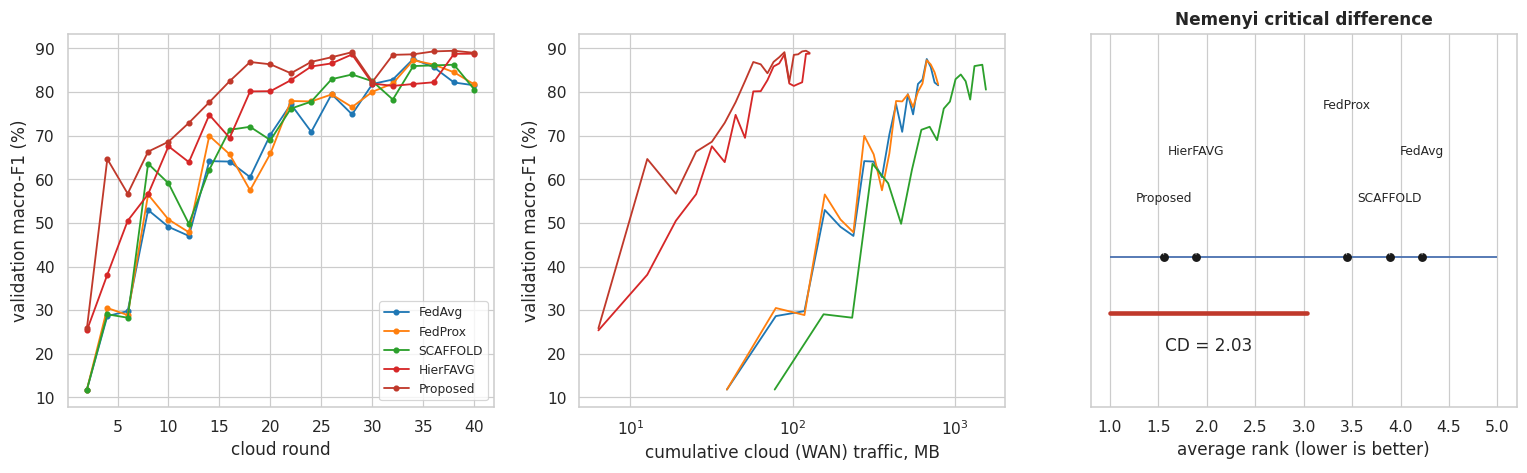

In [22]:
# ============================== 7. MAIN FEDERATED COMPARISON ==============================
FLR = {}
for s in CFG["FL_SEEDS"]:
    for alg in CFG["FL_ALGS"]:
        print(f"FL main: {alg} seed {s}"); FLR[(alg, s)] = fl("main", alg=alg, K=CFG["K_PER_ORG"], seed=s)
rows = []
for alg in CFG["FL_ALGS"]:
    rr = [FLR[(alg, s)] for s in CFG["FL_SEEDS"]]
    r = {"Method": alg + (" (TG-Fog, proposed)" if alg == "Proposed" else ""), "Topology": "client-fog-cloud" if alg in ("HierFAVG", "Proposed") else "flat"}
    for k in ["F1", "Acc", "MCC", "FPR", "DR"]: r[k] = ms([x["test"]["mean"][k] for x in rr], 3 if k == "MCC" else 2)
    for nm in ORGS: r[f"F1 {nm}"] = ms([x["test"][nm]["F1"] for x in rr])
    r["Cloud traffic (MB)"] = ms([(x["comm"]["cloud_up"] + x["comm"]["cloud_down"]) / 1e6 for x in rr], 1)
    r["Edge (LAN) traffic (MB)"] = ms([(x["comm"].get("edge_up", 0) + x["comm"].get("edge_down", 0)) / 1e6 for x in rr], 1)
    r["Parallel time (s)"] = ms([x["t_parallel"] for x in rr], 1)
    rows.append(r)
ref = [CEN[(PROP, s)]["test"]["mean"]["F1"] for s in CFG["SEEDS"]]
rows.append({"Method": "Centralised TG-EGNN (no privacy, reference)", "Topology": "pooled", "F1": ms(ref)})
add_table("T08_fl_main", pd.DataFrame(rows), f"Federated results, {CFG['K_PER_ORG']} clients per organisation ({CFG['K_PER_ORG']*len(ORGS)} total), {CFG['ROUNDS']} cloud rounds")

# statistics: pairs = (seed, organisation)
pairs = lambda alg: [FLR[(alg, s)]["test"][nm]["F1"] for s in CFG["FL_SEEDS"] for nm in ORGS]
rows, ps = [], []
for alg in [a for a in CFG["FL_ALGS"] if a != "Proposed"]:
    pt = paired(pairs("Proposed"), pairs(alg)); ps.append(pt["p_w"] if np.isfinite(pt.get("p_w", np.nan)) else pt["p_t"])
    rows.append({"Proposed vs": alg, "mean ΔF1": pt["mean_diff"], "95% CI": f"[{pt['ci_lo']:.2f}, {pt['ci_hi']:.2f}]", "wins": f"{pt['wins']}/{pt['n']}",
                 "p (Wilcoxon)": pt["p_w"], "p (paired t)": pt["p_t"], "rank-biserial": pt["rank_biserial"]})
for r, p in zip(rows, holm(ps)): r["p (Holm)"] = p
add_table("T09_fl_stats", pd.DataFrame(rows), "Paired comparison of the proposed protocol with each baseline (seed × organisation pairs, Holm-corrected)")
M = np.array([pairs(a) for a in CFG["FL_ALGS"]]).T; fn = friedman_nemenyi(M, CFG["FL_ALGS"])
add_table("T10_friedman", pd.DataFrame([{"Method": k, "Average rank": v} for k, v in fn["avg_rank"].items()] +
                                       [{"Method": f"Friedman chi2={fn['chi2']:.2f}, p={fn['p']:.2e}; Nemenyi CD={fn['CD']:.2f}", "Average rank": np.nan}]),
          "Friedman test and average ranks of the federated methods")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for i, alg in enumerate(CFG["FL_ALGS"]):
    lg = pd.DataFrame(FLR[(alg, CFG["FL_SEEDS"][0])]["log"]); col = PROP_COLOR if alg == "Proposed" else PAL[i]
    axes[0].plot(lg["round"], lg.val_F1, "-o", ms=3, label=alg, color=col); axes[1].plot(lg.cloud_MB, lg.val_F1, "-", label=alg, color=col)
axes[0].set_xlabel("cloud round"); axes[0].set_ylabel("validation macro-F1 (%)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("cumulative cloud (WAN) traffic, MB"); axes[1].set_xscale("log"); axes[1].set_ylabel("validation macro-F1 (%)")
ranks = fn["avg_rank"]; order = sorted(ranks, key=ranks.get)
axes[2].hlines(0, 1, len(order)); axes[2].plot([ranks[o] for o in order], [0] * len(order), "o", color="k")
for j, o in enumerate(order): axes[2].annotate(o, (ranks[o], 0), xytext=(ranks[o], 0.3 + 0.25 * (j % 3)), ha="center", fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.5))
axes[2].plot([1, 1 + fn["CD"]], [-0.3, -0.3], "-", color=PROP_COLOR, lw=3); axes[2].text(1 + fn["CD"] / 2, -0.5, f"CD = {fn['CD']:.2f}", ha="center")
axes[2].set_ylim(-0.8, 1.2); axes[2].set_yticks([]); axes[2].set_xlabel("average rank (lower is better)"); axes[2].set_title("Nemenyi critical difference")
save_fig(fig, "F07_fl_convergence", "Convergence, accuracy versus WAN traffic, and critical-difference diagram of the federated methods")

stage_stop("T08")   # planned stop (see STOP_AFTER in the configuration cell)


In [23]:
# ---------- ablation of the federated protocol ----------
# rows adapt to the configuration selected in 6b (a component that is already off is not "removed" again)
_other = "hard" if CFG["REP_MODE"] == "soft" else "soft"
FL_ABL = {"w/o reputation filter (mean at fog)": dict(defense="Mean"),
          f"{_other} instead of {CFG['REP_MODE']} trust": dict(rep_mode=_other)}
if CFG["SPARSIFY"] < 1.0: FL_ABL["w/o sparsification (dense SA)"] = dict(sparsify=1.0)
if CFG["SERVER_MOM"] > 0: FL_ABL["w/o server momentum"] = dict(server_mom=0.0)
FL_ABL["w/o graph (EdgeMLP body)"] = dict(model_kw=VARIANTS["EdgeMLP"])
rows = [{"Variant": "Full proposed", "F1": ms([FLR[("Proposed", s)]["test"]["mean"]["F1"] for s in CFG["FL_SEEDS"]]),
         "Cloud MB": ms([(FLR[("Proposed", s)]["comm"]["cloud_up"] + FLR[("Proposed", s)]["comm"]["cloud_down"]) / 1e6 for s in CFG["FL_SEEDS"]], 2)}]
for an, kw in FL_ABL.items():
    rr = [fl("ablfl_" + re.sub("[^A-Za-z]", "", an), alg="Proposed", K=CFG["K_PER_ORG"], seed=s, **kw) for s in CFG["FL_SEEDS"]]
    pt = paired([x["test"]["mean"]["F1"] for x in rr], [FLR[("Proposed", s)]["test"]["mean"]["F1"] for s in CFG["FL_SEEDS"]])
    rows.append({"Variant": an, "F1": ms([x["test"]["mean"]["F1"] for x in rr]), "Cloud MB": ms([(x["comm"]["cloud_up"] + x["comm"]["cloud_down"]) / 1e6 for x in rr], 2),
                 "ΔF1": f"{pt['mean_diff']:+.2f}", "p (paired t)": pt["p_t"]})
add_table("T11_fl_ablation", pd.DataFrame(rows), "Ablation of the federated protocol (no attack)")
rows = []
# communication trade-off of the SA-compatible rotating mask, measured with server momentum OFF: T08a showed that server momentum
# and error-feedback sparsification interfere (stale accumulated coordinates are amplified by the momentum)
for sp in CFG["SPARSIFY_GRID"]:
    rr = [fl("sparsity_mom0", alg="Proposed", K=CFG["K_PER_ORG"], seed=s, sparsify=sp, server_mom=0.0) for s in CFG["FL_SEEDS"]]
    rows.append({"Kept fraction of coordinates": sp, "F1": ms([x["test"]["mean"]["F1"] for x in rr]),
                 "Cloud uplink (MB)": ms([x["comm"]["cloud_up"] / 1e6 for x in rr], 3), "Cloud total (MB)": ms([(x["comm"]["cloud_up"] + x["comm"]["cloud_down"]) / 1e6 for x in rr], 2)})
SPT = add_table("T11b_sparsity", pd.DataFrame(rows), "Communication trade-off of the SA-compatible rotating mask (server momentum off)")

stage_stop("T11")   # planned stop (see STOP_AFTER in the configuration cell)



=== Table [T11_fl_ablation] Ablation of the federated protocol (no attack)
                            Variant           F1      Cloud MB    ΔF1  p (paired t)
                      Full proposed 89.23 ± 1.09 127.00 ± 0.00    NaN           NaN
w/o reputation filter (mean at fog) 89.95 ± 2.70 127.00 ± 0.00  +0.72      0.713616
         hard instead of soft trust 82.34 ± 5.18 127.00 ± 0.00  -6.89      0.186628
                w/o server momentum 87.90 ± 4.90 127.00 ± 0.00  -1.33      0.714093
           w/o graph (EdgeMLP body) 75.44 ± 2.46  16.22 ± 0.00 -13.79      0.021329

=== Table [T11b_sparsity] Communication trade-off of the SA-compatible rotating mask (server momentum off)
 Kept fraction of coordinates           F1 Cloud uplink (MB) Cloud total (MB)
                         0.10 82.42 ± 1.16     5.773 ± 0.000     69.27 ± 0.00
                         0.25 85.78 ± 3.34    12.700 ± 0.000     76.20 ± 0.00
                         1.00 86.38 ± 1.63    63.501 ± 0.000    127.00 ± 0.00


### 7b. Composition-augmented federated learning
T07b/T07d showed that models trained on time-ordered windows fail on windows with a mixed label composition (and vice versa).
Here every federated method is (a) tested on both kinds of test windows and (b) retrained with **local composition
augmentation**: each client also trains on windows built from its own flows in random order. Nothing leaves the client and
no communication is added. All later federated experiments (scalability, DP, poisoning, zero-day, adversarial) use it.


In [24]:
# ============================== 7b. COMPOSITION-AUGMENTED FEDERATED LEARNING ==============================
# (a) the federated models of T08 (trained on time-ordered client windows) are also tested on mixed test windows;
# (b) every method is retrained with LOCAL composition augmentation: each client adds windows built from its own flows in random
#     order (no data leaves the client, no extra communication); model selection uses ordered + mixed validation windows.
# The configuration selected in 6b is kept unchanged.
def fl_state_model(res, model_kw=None):
    m = build(model_kw or VARIANTS[PROP]); sn = SHARED(m); set_vec(m, sn, res["state"]["g"])
    for nm in ORGS: set_vec(m, org_names(m, nm), res["state"]["adp"][nm])
    return m.eval()
def eval_both_fl(res, s, key):
    return cached(f"flboth_{key}", lambda: dict(ordered=res["test"], mixed=eval_orgs(fl_state_model(res), W_override=mixw("te", s))))

FLA, BOTH = {}, {}
for s in CFG["FL_SEEDS"]:
    for alg in CFG["FL_ALGS"]:
        print(f"FL composition-augmented: {alg} seed {s}"); FLA[(alg, s)] = fl("main", alg=alg, K=CFG["K_PER_ORG"], seed=s, aug=True)
for s in CFG["FL_SEEDS"]:
    for alg in CFG["FL_ALGS"]:
        BOTH[("plain", alg, s)] = eval_both_fl(FLR[(alg, s)], s, f"plain_{alg}_s{s}_{fl_tag()}")
        BOTH[("aug", alg, s)] = eval_both_fl(FLA[(alg, s)], s, f"aug_{alg}_s{s}_{fl_tag()}")

rows = []
for st, lab in [("plain", "time-ordered client windows"), ("aug", "+ local composition augmentation")]:
    for alg in CFG["FL_ALGS"]:
        g = lambda t, k="F1": [BOTH[(st, alg, s)][t]["mean"][k] for s in CFG["FL_SEEDS"]]
        src = FLR if st == "plain" else FLA
        rows.append({"Training": lab, "Method": alg + (" (proposed)" if alg == "Proposed" else ""),
                     "F1 ordered test": ms(g("ordered")), "F1 mixed test": ms(g("mixed")),
                     "Worst-case F1": ms([min(a, b) for a, b in zip(g("ordered"), g("mixed"))]),
                     "FPR ordered": ms(g("ordered", "FPR")), "FPR mixed": ms(g("mixed", "FPR")),
                     "Cloud MB": ms([(src[(alg, s)]["comm"]["cloud_up"] + src[(alg, s)]["comm"]["cloud_down"]) / 1e6 for s in CFG["FL_SEEDS"]], 1)})
add_table("T08b_fl_composition", pd.DataFrame(rows), "Federated methods on time-ordered and mixed test windows, without and with local composition augmentation")

rows = []
for t in ["ordered", "mixed"]:
    ps, rr = [], []
    for alg in [a for a in CFG["FL_ALGS"] if a != "Proposed"]:
        pa = [BOTH[("aug", "Proposed", s)][t][nm]["F1"] for s in CFG["FL_SEEDS"] for nm in ORGS]
        pb = [BOTH[("aug", alg, s)][t][nm]["F1"] for s in CFG["FL_SEEDS"] for nm in ORGS]
        pt = paired(pa, pb); ps.append(pt["p_w"] if np.isfinite(pt.get("p_w", np.nan)) else pt["p_t"])
        rr.append({"Test windows": t, "Proposed vs": alg, "mean ΔF1": pt["mean_diff"], "95% CI": f"[{pt['ci_lo']:.2f}, {pt['ci_hi']:.2f}]",
                   "wins": f"{pt['wins']}/{pt['n']}", "p (Wilcoxon)": pt["p_w"], "p (paired t)": pt["p_t"]})
    for r, p in zip(rr, holm(ps)): r["p (Holm)"] = p
    rows += rr
add_table("T08c_fl_composition_stats", pd.DataFrame(rows), "Paired comparisons with local composition augmentation (seed x organisation pairs, Holm-corrected per test type)")

CFG["FL_AUG"] = True      # every federated experiment after this point uses local composition augmentation
print("From here on: FL_AUG = True | fl tag:", fl_tag())
stage_stop("T08b")   # planned stop (see STOP_AFTER in the configuration cell)


FL composition-augmented: FedAvg seed 42
FL composition-augmented: FedProx seed 42
FL composition-augmented: SCAFFOLD seed 42
FL composition-augmented: HierFAVG seed 42
FL composition-augmented: Proposed seed 42
FL composition-augmented: FedAvg seed 43
FL composition-augmented: FedProx seed 43
FL composition-augmented: SCAFFOLD seed 43
FL composition-augmented: HierFAVG seed 43
FL composition-augmented: Proposed seed 43
FL composition-augmented: FedAvg seed 44
FL composition-augmented: FedProx seed 44
FL composition-augmented: SCAFFOLD seed 44
FL composition-augmented: HierFAVG seed 44
FL composition-augmented: Proposed seed 44

=== Table [T08b_fl_composition] Federated methods on time-ordered and mixed test windows, without and with local composition augmentation
                        Training              Method F1 ordered test F1 mixed test Worst-case F1 FPR ordered   FPR mixed     Cloud MB
     time-ordered client windows              FedAvg    79.53 ± 2.42  47.27 ± 3.12  47.27 ±

scale K/org=10 FedAvg seed 42
scale K/org=10 FedAvg seed 43
scale K/org=10 HierFAVG seed 42
scale K/org=10 HierFAVG seed 43
scale K/org=10 Proposed seed 42
scale K/org=10 Proposed seed 43
scale K/org=30 FedAvg seed 42
scale K/org=30 FedAvg seed 43
scale K/org=30 HierFAVG seed 42
scale K/org=30 HierFAVG seed 43
scale K/org=30 Proposed seed 42
scale K/org=30 Proposed seed 43
scale K/org=100 FedAvg seed 42
scale K/org=100 FedAvg seed 43
scale K/org=100 HierFAVG seed 42
scale K/org=100 HierFAVG seed 43
scale K/org=100 Proposed seed 42
scale K/org=100 Proposed seed 43

=== Table [T12_scalability] Scalability with the number of clients
 Clients   Method           F1        Cloud MB       Edge MB Parallel time (s) Client step time (ms)
      30   FedAvg 90.31 ± 5.27   262.69 ± 0.13     0.0 ± 0.0        28.9 ± 0.1           345.6 ± 0.7
      30 HierFAVG 91.87 ± 1.29   127.00 ± 0.00   525.3 ± 0.0       116.0 ± 4.7          362.8 ± 20.8
      30 Proposed 93.02 ± 1.71   127.00 ± 0.00   525.3 ± 0.

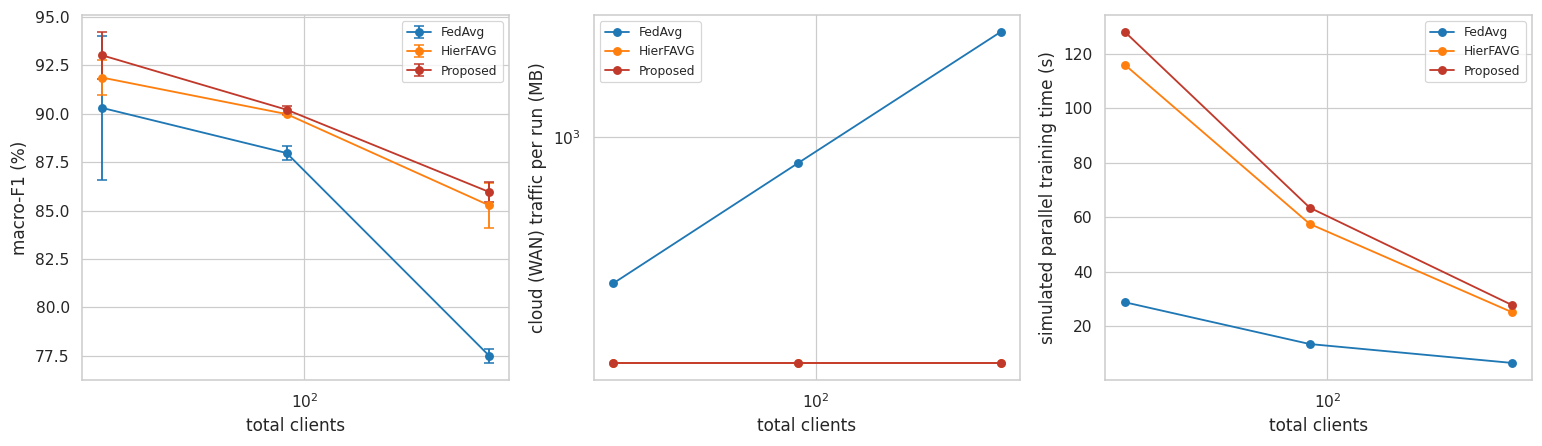

In [25]:
# ============================== 8. SCALABILITY ==============================
SC = {}
for K in CFG["SCALE_K"]:
    for alg in CFG["SCALE_ALGS"]:
        for s in CFG["SCALE_SEEDS"]:
            print(f"scale K/org={K} {alg} seed {s}"); SC[(K, alg, s)] = fl("scale", alg=alg, K=K, seed=s)
for f in CFG["SCALE_FOGS"]:
    for s in CFG["SCALE_SEEDS"]: SC[("fogs", f, s)] = fl("scalefog", alg="Proposed", K=max(CFG["SCALE_K"]), seed=s, fogs_per_org=f)
rows = []
for K in CFG["SCALE_K"]:
    for alg in CFG["SCALE_ALGS"]:
        rr = [SC[(K, alg, s)] for s in CFG["SCALE_SEEDS"]]
        rows.append({"Clients": K * len(ORGS), "Method": alg, "F1": ms([x["test"]["mean"]["F1"] for x in rr]),
                     "Cloud MB": ms([(x["comm"]["cloud_up"] + x["comm"]["cloud_down"]) / 1e6 for x in rr], 2),
                     "Edge MB": ms([(x["comm"].get("edge_up", 0) + x["comm"].get("edge_down", 0)) / 1e6 for x in rr], 1),
                     "Parallel time (s)": ms([x["t_parallel"] for x in rr], 1), "Client step time (ms)": ms([1000 * x["t_client_mean"] for x in rr], 1)})
add_table("T12_scalability", pd.DataFrame(rows), "Scalability with the number of clients")
rows = [{"Fog nodes": f * len(ORGS), "F1": ms([SC[("fogs", f, s)]["test"]["mean"]["F1"] for s in CFG["SCALE_SEEDS"]]),
         "Cloud MB": ms([(SC[("fogs", f, s)]["comm"]["cloud_up"] + SC[("fogs", f, s)]["comm"]["cloud_down"]) / 1e6 for s in CFG["SCALE_SEEDS"]], 2),
         "Secure-aggregation time (s)": ms([SC[("fogs", f, s)]["sa_time"] for s in CFG["SCALE_SEEDS"]], 2)} for f in CFG["SCALE_FOGS"]]
add_table("T13_fog_scaling", pd.DataFrame(rows), f"Effect of the number of fog nodes ({max(CFG['SCALE_K'])*len(ORGS)} clients, proposed)")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3)); Ks = [K * len(ORGS) for K in CFG["SCALE_K"]]
for i, alg in enumerate(CFG["SCALE_ALGS"]):
    col = PROP_COLOR if alg == "Proposed" else PAL[i]
    f1 = np.array([[SC[(K, alg, s)]["test"]["mean"]["F1"] for s in CFG["SCALE_SEEDS"]] for K in CFG["SCALE_K"]])
    mb = np.array([[(SC[(K, alg, s)]["comm"]["cloud_up"] + SC[(K, alg, s)]["comm"]["cloud_down"]) / 1e6 for s in CFG["SCALE_SEEDS"]] for K in CFG["SCALE_K"]])
    tp = np.array([[SC[(K, alg, s)]["t_parallel"] for s in CFG["SCALE_SEEDS"]] for K in CFG["SCALE_K"]])
    axes[0].errorbar(Ks, f1.mean(1), f1.std(1), marker="o", capsize=3, label=alg, color=col)
    axes[1].plot(Ks, mb.mean(1), "-o", label=alg, color=col); axes[2].plot(Ks, tp.mean(1), "-o", label=alg, color=col)
for ax, yl in zip(axes, ["macro-F1 (%)", "cloud (WAN) traffic per run (MB)", "simulated parallel training time (s)"]):
    ax.set_xscale("log"); ax.set_xlabel("total clients"); ax.set_ylabel(yl); ax.legend(fontsize=8)
axes[1].set_yscale("log")
save_fig(fig, "F08_scalability", "Detection performance, WAN traffic and parallel time versus the number of clients")

## 5. Privacy: secure aggregation, client-level differential privacy and a membership-inference audit


=== Table [T14_secure_agg] Secure aggregation (pairwise masking, Z/2^32): exactness and overhead
 Parties (fogs)  Vector length  Max |masked sum - plain sum|  Masking time / party (ms)  Total time (ms)  Bytes / party  Plain fp32 bytes / party
              3          10000                      0.000022                   0.665188         2.141237          40000                     40000
              3         100000                      0.000022                   1.272996         4.311085         400000                    400000
              6          10000                      0.000035                   0.458320         2.822638          40000                     40000
              6         100000                      0.000040                   2.353350        14.555931         400000                    400000
             12          10000                      0.000058                   0.976225        11.816978          40000                     40000
             12         10

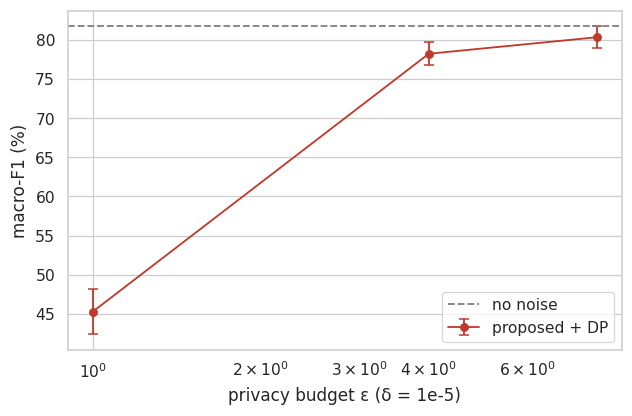


=== Table [T16_mia] Loss-threshold membership-inference audit (0.5 AUC / 1% TPR = no leakage). A weak, non-adaptive attack: an AUC near 0.5 is not a privacy guarantee
   Model Organisation  MIA AUC  TPR @ 1% FPR (%)
no noise      TON_IoT 0.530841          1.388889
no noise Edge-IIoTset 0.464048          0.879770
no noise      BoT-IoT 0.557583          0.174753
  DP ε=1      TON_IoT 0.510740          0.855042
  DP ε=1 Edge-IIoTset 0.490552          1.533117
  DP ε=1      BoT-IoT 0.514112          1.054250
  DP ε=8      TON_IoT 0.526649          1.596602
  DP ε=8 Edge-IIoTset 0.464838          1.679119
  DP ε=8      BoT-IoT 0.536549          0.678454


,Model,Organisation,MIA AUC,TPR @ 1% FPR (%)
0,no noise,TON_IoT,0.530841,1.388889
1,no noise,Edge-IIoTset,0.464048,0.879770
2,no noise,BoT-IoT,0.557583,0.174753
3,DP ε=1,TON_IoT,0.510740,0.855042
4,DP ε=1,Edge-IIoTset,0.490552,1.533117
5,DP ε=1,BoT-IoT,0.514112,1.054250
6,DP ε=8,TON_IoT,0.526649,1.596602
7,DP ε=8,Edge-IIoTset,0.464838,1.679119
8,DP ε=8,BoT-IoT,0.536549,0.678454


In [26]:
# ============================== 9. PRIVACY ==============================
def fl_model(res):
    """Rebuild a standalone model from a federated run's best global state (shared vector + organisation adapters)."""
    m = build(VARIANTS[PROP]); sn = SHARED(m); set_vec(m, sn, res["state"]["g"])
    for nm in ORGS: set_vec(m, org_names(m, nm), res["state"]["adp"][nm])
    return m.eval()

# (a) secure aggregation: exactness and cost
rows = []
for n_f in [3, 6, 12, 24]:
    for dim in [10_000, 100_000]:
        rng = np.random.default_rng(0); V = [rng.normal(0, 0.01, dim).astype(np.float32) for _ in range(n_f)]
        t0 = time.time(); S, sa = secure_sum(V, 1234); t = time.time() - t0
        rows.append({"Parties (fogs)": n_f, "Vector length": dim, "Max |masked sum - plain sum|": float(np.abs(S - np.sum(V, 0)).max()),
                     "Masking time / party (ms)": 1000 * sa.t_mask / n_f, "Total time (ms)": 1000 * t, "Bytes / party": sa.bytes_up // n_f,
                     "Plain fp32 bytes / party": dim * 4})
add_table("T14_secure_agg", pd.DataFrame(rows), "Secure aggregation (pairwise masking, Z/2^32): exactness and overhead")

# (b0) clipping bound chosen on VALIDATION data (tuning seed, ε = DP_TUNE_EPS); test data not used
rows = []
for cb in CFG["DP_CLIP_GRID"]:
    print(f"DP clip tuning: C={cb}")
    r = cached(f"tune_dpclip_{cb}_eps{CFG['DP_TUNE_EPS']}_K{CFG['DP_K']}_{fl_tag()}_s{CFG['TUNE_SEED']}",
               lambda: FLRun("Proposed", CFG["DP_K"], CFG["TUNE_SEED"], dp_eps=CFG["DP_TUNE_EPS"], dp_clip=cb).run())
    rows.append({"Clipping bound C": cb, "ε": CFG["DP_TUNE_EPS"], "best validation F1": r["best_val"]})
TC = pd.DataFrame(rows); DPC = float(TC.sort_values("best validation F1", ascending=False).iloc[0]["Clipping bound C"])
TC["selected"] = TC["Clipping bound C"] == DPC
add_table("T15a_dp_clip_tuning", TC, f"Clipping bound selected on validation data (tuning seed {CFG['TUNE_SEED']}, {CFG['DP_K']*len(ORGS)} clients)")
CFG["DP_CLIP"] = DPC; print("Selected DP clipping bound C =", DPC)

# (b) DP utility curve (with the selected clipping bound)
DP = {}
for eps in CFG["DP_EPS"] + [float("inf")]:
    for s in CFG["DP_SEEDS"]:
        print(f"DP eps={eps} seed {s}"); DP[(eps, s)] = fl("dp", alg="Proposed", K=CFG["DP_K"], seed=s, dp_eps=eps, dp_clip=DPC)
rows = []
for eps in CFG["DP_EPS"] + [float("inf")]:
    rr = [DP[(eps, s)] for s in CFG["DP_SEEDS"]]
    rows.append({"Target ε": "∞ (no noise, clipping + SA only)" if not np.isfinite(eps) else eps, "Achieved ε (δ=1e-5)": ms([x["eps"] for x in rr], 2),
                 "Noise multiplier σ": ms([x["sigma"] for x in rr], 3), "Sampling rate q": rr[0]["q"], "F1": ms([x["test"]["mean"]["F1"] for x in rr]),
                 "FPR": ms([x["test"]["mean"]["FPR"] for x in rr])})
add_table("T15_dp", pd.DataFrame(rows), f"Client-level DP towards the cloud ({CFG['DP_K']*len(ORGS)} clients, C = {DPC}, noise added once after secure aggregation)")

# (b2) population sweep: client-level DP needs many clients per round (noise std on the average update = σ·C / clients per round)
DPP = {}
for kp in CFG["DP_POP_K"]:
    for eps in [CFG["DP_TUNE_EPS"], float("inf")]:
        for s in CFG["DP_POP_SEEDS"]:
            print(f"DP population: {kp*len(ORGS)} clients, eps={eps}, seed {s}")
            DPP[(kp, eps, s)] = fl("dp", alg="Proposed", K=kp, seed=s, dp_eps=eps, dp_clip=DPC)
rows = []
for kp in CFG["DP_POP_K"]:
    a = [DPP[(kp, CFG["DP_TUNE_EPS"], s)] for s in CFG["DP_POP_SEEDS"]]; b = [DPP[(kp, float("inf"), s)] for s in CFG["DP_POP_SEEDS"]]
    rows.append({"Clients": kp * len(ORGS), "Clients per round": int(round(a[0]["q"] * kp * len(ORGS))), "σ": ms([x["sigma"] for x in a], 3),
                 f"F1 at ε={CFG['DP_TUNE_EPS']}": ms([x["test"]["mean"]["F1"] for x in a]), "F1 without noise": ms([x["test"]["mean"]["F1"] for x in b]),
                 "Utility cost of DP (F1 points)": f"{np.mean([x['test']['mean']['F1'] for x in b]) - np.mean([x['test']['mean']['F1'] for x in a]):.2f}",
                 f"FPR at ε={CFG['DP_TUNE_EPS']}": ms([x["test"]["mean"]["FPR"] for x in a])})
add_table("T15b_dp_population", pd.DataFrame(rows), f"Cost of client-level DP versus federation size (ε = {CFG['DP_TUNE_EPS']}, δ = 1e-5, C = {DPC})")
fig, ax = plt.subplots(figsize=(6.5, 4))
xs = CFG["DP_EPS"]; f1 = np.array([[DP[(e, s)]["test"]["mean"]["F1"] for s in CFG["DP_SEEDS"]] for e in xs])
ax.errorbar(xs, f1.mean(1), f1.std(1), marker="o", capsize=3, color=PROP_COLOR, label="proposed + DP")
inf = np.mean([DP[(float("inf"), s)]["test"]["mean"]["F1"] for s in CFG["DP_SEEDS"]]); ax.axhline(inf, ls="--", color="gray", label="no noise")
ax.set_xscale("log"); ax.set_xlabel("privacy budget ε (δ = 1e-5)"); ax.set_ylabel("macro-F1 (%)"); ax.legend()
save_fig(fig, "F09_dp_tradeoff", "Privacy-utility trade-off of client-level DP")

# (c) membership inference audit on the final global models
def mia_for(res, nm, seed):
    m = fl_model(res)
    parts = partition(nm, CFG["DP_K"], CFG["PARTITION"], CFG["ALPHA"], seed + ORGS.index(nm))   # same partition as the audited run
    ix = np.sort(np.concatenate(parts))
    mem = windows_from(ORG[nm]["XQ"][ix], RAW[nm]["y"][ix], RAW[nm]["t"][ix], RAW[nm]["src"][ix], RAW[nm]["dst"][ix], CFG["WIN_CLIENT"])[: CFG.get("MIA_WIN", 200)]
    # non-members: held-out test flows cut into windows of the SAME size as the members' (client) windows, so the attack cannot
    # separate the two groups by window size (graph context) instead of by membership
    it = ORG[nm]["te_idx"]
    non = windows_from(ORG[nm]["XQ"][it], RAW[nm]["y"][it], RAW[nm]["t"][it], RAW[nm]["src"][it], RAW[nm]["dst"][it], CFG["WIN_CLIENT"])[: CFG.get("MIA_WIN", 200)]
    lm = []; ln = []
    with torch.no_grad():
        for W, L in [(mem, lm), (non, ln)]:
            for i in range(0, len(W), 4):
                b = collate(W[i:i + 4]); lg, _ = m(b, nm); L.append(F.cross_entropy(lg, b["y"], reduction="none").cpu().numpy())
    lm, ln = np.concatenate(lm), np.concatenate(ln); n = min(len(lm), len(ln), 100000)
    rg = np.random.default_rng(0); return mia_loss_audit(rg.choice(lm, n, False), rg.choice(ln, n, False))
rows = []
for eps in [float("inf")] + CFG["DP_EPS"][:1] + CFG["DP_EPS"][-1:]:
    for nm in ORGS:
        a = cached(f"mia_{eps}_{nm}_C{DPC}_{fl_tag()}_w{CFG.get('MIA_WIN', 200)}_samewin", lambda: mia_for(DP[(eps, CFG["DP_SEEDS"][0])], nm, CFG["DP_SEEDS"][0]))
        rows.append({"Model": "no noise" if not np.isfinite(eps) else f"DP ε={eps}", "Organisation": nm, "MIA AUC": a["AUC"], "TPR @ 1% FPR (%)": a["TPR_at_1FPR"]})
add_table("T16_mia", pd.DataFrame(rows), "Loss-threshold membership-inference audit (0.5 AUC / 1% TPR = no leakage). A weak, non-adaptive attack: an AUC near 0.5 is not a privacy guarantee")

## 6. Poisoning resilience (Byzantine and backdoor clients)
Malicious clients are spread uniformly over the organisations. Data poisoning: **label flipping** (attack flows relabelled
benign) and a **feature-trigger backdoor** (half of a client's attack flows get a 3-feature trigger and the benign label;
attack success rate = triggered test attacks classified benign). Model poisoning: **sign flip**, **scaling** (model replacement: label-flipped training
with the update boosted ×10), and the omniscient **ALIE** and **IPM** attacks. Every defence runs at the fog inside the same hierarchical protocol.


=== Table [T17_byzantine] Macro-F1 (%) under poisoning attacks for each fog-side defence ('Proposed' = temporal reputation)
    Attack  Malicious %        Mean      Median TrimmedMean   MultiKrum     FLTrust    Proposed Proposed+NB
      none            0  88.4 ± 0.8  88.3 ± 0.9  89.1 ± 2.5  88.1 ± 0.2  73.4 ± 2.9  88.3 ± 1.6  89.0 ± 0.7
label_flip           10  83.3 ± 6.1  86.2 ± 3.2  85.1 ± 2.9  85.3 ± 1.0  59.7 ± 6.0  88.0 ± 1.0  85.2 ± 2.6
label_flip           30  66.7 ± 2.8  73.0 ± 6.5  76.9 ± 4.0 72.4 ± 11.2  44.7 ± 1.0  77.1 ± 4.9  71.1 ± 0.4
  backdoor           10  87.1 ± 4.7  88.1 ± 0.3  87.9 ± 2.2  87.9 ± 3.3  70.5 ± 2.2  88.4 ± 2.5  88.0 ± 1.2
  backdoor           30  89.1 ± 1.6  87.0 ± 1.3  89.1 ± 1.3  86.7 ± 1.7  74.9 ± 5.1  87.7 ± 1.2  89.9 ± 2.3
      alie           10  87.8 ± 0.8  87.7 ± 1.4  87.8 ± 1.5  88.9 ± 3.8  74.5 ± 1.8  88.7 ± 0.3  88.1 ± 0.9
      alie           30  89.2 ± 1.7  85.8 ± 4.0  88.0 ± 1.3  88.3 ± 2.9  74.4 ± 7.2  87.7 ± 1.1  89.8 ± 1.3
       ipm 

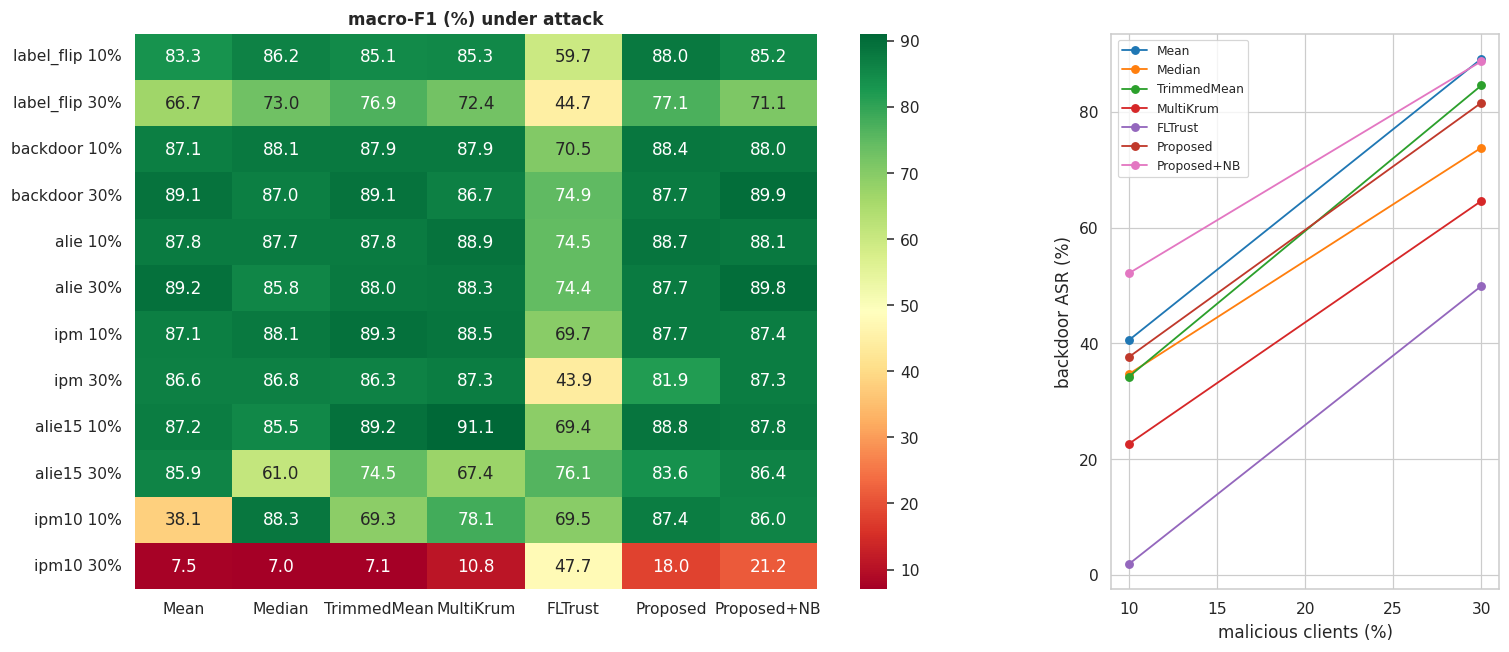


=== Table [T17b_poisoning_stats] Paired comparison of the defences over all attack cells (attack x fraction x seed x organisation), Holm-corrected
    Defence          vs  mean ΔF1 under attack         95% CI   wins  p (Wilcoxon)     p (Holm)
   Proposed        Mean               5.782061   [2.32, 9.25] 66/108  4.470214e-03 1.497985e-02
   Proposed      Median               3.380182   [1.45, 5.31] 66/108  2.995971e-03 1.497985e-02
   Proposed TrimmedMean               2.869526   [0.54, 5.20] 57/108  1.216471e-01 2.432943e-01
   Proposed   MultiKrum               2.694458   [0.82, 4.57] 70/108  3.159971e-03 1.497985e-02
   Proposed     FLTrust              15.836301 [10.88, 20.79] 88/108  1.337293e-09 8.023759e-09
   Proposed Proposed+NB              -0.270970  [-1.66, 1.12] 51/108  7.048201e-01 7.048201e-01
Proposed+NB        Mean               6.053031   [2.76, 9.34] 71/108  3.277610e-05 1.638805e-04
Proposed+NB      Median               3.651152   [1.49, 5.81] 65/108  5.329773e-04 2

,Defence,Average rank (1 = best),Worst-case macro-F1 over attack cells
0,Mean,4.666667,7.544467
1,Median,4.250000,7.029597
2,TrimmedMean,3.916667,7.065378
3,MultiKrum,3.333333,10.768737
4,FLTrust,6.083333,43.899126
5,Proposed,2.916667,18.045689
6,Proposed+NB,2.833333,21.163080


In [27]:
# ============================== 10. POISONING ==============================
BZ = {}
for att in CFG["BYZ_ATTACKS"]:
    for fr in CFG["BYZ_FRACS"]:
        for de in CFG["BYZ_DEFENSES"]:
            for s in CFG["BYZ_SEEDS"]:
                BZ[(att, fr, de, s)] = fl("byz", alg="Proposed", K=CFG["BYZ_K"], seed=s, attack=att, mal_frac=fr, defense=de, rounds=CFG["BYZ_ROUNDS"])
for de in CFG["BYZ_DEFENSES"]:
    for s in CFG["BYZ_SEEDS"]: BZ[("none", 0, de, s)] = fl("byz", alg="Proposed", K=CFG["BYZ_K"], seed=s, defense=de, rounds=CFG["BYZ_ROUNDS"])
rows = []
for att in ["none"] + CFG["BYZ_ATTACKS"]:
    for fr in ([0] if att == "none" else CFG["BYZ_FRACS"]):
        r = {"Attack": att, "Malicious %": int(100 * fr)}
        for de in CFG["BYZ_DEFENSES"]:
            r[de] = ms([BZ[(att, fr, de, s)]["test"]["mean"]["F1"] for s in CFG["BYZ_SEEDS"]], 1)
        rows.append(r)
add_table("T17_byzantine", pd.DataFrame(rows), "Macro-F1 (%) under poisoning attacks for each fog-side defence ('Proposed' = temporal reputation)")
rows = []
for fr in CFG["BYZ_FRACS"]:
    rows.append({"Malicious %": int(100 * fr), **{de: ms([BZ[("backdoor", fr, de, s)].get("ASR", np.nan) for s in CFG["BYZ_SEEDS"]], 1) for de in CFG["BYZ_DEFENSES"]}})
add_table("T18_backdoor_asr", pd.DataFrame(rows), "Backdoor attack success rate (%, lower is better)")
H = pd.DataFrame({de: [np.mean([BZ[(a, f, de, s)]["test"]["mean"]["F1"] for s in CFG["BYZ_SEEDS"]]) for a in CFG["BYZ_ATTACKS"] for f in CFG["BYZ_FRACS"]]
                  for de in CFG["BYZ_DEFENSES"]}, index=[f"{a} {int(100*f)}%" for a in CFG["BYZ_ATTACKS"] for f in CFG["BYZ_FRACS"]])
fig, axes = plt.subplots(1, 2, figsize=(16, 0.38 * len(H) + 2), gridspec_kw=dict(width_ratios=[2.2, 1]))
sns.heatmap(H, annot=True, fmt=".1f", cmap="RdYlGn", ax=axes[0]); axes[0].set_title("macro-F1 (%) under attack")
for i, de in enumerate(CFG["BYZ_DEFENSES"]):
    v = [np.mean([BZ[("backdoor", f, de, s)].get("ASR", np.nan) for s in CFG["BYZ_SEEDS"]]) for f in CFG["BYZ_FRACS"]]
    axes[1].plot([100 * f for f in CFG["BYZ_FRACS"]], v, "-o", label=de, color=PROP_COLOR if de == "Proposed" else PAL[i])
axes[1].set_xlabel("malicious clients (%)"); axes[1].set_ylabel("backdoor ASR (%)"); axes[1].legend(fontsize=8)
save_fig(fig, "F10_poisoning", "Robustness of the fog-side defences to data and model poisoning, and backdoor success rate")

# pooled paired comparisons over every (attack, malicious fraction, seed, organisation) cell, Holm-corrected per reference defence
rows = []
ATT_CELLS = [(a, f) for a in CFG["BYZ_ATTACKS"] for f in CFG["BYZ_FRACS"]]
for ref_de in [d for d in ["Proposed", "Proposed+NB"] if d in CFG["BYZ_DEFENSES"]]:
    rr, ps = [], []
    for de in [d for d in CFG["BYZ_DEFENSES"] if d != ref_de]:
        pa = [BZ[(a, f, ref_de, s_)]["test"][nm]["F1"] for a, f in ATT_CELLS for s_ in CFG["BYZ_SEEDS"] for nm in ORGS]
        pb = [BZ[(a, f, de, s_)]["test"][nm]["F1"] for a, f in ATT_CELLS for s_ in CFG["BYZ_SEEDS"] for nm in ORGS]
        pt = paired(pa, pb); ps.append(pt["p_w"])
        rr.append({"Defence": ref_de, "vs": de, "mean ΔF1 under attack": pt["mean_diff"], "95% CI": f"[{pt['ci_lo']:.2f}, {pt['ci_hi']:.2f}]",
                   "wins": f"{pt['wins']}/{pt['n']}", "p (Wilcoxon)": pt["p_w"]})
    for r_, p_ in zip(rr, holm(ps)): r_["p (Holm)"] = p_
    rows += rr
add_table("T17b_poisoning_stats", pd.DataFrame(rows), "Paired comparison of the defences over all attack cells (attack x fraction x seed x organisation), Holm-corrected")
R = pd.DataFrame({de: [np.mean([BZ[(a, f, de, s_)]["test"]["mean"]["F1"] for s_ in CFG["BYZ_SEEDS"]]) for a, f in ATT_CELLS] for de in CFG["BYZ_DEFENSES"]})
fr_ = stats.friedmanchisquare(*[R[d].values for d in CFG["BYZ_DEFENSES"]])
add_table("T17c_poisoning_ranks", pd.DataFrame({"Defence": CFG["BYZ_DEFENSES"], "Average rank (1 = best)": R.rank(axis=1, ascending=False).mean().values,
                                                "Worst-case macro-F1 over attack cells": R.min().values}),
          f"Average rank and worst case of the defences over {len(ATT_CELLS)} attack cells (Friedman χ²={fr_.statistic:.2f}, p={fr_.pvalue:.2e})")


## 7. Zero-day (unseen attack family) detection
Leave-one-family-out: one attack family is removed from training and validation everywhere; at test time its flows are the
unknowns. Scores: MSP, max-logit, energy, Mahalanobis and k-NN on the edge embeddings, and the rank fusion of energy and
k-NN (fixed, never tuned on unknown data). Reported for the centralised models and the federated proposed model.


=== Table [T19_zero_day] Zero-day detection (leave-one-family-out): AUROC (%) per held-out family and mean FPR@95%TPR
             Model              Score AUROC unseen DoS/DDoS AUROC unseen Recon AUROC unseen Web/Injection AUROC unseen Intrusion/Malware  Mean AUROC  Mean FPR95
           EdgeMLP                MSP            43.6 ± 1.8         71.8 ± 0.6                 83.1 ± 0.1                     71.4 ± 3.4   67.467578   66.075211
           EdgeMLP           MaxLogit            43.7 ± 4.5         77.0 ± 3.1                 82.6 ± 0.3                     70.7 ± 2.2   68.516311   65.194399
           EdgeMLP             Energy            43.7 ± 4.5         77.8 ± 3.4                 82.1 ± 0.2                     70.3 ± 1.9   68.484960   65.401828
           EdgeMLP        Mahalanobis            94.8 ± 0.1         92.9 ± 0.7                 61.8 ± 0.7                     77.1 ± 1.5   81.646627   49.944138
           EdgeMLP                kNN            92.7 ± 0.4         94.1 ± 0

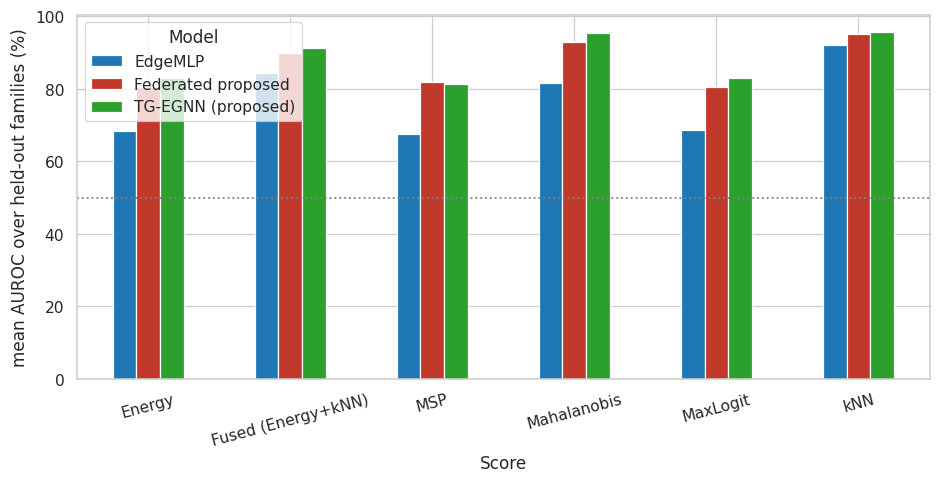


=== Table [T19b_zero_day_robust] Zero-day detection of the purity-robust model on time-ordered and mixed test windows
      Score                          Model / test windows AUROC unseen DoS/DDoS AUROC unseen Recon AUROC unseen Web/Injection AUROC unseen Intrusion/Malware  Mean AUROC  Mean FPR95
     Energy TG-EGNN, time-ordered training / ordered test            60.7 ± 2.0         91.1 ± 3.3                 85.8 ± 1.3                     94.3 ± 1.3   82.988160   37.033814
     Energy          TG-EGNN purity-robust / ordered test            61.3 ± 2.9         92.0 ± 2.7                 91.6 ± 2.6                     92.4 ± 3.2   84.360941   33.681889
     Energy            TG-EGNN purity-robust / mixed test            59.5 ± 3.9         80.6 ± 1.3                 89.0 ± 4.3                     70.0 ± 4.8   74.795931   51.145530
Mahalanobis TG-EGNN, time-ordered training / ordered test            92.7 ± 1.6         97.5 ± 0.6                 95.5 ± 1.1                     95.5 ± 0.5 

,Score,Embedding,Test windows,AUROC unseen DoS/DDoS,AUROC unseen Recon,AUROC unseen Web/Injection,AUROC unseen Intrusion/Malware,Mean AUROC,Mean FPR95
0,Mahalanobis,edge embedding after message passing,ordered,93.5 ± 1.4,97.6 ± 0.1,95.3 ± 1.3,95.6 ± 0.5,95.499389,14.392408
1,Mahalanobis,edge embedding after message passing,mixed,77.8 ± 5.3,70.6 ± 4.3,64.7 ± 4.3,64.8 ± 2.7,69.497500,60.535681
2,Mahalanobis,flow-level embedding (adapter),ordered,96.5 ± 0.2,94.6 ± 0.1,65.7 ± 0.7,75.9 ± 0.3,83.197783,47.120614
3,Mahalanobis,flow-level embedding (adapter),mixed,96.5 ± 0.2,93.6 ± 0.0,60.0 ± 1.2,72.9 ± 0.2,80.763296,50.910350
4,kNN,edge embedding after message passing,ordered,91.7 ± 0.7,97.9 ± 0.4,97.4 ± 1.2,96.7 ± 1.0,95.909592,10.909175
5,kNN,edge embedding after message passing,mixed,66.8 ± 2.4,80.0 ± 2.9,85.1 ± 2.5,70.5 ± 6.7,75.596061,52.905645
6,kNN,flow-level embedding (adapter),ordered,94.4 ± 1.3,92.8 ± 0.4,85.8 ± 1.3,89.4 ± 0.8,90.615769,31.394001
7,kNN,flow-level embedding (adapter),mixed,96.4 ± 0.5,91.0 ± 0.7,78.3 ± 0.8,86.4 ± 1.3,88.019316,35.054410
8,Mahalanobis,"EdgeMLP (per-flow model, reference)",any,NaN,NaN,NaN,NaN,81.646627,49.944138
9,kNN,"EdgeMLP (per-flow model, reference)",any,NaN,NaN,NaN,NaN,92.172298,27.515954


In [28]:
# ============================== 11. ZERO-DAY ==============================
def zd_windows(nm, split, fam):
    ix = ORG[nm][split + "_idx"]; ix = ix[RAW[nm]["y"][ix] != fam]
    return windows_from(ORG[nm]["XQ"][ix], RAW[nm]["y"][ix], RAW[nm]["t"][ix], RAW[nm]["src"][ix], RAW[nm]["dst"][ix], CFG["WIN"])

def zd_scores(model, fam, train_W, test_W=None):
    out = []
    for nm in ORGS:
        Wte = (test_W or {n_: ORG[n_]["te"] for n_ in ORGS})[nm]
        if (np.concatenate([w["y"] for w in Wte]) == fam).sum() == 0: continue
        lg, z, y = predict(model, Wte, nm); _, ztr, ytr = predict(model, train_W[nm][: CFG["ZD_TRAIN_WIN"]], nm)
        rg = np.random.default_rng(0); s = rg.choice(len(ztr), min(len(ztr), 20000), replace=False)
        sc = ood_scores(lg, z, ztr[s], ytr[s])
        out.append({k: ood_eval(v, y == fam) for k, v in sc.items()})
    return {k: {m: np.nanmean([o[k][m] for o in out]) for m in ["AUROC", "AUPR", "FPR95"]} for k in out[0]} if out else {}

ZD = {}
for fam in range(1, len(FAMS)):
    Wtr = {nm: zd_windows(nm, "tr", fam) for nm in ORGS}; Wva = {nm: zd_windows(nm, "va", fam) for nm in ORGS}
    for mn in ["EdgeMLP", PROP]:
        for s in CFG["ZD_SEEDS"]:
            def go(mn=mn, s=s):
                m, _ = train_central(VARIANTS[mn], s, W_train=Wtr, W_val=Wva)
                return zd_scores(m, fam, Wtr)
            ZD[(fam, mn, s)] = cached(f"zd_{fam}_{mn}_s{s}", go)
    if CFG["ZD_FL"]:
        def gofl(fam=fam):
            r = FLRun("Proposed", CFG["K_PER_ORG"], CFG["ZD_SEEDS"][0], exclude_family=fam).run()
            return zd_scores(fl_model(r), fam, Wtr)
        ZD[(fam, "Federated proposed", CFG["ZD_SEEDS"][0])] = cached(f"zd_fl_{fam}_{fl_tag()}", gofl)
SC_NAMES = list(next(v for v in ZD.values() if v).keys())
rows = []
for mn in ["EdgeMLP", PROP] + (["Federated proposed"] if CFG["ZD_FL"] else []):
    seeds = CFG["ZD_SEEDS"] if mn != "Federated proposed" else CFG["ZD_SEEDS"][:1]
    for sc in SC_NAMES:
        r = {"Model": mn, "Score": sc}
        for fam in range(1, len(FAMS)):
            v = [ZD[(fam, mn, s)].get(sc, {}).get("AUROC", np.nan) for s in seeds if ZD.get((fam, mn, s))]
            r[f"AUROC unseen {FAMS[fam]}"] = ms(v, 1)
        r["Mean AUROC"] = np.nanmean([ZD[(f, mn, s)].get(sc, {}).get("AUROC", np.nan) for f in range(1, len(FAMS)) for s in seeds if ZD.get((f, mn, s))])
        r["Mean FPR95"] = np.nanmean([ZD[(f, mn, s)].get(sc, {}).get("FPR95", np.nan) for f in range(1, len(FAMS)) for s in seeds if ZD.get((f, mn, s))])
        rows.append(r)
ZDT = add_table("T19_zero_day", pd.DataFrame(rows), "Zero-day detection (leave-one-family-out): AUROC (%) per held-out family and mean FPR@95%TPR")
fig, ax = plt.subplots(figsize=(10, 4.3))
piv = ZDT.pivot(index="Score", columns="Model", values="Mean AUROC"); piv.plot.bar(ax=ax, color=[PAL[0], PROP_COLOR, PAL[2]][: piv.shape[1]])
ax.axhline(50, ls=":", color="gray"); ax.set_ylabel("mean AUROC over held-out families (%)"); ax.tick_params(axis="x", rotation=15)
save_fig(fig, "F11_zero_day", "Zero-day detection: mean AUROC of each unknown-score per model")

# purity-robust zero-day model: trained on ordered + mixed windows without the held-out family, tested on ordered AND mixed test
# windows (the mixed test windows contain the held-out family, mixed with known traffic)
def zd_mixed(nm, split, fam, s):
    ix = ORG[nm][split + "_idx"]; ix = ix[RAW[nm]["y"][ix] != fam]; ix = ix[np.random.default_rng(2000 + s).permutation(len(ix))]
    return windows_from(ORG[nm]["XQ"][ix], RAW[nm]["y"][ix], RAW[nm]["t"][ix], RAW[nm]["src"][ix], RAW[nm]["dst"][ix], CFG["WIN"])
ZDR = {}
for fam in range(1, len(FAMS)):
    for s in CFG["ZD_SEEDS"]:
        def go_r(fam=fam, s=s):
            Wtr = {nm: zd_windows(nm, "tr", fam) for nm in ORGS}; Wva = {nm: zd_windows(nm, "va", fam) for nm in ORGS}
            Wt = {nm: Wtr[nm] + zd_mixed(nm, "tr", fam, s) for nm in ORGS}; Wv = {nm: Wva[nm] + zd_mixed(nm, "va", fam, s) for nm in ORGS}
            print(f"zero-day purity-robust: held-out {FAMS[fam]}, seed {s}")
            m, _ = train_central(VARIANTS[PROP], s, W_train=Wt, W_val=Wv)
            return dict(ordered=zd_scores(m, fam, Wtr), mixed=zd_scores(m, fam, Wtr, test_W=mixw("te", s)))
        ZDR[(fam, s)] = cached(f"zdr_{fam}_s{s}", go_r)
rows = []
for sc in ["Energy", "Mahalanobis", "kNN"]:
    if sc not in SC_NAMES: continue
    for lab, getv in [("TG-EGNN, time-ordered training / ordered test", lambda f, s_, m: ZD[(f, PROP, s_)].get(sc, {}).get(m, np.nan)),
                      ("TG-EGNN purity-robust / ordered test", lambda f, s_, m: ZDR[(f, s_)]["ordered"].get(sc, {}).get(m, np.nan)),
                      ("TG-EGNN purity-robust / mixed test", lambda f, s_, m: ZDR[(f, s_)]["mixed"].get(sc, {}).get(m, np.nan))]:
        r = {"Score": sc, "Model / test windows": lab}
        for fam in range(1, len(FAMS)): r[f"AUROC unseen {FAMS[fam]}"] = ms([getv(fam, s_, "AUROC") for s_ in CFG["ZD_SEEDS"]], 1)
        r["Mean AUROC"] = np.nanmean([getv(f, s_, "AUROC") for f in range(1, len(FAMS)) for s_ in CFG["ZD_SEEDS"]])
        r["Mean FPR95"] = np.nanmean([getv(f, s_, "FPR95") for f in range(1, len(FAMS)) for s_ in CFG["ZD_SEEDS"]])
        rows.append(r)
add_table("T19b_zero_day_robust", pd.DataFrame(rows), "Zero-day detection of the purity-robust model on time-ordered and mixed test windows")

# ---------- zero-day score from the FLOW-LEVEL embedding of the same model ----------
# The adapter output (before any message passing) describes one flow and does not see the other flows of its window, so a
# zero-day score computed on it cannot exploit window composition. Same purity-robust models as above (retrained and saved).
def predict_flow(model, W, org, bs=None):
    model.eval(); bs = bs or CFG["WIN_BATCH"] * 2; Z, Y = [], []
    with torch.no_grad():
        for i in range(0, len(W), bs):
            b = collate(W[i:i + bs]); Z.append(model.adapters[org](b["x"]).float().cpu().numpy()); Y.append(b["y"].cpu().numpy())
    return np.concatenate(Z), np.concatenate(Y)
def zd_flow_scores(model, fam, train_W, test_W):
    out = []
    for nm in ORGS:
        Wte = test_W[nm]
        if (np.concatenate([w["y"] for w in Wte]) == fam).sum() == 0: continue
        z, y = predict_flow(model, Wte, nm); ztr, ytr = predict_flow(model, train_W[nm][: CFG["ZD_TRAIN_WIN"]], nm)
        rg = np.random.default_rng(0); s_ = rg.choice(len(ztr), min(len(ztr), 20000), replace=False)
        sc = ood_scores(np.zeros((len(z), 2)), z, ztr[s_], ytr[s_]); sc = {k: v for k, v in sc.items() if k in ("Mahalanobis", "kNN")}
        out.append({k: ood_eval(v, y == fam) for k, v in sc.items()})
    return {k: {m: np.nanmean([o[k][m] for o in out]) for m in ["AUROC", "AUPR", "FPR95"]} for k in out[0]} if out else {}
ZDF = {}
for fam in range(1, len(FAMS)):
    for s in CFG["ZD_SEEDS"]:
        def go_f(fam=fam, s=s):
            Wtr = {nm: zd_windows(nm, "tr", fam) for nm in ORGS}; Wva = {nm: zd_windows(nm, "va", fam) for nm in ORGS}
            Wt = {nm: Wtr[nm] + zd_mixed(nm, "tr", fam, s) for nm in ORGS}; Wv = {nm: Wva[nm] + zd_mixed(nm, "va", fam, s) for nm in ORGS}
            print(f"zero-day flow-level: held-out {FAMS[fam]}, seed {s}")
            m, _ = train_central(VARIANTS[PROP], s, W_train=Wt, W_val=Wv); torch.save(m.state_dict(), OUT / "models" / f"zdr_{fam}_s{s}.pt")
            te_o = {nm: ORG[nm]["te"] for nm in ORGS}
            return dict(graph_ordered=zd_scores(m, fam, Wtr), graph_mixed=zd_scores(m, fam, Wtr, test_W=mixw("te", s)),
                        flow_ordered=zd_flow_scores(m, fam, Wtr, te_o), flow_mixed=zd_flow_scores(m, fam, Wtr, mixw("te", s)))
        ZDF[(fam, s)] = cached(f"zdf_{fam}_s{s}", go_f)
rows = []
for sc in ["Mahalanobis", "kNN"]:
    for emb in ["graph", "flow"]:
        for tw in ["ordered", "mixed"]:
            key = f"{emb}_{tw}"
            r = {"Score": sc, "Embedding": "edge embedding after message passing" if emb == "graph" else "flow-level embedding (adapter)",
                 "Test windows": tw}
            for fam in range(1, len(FAMS)): r[f"AUROC unseen {FAMS[fam]}"] = ms([ZDF[(fam, s_)][key].get(sc, {}).get("AUROC", np.nan) for s_ in CFG["ZD_SEEDS"]], 1)
            r["Mean AUROC"] = np.nanmean([ZDF[(f, s_)][key].get(sc, {}).get("AUROC", np.nan) for f in range(1, len(FAMS)) for s_ in CFG["ZD_SEEDS"]])
            r["Mean FPR95"] = np.nanmean([ZDF[(f, s_)][key].get(sc, {}).get("FPR95", np.nan) for f in range(1, len(FAMS)) for s_ in CFG["ZD_SEEDS"]])
            rows.append(r)
for sc in ["Mahalanobis", "kNN"]:
    rows.append({"Score": sc, "Embedding": "EdgeMLP (per-flow model, reference)", "Test windows": "any",
                 "Mean AUROC": np.nanmean([ZD[(f, "EdgeMLP", s_)].get(sc, {}).get("AUROC", np.nan) for f in range(1, len(FAMS)) for s_ in CFG["ZD_SEEDS"]]),
                 "Mean FPR95": np.nanmean([ZD[(f, "EdgeMLP", s_)].get(sc, {}).get("FPR95", np.nan) for f in range(1, len(FAMS)) for s_ in CFG["ZD_SEEDS"]])})
add_table("T19c_zero_day_flow_level", pd.DataFrame(rows), "Zero-day scores from the graph embedding vs. the flow-level embedding of the purity-robust model")


## 8. Adversarial resilience (evasion)
**Feature-space attack under problem-space constraints**: constraint-aware PGD on the features of attack flows only
(indicator features immutable, volume counters may only grow). **Topology camouflage**: the attacker adds `m` benign-looking
flows (copied benign feature vectors) from each attacking host to random hosts in the window, to dilute its neighbourhood.
Defences: centralised PGD adversarial training and **federated adversarial training** (clients craft constrained PGD on
their own data during local training). Metric: detection rate (%) of the original attack flows.


=== Table [T20_adversarial] Attack detection rate (%) under constraint-aware PGD evasion (targeted to 'benign')
                             Model  clean_F1  DR ε=0.0  DR ε=0.01  DR ε=0.03  DR ε=0.05  DR ε=0.1
                           EdgeMLP 83.700756 99.300054  99.198375  98.076468  96.721096 93.451888
                Federated proposed 88.231820 99.120790  99.114565  99.092945  99.026116 98.020609
          Federated proposed + FAT 89.697501 99.895430  99.891090  99.879379  99.868542 99.830788
                TG-EGNN (proposed) 97.873264 99.908195  99.905738  99.897359  99.883183 98.637427
TG-EGNN (proposed) + adv. training 97.719734 99.777327  99.775443  99.775443  99.762995 99.730236

=== Table [T21_camouflage] Attack detection rate (%) under topology camouflage (m benign-looking flows per attacking host)
                             Model    DR m=0    DR m=2    DR m=5   DR m=10
                Federated proposed 99.120790 90.977771 81.107731 69.041367
          Federated propo

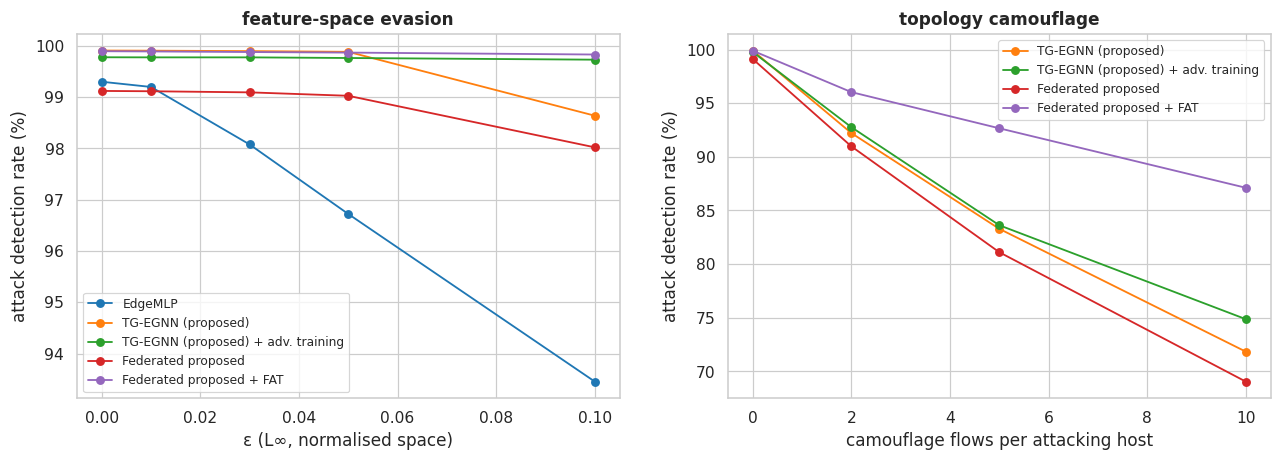


=== Table [T21b_camouflage_defence] Camouflage augmentation as a defence against topology camouflage (centralised, seed 42)
                                                     Model  F1 ordered test  F1 mixed test    DR m=0    DR m=2    DR m=5   DR m=10
                TG-EGNN (proposed) (time-ordered training)        97.873264      60.220144 99.908195 92.216151 83.289131 71.834902
                          TG-EGNN (proposed) purity-robust        96.737109      88.678836 99.953641 93.131470 90.344095 85.052706
TG-EGNN (proposed) purity-robust + camouflage augmentation        98.203552      89.156326 99.921117 99.911371 99.882665 99.846362

=== Table [T21c_camouflage_robustness] Camouflage defence over 3 seeds, including camouflage variants not used in training
                                                     Model F1 ordered test F1 mixed test DR m=10 random DR m=20 random (unseen) DR m=10 victim (unseen) DR m=10 cross (unseen)
                TG-EGNN (proposed) (time-ordered tra

,Model,F1 ordered test,F1 mixed test,DR m=10 random,DR m=20 random (unseen),DR m=10 victim (unseen),DR m=10 cross (unseen)
0,TG-EGNN (proposed) (time-ordered training),96.95 ± 1.14,59.50 ± 0.99,78.14 ± 4.43,68.46 ± 3.30,98.87 ± 0.44,80.46 ± 3.17
1,TG-EGNN (proposed) purity-robust,94.10 ± 2.29,90.19 ± 2.13,83.72 ± 5.09,78.62 ± 7.01,98.67 ± 0.59,84.94 ± 4.86
2,TG-EGNN (proposed) purity-robust + camouflage ...,98.36 ± 0.16,90.24 ± 2.15,99.84 ± 0.08,99.77 ± 0.17,99.91 ± 0.02,98.54 ± 0.59


In [29]:
# ============================== 12. ADVERSARIAL ==============================
def attack_dr(model, nm, eps, camo=0, n_win=None, seed=0):
    rng = np.random.default_rng(seed); Ws = [w for w in ORG[nm]["te"] if (w["y"] != 0).any()][: n_win or CFG["ADV_WIN"]]; det, tot = 0, 0
    for w in Ws:
        w = dict(w)
        if camo:
            atk_src = np.unique(w["src"][w["y"] != 0]); ben = np.where(w["y"] == 0)[0]
            if len(ben):
                add = [(a, rng.integers(0, w["N"]), rng.choice(ben)) for a in atk_src for _ in range(camo)]
                if add:
                    a_, d_, b_ = map(np.array, zip(*add))
                    w = dict(x=np.vstack([w["x"], w["x"][b_]]), y=np.concatenate([w["y"], np.zeros(len(add), np.int64)]),
                             src=np.concatenate([w["src"], a_]), dst=np.concatenate([w["dst"], d_]), N=w["N"], orig=len(w["y"]))
        b = collate([w]); orig = w.get("orig", len(w["y"]))
        m = torch.zeros(len(b["y"]), dtype=torch.bool, device=DEV); m[:orig] = b["y"][:orig] != 0
        if eps > 0:
            def fwd(xa, b=b, m=m):
                bb = dict(b); x = b["x"].clone(); x[m] = xa; bb["x"] = x; return model(bb, nm)[0][m]
            xa = pgd_constrained(fwd, b["x"][m], b["y"][m], ORG_CONS[nm], eps, steps=CFG["ADV_STEPS"], targeted_class=0)
            x = b["x"].clone(); x[m] = xa; b = dict(b); b["x"] = x
        with torch.no_grad(): p = model(b, nm)[0].argmax(1)
        det += (p[m] != 0).sum().item(); tot += m.sum().item()
    return 100 * det / max(tot, 1)

s0 = CFG["ZD_SEEDS"][0]
ADV_MODELS = {"EdgeMLP": load_central("EdgeMLP", s0, VARIANTS["EdgeMLP"]), PROP: load_central(PROP, s0, VARIANTS[PROP])}
def go_at():
    m, _ = train_central(VARIANTS[PROP], s0, epochs=CFG["C_EPOCHS"], adv=dict(p=0.5, eps=max(CFG["ADV_EPS"]) / 2, steps=5))
    torch.save(m.state_dict(), OUT / "models" / "central_AT.pt"); return dict(test=eval_orgs(m, "te"))
AT_RES = cached("central_AT", go_at); m_at = build(VARIANTS[PROP]); m_at.load_state_dict(torch.load(OUT / "models" / "central_AT.pt", map_location=DEV)); ADV_MODELS[PROP + " + adv. training"] = m_at.eval()
FAT = cached(f"fl_FAT_{fl_tag()}", lambda: FLRun("Proposed", CFG["K_PER_ORG"], s0, fat=dict(p=0.5, eps=max(CFG["ADV_EPS"]) / 2, steps=5)).run())
ADV_MODELS["Federated proposed"] = fl_model(FLR[("Proposed", s0)])
ADV_MODELS["Federated proposed + FAT"] = fl_model(FAT)
ADV = []
for mn, md in ADV_MODELS.items():
    clean = {"EdgeMLP": CEN[("EdgeMLP", s0)]["test"], PROP: CEN[(PROP, s0)]["test"], PROP + " + adv. training": AT_RES["test"],
             "Federated proposed": FLR[("Proposed", s0)]["test"], "Federated proposed + FAT": FAT["test"]}[mn]["mean"]["F1"]
    for eps in [0] + CFG["ADV_EPS"]:
        for nm in ORGS:
            ADV.append(dict(Model=mn, eps=eps, camo=0, org=nm, clean_F1=clean, DR=cached(f"adv_{mn}_{eps}_{nm}", lambda: attack_dr(md, nm, eps))))
    if mn != "EdgeMLP":
        for cm in CFG["CAMO_M"][1:]:
            for nm in ORGS: ADV.append(dict(Model=mn, eps=0, camo=cm, org=nm, clean_F1=clean, DR=cached(f"camo_{mn}_{cm}_{nm}", lambda: attack_dr(md, nm, 0, camo=cm))))
ADV = pd.DataFrame(ADV)
t = ADV[ADV.camo == 0].groupby(["Model", "eps"]).agg(clean_F1=("clean_F1", "first"), DR=("DR", "mean")).reset_index().pivot(index=["Model", "clean_F1"], columns="eps", values="DR")
t.columns = [f"DR ε={c}" for c in t.columns]; add_table("T20_adversarial", t.reset_index(), "Attack detection rate (%) under constraint-aware PGD evasion (targeted to 'benign')")
t2 = ADV[(ADV.eps == 0) & (ADV.Model != "EdgeMLP")].groupby(["Model", "camo"]).DR.mean().unstack(); t2.columns = [f"DR m={c}" for c in t2.columns]
add_table("T21_camouflage", t2.reset_index(), "Attack detection rate (%) under topology camouflage (m benign-looking flows per attacking host)")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for i, mn in enumerate(ADV_MODELS):
    d = ADV[(ADV.Model == mn) & (ADV.camo == 0)].groupby("eps").DR.mean(); axes[0].plot(d.index, d.values, "-o", label=mn, color=PAL[i])
    if mn != "EdgeMLP":
        d = ADV[(ADV.Model == mn) & (ADV.eps == 0)].groupby("camo").DR.mean(); axes[1].plot(d.index, d.values, "-o", label=mn, color=PAL[i])
axes[0].set_xlabel("ε (L∞, normalised space)"); axes[0].set_ylabel("attack detection rate (%)"); axes[0].legend(fontsize=8); axes[0].set_title("feature-space evasion")
axes[1].set_xlabel("camouflage flows per attacking host"); axes[1].set_ylabel("attack detection rate (%)"); axes[1].legend(fontsize=8); axes[1].set_title("topology camouflage")
save_fig(fig, "F12_adversarial", "Adversarial resilience: constrained feature-space evasion and topology camouflage")

# ---------- camouflage augmentation (defence against topology camouflage) ----------
# Training windows are augmented with the same manipulation the attacker uses: every attacking host additionally emits m benign-looking
# flows (m drawn from {2, 5, 10}); the decoy flows are labelled benign, so the model can no longer rely on host-level label purity.
def camo_window(w, m, rng):
    atk = np.unique(w["src"][w["y"] != 0]); ben = np.where(w["y"] == 0)[0]
    if len(atk) == 0 or len(ben) == 0 or m == 0: return w
    add = [(a, rng.integers(0, w["N"]), rng.choice(ben)) for a in atk for _ in range(m)]; a_, d_, b_ = map(np.array, zip(*add))
    return dict(x=np.vstack([w["x"], w["x"][b_]]), y=np.concatenate([w["y"], np.zeros(len(add), np.int64)]),
                src=np.concatenate([w["src"], a_]), dst=np.concatenate([w["dst"], d_]), N=w["N"])
def train_robust(kind, s):
    path = OUT / "models" / f"central_{kind}_s{s}.pt"
    def go():
        rng = np.random.default_rng(3000 + s); mt, mv = mixw("tr", s), mixw("va", s)
        Wt = {nm: ORG[nm]["tr"] + mt[nm] for nm in ORGS}; Wv = {nm: ORG[nm]["va"] + mv[nm] for nm in ORGS}
        if kind == "camo":
            Wt = {nm: Wt[nm] + [camo_window(w, int(rng.choice([2, 5, 10])), rng) for w in ORG[nm]["tr"]] for nm in ORGS}
            Wv = {nm: Wv[nm] + [camo_window(w, int(rng.choice([2, 5, 10])), rng) for w in ORG[nm]["va"]] for nm in ORGS}
        print(f"training {kind} model, seed {s}")
        m, _ = train_central(VARIANTS[PROP], s, W_train=Wt, W_val=Wv); torch.save(m.state_dict(), path)
        return dict(ordered=eval_orgs(m, "te"), mixed=eval_orgs(m, W_override=mixw("te", s)))
    r = cached(f"robust_{kind}_s{s}", go); m = build(VARIANTS[PROP]); m.load_state_dict(torch.load(path, map_location=DEV)); return r, m.eval()
rows = []
for kind, lab in [("aug", PROP + " purity-robust"), ("camo", PROP + " purity-robust + camouflage augmentation")]:
    r, md = train_robust(kind, s0)
    row = {"Model": lab, "F1 ordered test": r["ordered"]["mean"]["F1"], "F1 mixed test": r["mixed"]["mean"]["F1"]}
    for cm in CFG["CAMO_M"]:
        row[f"DR m={cm}"] = np.mean([cached(f"camo_{kind}_{cm}_{nm}_s{s0}", lambda: attack_dr(md, nm, 0, camo=cm)) for nm in ORGS])
    rows.append(row)
base = {"Model": PROP + " (time-ordered training)", "F1 ordered test": CEN[(PROP, s0)]["test"]["mean"]["F1"], "F1 mixed test": STRESS[("a", PROP, s0)]["mean"]["F1"]}
for cm in CFG["CAMO_M"]: base[f"DR m={cm}"] = ADV[(ADV.Model == PROP) & (ADV.eps == 0) & (ADV.camo == cm)].DR.mean()
add_table("T21b_camouflage_defence", pd.DataFrame([base] + rows), f"Camouflage augmentation as a defence against topology camouflage (centralised, seed {s0})")

# ---------- camouflage defence: three seeds and camouflage variants NOT used in training ----------
def camo_dr(model, nm, m, mode, seed=0):
    """mode: 'random' = decoys to random hosts (as in training); 'victim' = decoys to the hosts the attacker already targets;
    'cross' = decoy features taken from benign flows of OTHER test windows (not from the attacked window)."""
    rng = np.random.default_rng(seed); Ws = [w for w in ORG[nm]["te"] if (w["y"] != 0).any()][: CFG["ADV_WIN"]]; det, tot = 0, 0
    pool = np.vstack([w["x"][w["y"] == 0] for w in ORG[nm]["te"][:200] if (w["y"] == 0).any()])
    for w in Ws:
        atk_idx = np.where(w["y"] != 0)[0]; atk = np.unique(w["src"][atk_idx]); ben = np.where(w["y"] == 0)[0]
        add_x, add_s, add_d = [], [], []
        for a in atk:
            vict = np.unique(w["dst"][atk_idx][w["src"][atk_idx] == a])
            for _ in range(m):
                if mode == "cross": add_x.append(pool[rng.integers(len(pool))])
                else:
                    if len(ben) == 0: continue
                    add_x.append(w["x"][rng.choice(ben)])
                add_s.append(a); add_d.append(rng.choice(vict) if mode == "victim" else rng.integers(0, w["N"]))
        orig = len(w["y"])
        if add_x:
            w = dict(x=np.vstack([w["x"], np.stack(add_x)]), y=np.concatenate([w["y"], np.zeros(len(add_x), np.int64)]),
                     src=np.concatenate([w["src"], add_s]), dst=np.concatenate([w["dst"], add_d]), N=w["N"])
        b = collate([w]); msk = torch.zeros(len(b["y"]), dtype=torch.bool, device=DEV); msk[:orig] = b["y"][:orig] != 0
        with torch.no_grad(): p = model(b, nm)[0].argmax(1)
        det += (p[msk] != 0).sum().item(); tot += msk.sum().item()
    return 100 * det / max(tot, 1)
CAMO_TESTS = [(10, "random"), (20, "random"), (10, "victim"), (10, "cross")]
rows = []
for kind, lab in [("plain", PROP + " (time-ordered training)"), ("aug", PROP + " purity-robust"), ("camo", PROP + " purity-robust + camouflage augmentation")]:
    per = {t: [] for t in CAMO_TESTS}; fo, fm = [], []
    for s in CFG["CAMO_SEEDS"]:
        if kind == "plain":
            md = load_central(PROP, s, VARIANTS[PROP]); fo.append(CEN[(PROP, s)]["test"]["mean"]["F1"]); fm.append(STRESS[("a", PROP, s)]["mean"]["F1"])
        else:
            r, md = train_robust(kind, s); fo.append(r["ordered"]["mean"]["F1"]); fm.append(r["mixed"]["mean"]["F1"])
        for (m_, mode) in CAMO_TESTS:
            per[(m_, mode)].append(np.mean([cached(f"camo2_{kind}_{m_}_{mode}_{nm}_s{s}", lambda: camo_dr(md, nm, m_, mode, seed=s)) for nm in ORGS]))
    row = {"Model": lab, "F1 ordered test": ms(fo), "F1 mixed test": ms(fm)}
    for (m_, mode) in CAMO_TESTS: row[f"DR m={m_} {mode}" + (" (unseen)" if (m_, mode) != (10, "random") else "")] = ms(per[(m_, mode)])
    rows.append(row)
add_table("T21c_camouflage_robustness", pd.DataFrame(rows), f"Camouflage defence over {len(CFG['CAMO_SEEDS'])} seeds, including camouflage variants not used in training")


## 9. Resource constraints
CPU measurements with **one thread** (a proxy for a gateway-class device; absolute times on a real device will differ and
must be measured there): parameters, model size (fp32 and dynamic int8), latency per window and per flow, activation memory,
multiply-accumulates, and the macro-F1 of the int8 model.


=== Table [T22_resources] Resource profile on one CPU thread (gateway proxy)
             Model Organisation  Params (shared)  Params (own adapter)  Size fp32 (KB)  Size int8 (KB)  Flows / window  Latency / window fp32 (ms)  p95 (ms)  Latency / window int8 (ms)  µs / flow (fp32)  Activations (MB)  MMACs / window   F1 fp32   F1 int8
           EdgeMLP      TON_IoT            16901                  8448      123.124023       39.401367            1024                    1.544301  1.775934                    2.168633          1.508107          2.641920       25.690112 91.414655 91.420990
           EdgeMLP Edge-IIoTset            16901                  2560      123.124023       39.401367            1024                    1.587695  2.674218                    2.020133          1.550483          2.641920       19.660800 81.836331 81.788757
           EdgeMLP      BoT-IoT            16901                  2496      123.124023       39.401367            1024                    0.917106  1.0

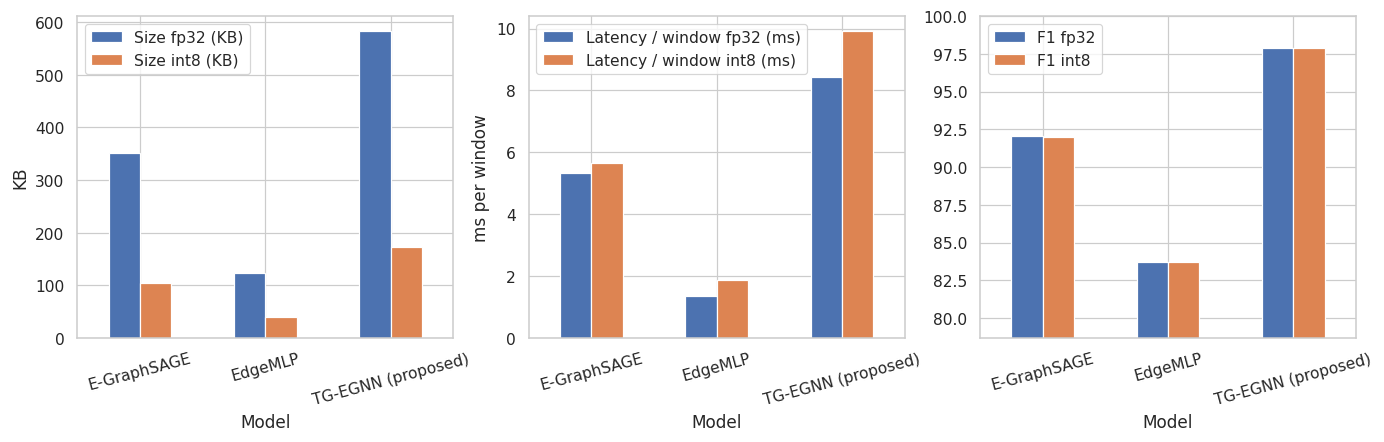

In [30]:
# ============================== 13. RESOURCES ==============================
torch.set_num_threads(1); DEV_SAVE = DEV; rows = []
def collate_cpu(ws):
    global DEV
    d = DEV; DEV = torch.device("cpu")
    try: return collate(ws)
    finally: DEV = d
for mn in ["EdgeMLP", "E-GraphSAGE", PROP]:
    m = load_central(mn, s0, VARIANTS[mn]).cpu().eval(); mq = quantize_int8(m)
    for nm in ORGS[:1] if CFG["SELF_TEST"] else ORGS:
        b = collate_cpu([ORG[nm]["te"][0]]); E = len(b["y"])
        lat, lat95 = latency_ms(lambda: m(b, nm), reps=CFG["LAT_REPS"]); latq, _ = latency_ms(lambda: mq(b, nm), reps=CFG["LAT_REPS"])
        DEV = torch.device("cpu"); f1q = eval_orgs(mq)[nm]["F1"]; f1 = eval_orgs(m)[nm]["F1"]; DEV = DEV_SAVE
        rows.append({"Model": mn, "Organisation": nm, "Params (shared)": sum(p.numel() for n, p in m.named_parameters() if not n.startswith("adapters.")),
                     "Params (own adapter)": sum(p.numel() for n, p in m.named_parameters() if n.startswith(f"adapters.{nm}.")),
                     "Size fp32 (KB)": state_bytes(m) / 1024, "Size int8 (KB)": state_bytes(mq) / 1024, "Flows / window": E,
                     "Latency / window fp32 (ms)": lat, "p95 (ms)": lat95, "Latency / window int8 (ms)": latq, "µs / flow (fp32)": 1000 * lat / E,
                     "Activations (MB)": activation_bytes(m, lambda: m(b, nm)) / 1e6, "MMACs / window": macs_linear_conv(m, lambda: m(b, nm)) / 1e6,
                     "F1 fp32": f1, "F1 int8": f1q})
DEV = DEV_SAVE; [mm.to(DEV) for mm in ADV_MODELS.values()]
add_table("T22_resources", pd.DataFrame(rows), "Resource profile on one CPU thread (gateway proxy)")
R_ = pd.DataFrame(rows).groupby("Model").mean(numeric_only=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
R_[["Size fp32 (KB)", "Size int8 (KB)"]].plot.bar(ax=axes[0]); axes[0].set_ylabel("KB")
R_[["Latency / window fp32 (ms)", "Latency / window int8 (ms)"]].plot.bar(ax=axes[1]); axes[1].set_ylabel("ms per window")
R_[["F1 fp32", "F1 int8"]].plot.bar(ax=axes[2]); axes[2].set_ylim(max(0, R_[["F1 fp32", "F1 int8"]].values.min() - 5), 100)
for ax in axes: ax.tick_params(axis="x", rotation=15)
save_fig(fig, "F13_resources", "Model size, CPU latency and int8 accuracy")
torch.set_num_threads(os.cpu_count() or 1)

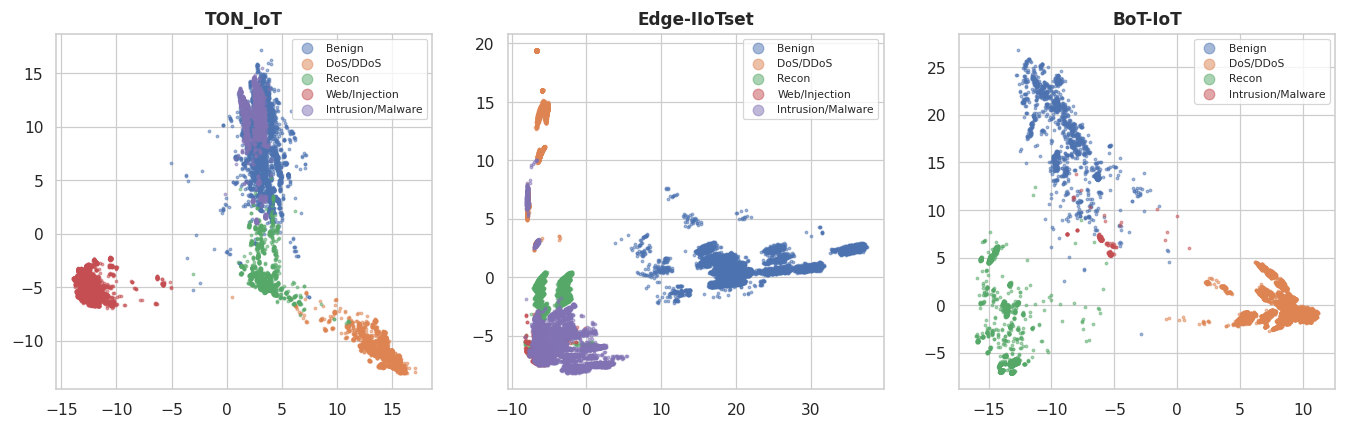


=== Table [T23_capabilities] Where each requirement is evaluated
           Requirement                                                                                                                                      Evidence                                      Table
           Scalability                                                                                                                     30–300 clients, 3–12 fogs                                   T12, T13
 Privacy-preserving FL                       secure aggregation (exactness + cost), client-level DP with RDP accounting, clip tuning and population sweep, MIA audit                                    T14–T16
         Fog computing                                             organisation-aware fog tier: private adapters, reputation filtering, SA-compatible sparsification                                   T08, T11
  Resource constraints                                                                  1-thread CPU l

In [31]:
# ============================== 14. EMBEDDINGS, CAPABILITY SUMMARY, EXPORT ==============================
from sklearn.decomposition import PCA
fig, axes = plt.subplots(1, len(ORGS), figsize=(5 * len(ORGS), 4.2))
for ax, nm in zip(np.atleast_1d(axes), ORGS):
    _, z, y = predict(ADV_MODELS[PROP], ORG[nm]["te"][:40], nm); p = PCA(2, random_state=0).fit_transform(z)
    for c in np.unique(y): ax.scatter(p[y == c, 0], p[y == c, 1], s=3, alpha=0.5, label=FAMS[c])
    ax.set_title(nm); ax.legend(markerscale=4, fontsize=7)
save_fig(fig, "F14_embeddings", "PCA of the edge embeddings of the proposed model (test windows)")

def g_(d, *k):
    for kk in k: d = d[kk]
    return d
summary = pd.DataFrame([
    {"Requirement": "Scalability", "Evidence": f"{min(CFG['SCALE_K'])*len(ORGS)}–{max(CFG['SCALE_K'])*len(ORGS)} clients, {min(CFG['SCALE_FOGS'])*len(ORGS)}–{max(CFG['SCALE_FOGS'])*len(ORGS)} fogs", "Table": "T12, T13"},
    {"Requirement": "Privacy-preserving FL", "Evidence": "secure aggregation (exactness + cost), client-level DP with RDP accounting, clip tuning and population sweep, MIA audit", "Table": "T14–T16"},
    {"Requirement": "Fog computing", "Evidence": "organisation-aware fog tier: private adapters, reputation filtering, SA-compatible sparsification", "Table": "T08, T11"},
    {"Requirement": "Resource constraints", "Evidence": "1-thread CPU latency, int8 size/accuracy, activations, MACs, WAN/LAN traffic", "Table": "T08, T22"},
    {"Requirement": "Zero-day attacks", "Evidence": "leave-one-family-out, 6 scores, centralised + federated, purity-robust model on ordered and mixed windows", "Table": "T19, T19b, T19c"},
    {"Requirement": "Adversarial resilience", "Evidence": f"constrained PGD evasion, topology camouflage (+ camouflage augmentation), AT and federated AT; {len(CFG['BYZ_ATTACKS'])} poisoning attacks × {len(CFG['BYZ_FRACS'])} fractions × {len(CFG['BYZ_DEFENSES'])} defences", "Table": "T17, T17b, T17c, T18, T20, T21, T21b, T21c"},
])
add_table("T23_capabilities", summary, "Where each requirement is evaluated")
idx = pd.DataFrame([{"No.": f"Table {i+1}", "Name": k, "Caption": v[0]} for i, (k, v) in enumerate(TABLES.items())] +
                   [{"No.": f"Figure {i+1}", "Name": k, "Caption": v} for i, (k, v) in enumerate(FIGS.items())])
idx.to_csv(OUT / "index_of_tables_and_figures.csv", index=False)
with pd.ExcelWriter(OUT / "all_tables.xlsx") as xw:
    for k, (cap, df) in TABLES.items(): df.to_excel(xw, sheet_name=k[:31], index=False)
json.dump(dict(CFG={k: (v if not isinstance(v, float) or np.isfinite(v) else str(v)) for k, v in CFG.items()},
               torch=torch.__version__, device=str(DEV), python=sys.version.split()[0]), open(OUT / "run_config.json", "w"), indent=2, default=str)
shutil.make_archive(str(OUT.parent / (OUT.name + "_export")), "zip", OUT, ".")
print(f"Done. {len(TABLES)} tables, {len(FIGS)} figures -> {OUT}")